<a href="https://colab.research.google.com/github/Kunalpatel-08/AirbnbEDA-Project/blob/main/Bank_Term_Deposit_Prediction_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Bank Term-Deposit Subscription Prediction**    -

##### **Project Type**    - Classification ML

##### **Contribution**    - Individual

# **Project Summary -**

This project builds a propensity model for a Portuguese bank's phone-based term-deposit campaign: given everything
known about a client **before** a call is placed, predict whether they will subscribe (`y`). The raw file has
45,211 rows, 17 columns, no formal NULLs and an 11.7% subscription rate. Two things dominate the data and shape
every later decision. First, `duration` (the length of the call that has just happened) is a textbook leakage
feature: on its own it reaches essentially the same test ROC-AUC (~0.80) as all 16 legitimate pre-call features
combined, because a call that never happens cannot be long - it is not knowable at scoring time and is therefore
excluded from the deployable model (kept only for a dedicated with-vs-without benchmark). Second, the file is in
strict chronological order (May 2008 - November 2010), and the subscription rate drifts from 5.8% in the first 70%
of rows to 25.4% in the last 30% - a real concept/population shift, not just an artefact of imbalance, which the
Population Stability Index (PSI) section quantifies directly.

After EDA (16 charts covering univariate, bivariate and multivariate views) and three formal hypothesis tests
(housing loan, balance, and contact channel vs. subscription, all statistically significant at p<0.05), the
pre-call feature set is engineered and screened with Weight-of-Evidence (WOE) binning and Information Value (IV).
`poutcome` (IV≈0.51), `pdays_clean` (IV≈0.35) and `contact` (IV≈0.29) carry the most signal; the engineered
`n_loans` (count of active housing+personal loans) replaces the raw `housing`/`loan` columns once cross-checked for
redundancy (Cramer's V = 0.88 between them), and `previous` is dropped after its WOE coefficient flips sign once
`pdays_clean` and `poutcome` are in the model - a standard scorecard multicollinearity symptom.

Three models are trained on an 80/20 stratified split with 5-fold (Model 1) and 3-fold (Models 2-3) cross-validation:
a WOE + Logistic Regression scorecard model (interpretable, deployable as points), a Random Forest, and an XGBoost
classifier, each with a baseline and a hyperparameter-tuned version. Beyond the usual accuracy/precision/recall/
ROC-AUC/PR-AUC, the project adds the toolkit a real deployment would need: **decile analysis** and cumulative-gains
curves to show how much of the target audience the top-scored clients capture; **cost-aware threshold tuning** that
picks the call-or-not cut-off by expected profit (call cost vs. value of a subscriber) rather than the default 0.5;
**PSI** computed two ways (train/test split, as an integrity check, and early/late campaign period, as a genuine
stability test) plus an explicit out-of-time simulation that trains on the early period and scores the late period;
a **duration-vs-no-duration** comparison that puts a number on how much "performance" the leaky feature would
manufacture on paper; and a **model scorecard summary** with RAG (red/amber/green) status across discrimination,
rank-ordering, calibration, stability and business value. The final model is selected by cross-validated ROC-AUC
on the training rows only (never by peeking at the test set), then judged - and its threshold recalibrated - out of
time, which is the honest way to answer whether this model would still work after go-live.

# **GitHub Link -**

*Add your repository link here before submitting, e.g. `https://github.com/<your-username>/bank-term-deposit-propensity`.*

# **Problem Statement**

A Portuguese retail bank runs outbound telemarketing campaigns to sell term deposits. Every phone contact costs
staff time regardless of outcome, and only ~11.7% of contacted clients say yes. The bank wants a model that, using
only information available **before** a client is called (demographics, financial profile, and the outcome of any
prior campaign), ranks clients by their likelihood of subscribing - so call lists can be prioritised, the campaign
can be run more cheaply, and the resulting model can be trusted not to degrade unnoticed once it goes live.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, brier_score_loss, log_loss, roc_curve,
                             precision_recall_curve, confusion_matrix)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import joblib
from xgboost import XGBClassifier            # pip install xgboost  (pre-installed on Google Colab)

# ---- Global settings -------------------------------------------------------------------------
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
COL_NO, COL_YES = "#7A8CA5", "#E4572E"        # consistent colours: non-subscriber / subscriber

RANDOM_STATE = 42
FAST_MODE = os.environ.get("BANK_FAST", "0") == "1"   # True => tiny hyper-parameter searches (smoke test only)
np.random.seed(RANDOM_STATE)
print("Libraries loaded | FAST_MODE =", FAST_MODE)

Libraries loaded | FAST_MODE = False


### Dataset Loading

In [ ]:
# # Load Dataset  (the file is ';'-separated). Several candidate paths are tried so the notebook runs
# # unchanged on a laptop, Google Colab or a mounted Drive.
# CANDIDATE_PATHS = ["bank-full.csv", "/content/bank-full.csv", "/content/drive/MyDrive/bank-full.csv",
#                    "/mnt/user-data/uploads/bank-full.csv"]
# DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)
# if DATA_PATH is None:
#     raise FileNotFoundError("bank-full.csv not found - upload it next to the notebook (Colab: /content) and re-run.")
# raw = pd.read_csv(DATA_PATH, sep=";")
# print(f"Loaded: {DATA_PATH}")

In [ ]:
# Load the Dataset from GitHub Repo :

# 1. Store GitHub raw dataset URL
DATASET_URL = "https://raw.githubusercontent.com/Kunalpatel-08/Bank-Marketing-Effectiveness-Prediction/refs/heads/main/bank-full.csv"

# 2. Define a local filename fallback
LOCAL_FILE = "bank-full.csv"

# 3. Load dataset with semicolon separator
try:
    print("Loading dataset from GitHub...")
    raw = pd.read_csv(DATASET_URL, sep=';')   # # sep=';' tells pandas to split columns by semicolons instead of commas
    print("Dataset loaded successfully from GitHub!")
except Exception as e:
    print(f"Error loading from GitHub: {e}")
    if os.path.exists(LOCAL_FILE):
        print("Loading from local fallback...")
        raw = pd.read_csv(LOCAL_FILE, sep=';')

Loading dataset from GitHub...
Dataset loaded successfully from GitHub!


### Dataset First View

In [ ]:
# Dataset First Look
raw.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
print(f"Rows    : {raw.shape[0]:,}")
print(f"Columns : {raw.shape[1]}")

Rows    : 45,211
Columns : 17


### Dataset Information

In [ ]:
# Dataset Info
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
print("Fully duplicated rows:", raw.duplicated().sum())

Fully duplicated rows: 0


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
nulls = raw.isnull().sum()
print(nulls.to_string())
print("\nTotal null cells:", int(nulls.sum()))

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0

Total null cells: 0


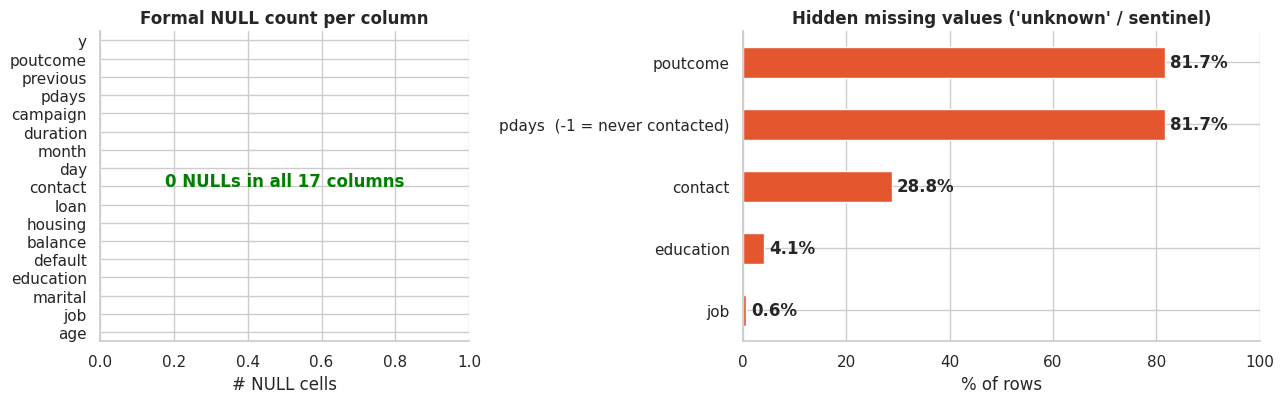

In [ ]:
# Visualizing the missing values
# The file has no NULLs, but missingness is often *encoded*: text columns use the literal 'unknown'
# and pdays uses the sentinel -1 (= client never contacted before). Both are "hidden missing" values.
cat_cols_raw = raw.select_dtypes(exclude="number").columns.drop("y")
hidden = raw[cat_cols_raw].eq("unknown").mean() * 100
hidden["pdays  (-1 = never contacted)"] = raw["pdays"].eq(-1).mean() * 100
hidden = hidden[hidden > 0].sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2),gridspec_kw={"width_ratios": [1, 1.4]})
nulls.sort_values().plot.barh(ax=ax[0], color=COL_NO)
ax[0].set(title="Formal NULL count per column", xlabel="# NULL cells"); ax[0].set_xlim(0, 1)
ax[0].text(0.5, 8, "0 NULLs in all 17 columns", ha="center", fontsize=12, fontweight="bold", color="green")
hidden.plot.barh(ax=ax[1], color=COL_YES)
for i, v in enumerate(hidden.values): ax[1].text(v + 1, i, f"{v:.1f}%", va="center", fontweight="bold")
ax[1].set(title="Hidden missing values ('unknown' / sentinel)", xlabel="% of rows"); ax[1].set_xlim(0, 100)
plt.tight_layout(); plt.show()

### What did you know about your dataset?

- **45,211 rows, 17 columns, target `y`** (yes/no, 11.70% positive, i.e ~7.5:1 class imbalance).
- **No formal NULLs and no duplicate rows** - but missingness is *hidden* behind sentinel values: `poutcome`
  and `pdays` are "unknown"/`-1` for 81.7% of clients (never contacted in a previous campaign), `contact` is
  "unknown" for 28.8%, and `job`/`education` have small "unknown" shares too.
- **The file is in chronological order** (verified: `month` forms 30 contiguous blocks running May 2008 ->
  November 2010), which is essential context - it is what makes the PSI / out-of-time section meaningful rather
  than academic.
- **`duration` is a post-outcome field** (call length is only known once the call has ended, so it cannot be used
  by a model that must decide *whether to call in the first place*) - flagged immediately and handled explicitly
  throughout rather than silently included.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
print(list(raw.columns))

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


In [ ]:
# Dataset Describe
display(raw.describe().T)
display(raw.describe(exclude="number").T)

,count,mean,std,min,25%,50%,75%,max
age,"45,211.0000",40.9362,10.6188,18.0000,33.0000,39.0000,48.0000,95.0000
balance,"45,211.0000","1,362.2721","3,044.7658","-8,019.0000",72.0000,448.0000,"1,428.0000","102,127.0000"
day,"45,211.0000",15.8064,8.3225,1.0000,8.0000,16.0000,21.0000,31.0000
duration,"45,211.0000",258.1631,257.5278,0.0000,103.0000,180.0000,319.0000,"4,918.0000"
campaign,"45,211.0000",2.7638,3.0980,1.0000,1.0000,2.0000,3.0000,63.0000
pdays,"45,211.0000",40.1978,100.1287,-1.0000,-1.0000,-1.0000,-1.0000,871.0000
previous,"45,211.0000",0.5803,2.3034,0.0000,0.0000,0.0000,0.0000,275.0000


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


### Variables Description

| Column | Type | Meaning |
|---|---|---|
| age | numeric | client's age in years |
| job | categorical | occupation (12 levels) |
| marital | categorical | marital status |
| education | categorical | education level |
| default | categorical | has credit in default? |
| balance | numeric | average yearly account balance (EUR) |
| housing | categorical | has a housing loan? |
| loan | categorical | has a personal loan? |
| contact | categorical | contact communication type (cellular/telephone/unknown) |
| day | numeric | last contact day of the month |
| month | categorical | last contact month of year |
| duration | numeric | last contact duration, in seconds - **post-call, not usable pre-call** |
| campaign | numeric | number of contacts performed during this campaign for this client |
| pdays | numeric | days since last contact from a previous campaign; -1 = never contacted |
| previous | numeric | number of contacts before this campaign |
| poutcome | categorical | outcome of the previous marketing campaign |
| y | binary target | did the client subscribe to a term deposit? |

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
uniq = pd.DataFrame({"dtype": raw.dtypes.astype(str), "n_unique": raw.nunique(),
                     "example_values": [raw[c].drop_duplicates().head(6).tolist() for c in raw.columns]})
uniq

,dtype,n_unique,example_values
age,int64,77,"[58, 44, 33, 47, 35, 28]"
job,object,12,"[management, technician, entrepreneur, blue-co..."
marital,object,3,"[married, single, divorced]"
education,object,4,"[tertiary, secondary, unknown, primary]"
default,object,2,"[no, yes]"
balance,int64,7168,"[2143, 29, 2, 1506, 1, 231]"
housing,object,2,"[yes, no]"
loan,object,2,"[no, yes]"
contact,object,3,"[unknown, cellular, telephone]"
day,int64,31,"[5, 6, 7, 8, 9, 12]"


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,pdays_clean,prev_contacted,n_loans,balance_negative,balance_slog,campaign_capped,age_group,row_id,period
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,0,NaN,0,1,0,7.6704,1,55-64,0,early (first 70% of rows)
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,0,NaN,0,1,0,3.4012,1,35-44,1,early (first 70% of rows)
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,0,NaN,0,2,0,1.0986,1,25-34,2,early (first 70% of rows)
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,0,NaN,0,1,0,7.3179,1,45-54,3,early (first 70% of rows)
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,0,NaN,0,0,0,0.6931,1,25-34,4,early (first 70% of rows)


In [ ]:
# Write your code to make your dataset analysis ready.
df = raw.copy()

# 1) Target -> 0/1
df["y"] = (df["y"] == "yes").astype(int)

# 2) pdays sentinel: -1 means "not previously contacted". Keep the information in two honest features:
#    a NaN-able "days since last contact" and an explicit binary flag.
df["pdays_clean"]    = df["pdays"].replace(-1, np.nan)
df["prev_contacted"] = df["pdays"].ne(-1).astype(int)

# 3) Engineered features (all derivable BEFORE the call is made)
df["n_loans"]          = ((df["housing"] == "yes").astype(int) + (df["loan"] == "yes").astype(int)).astype(str)  # 0/1/2 debts
df["balance_negative"] = (df["balance"] < 0).astype(int)
df["balance_slog"]     = np.sign(df["balance"]) * np.log1p(df["balance"].abs())      # for exploration only
df["campaign_capped"]  = df["campaign"].clip(upper=df["campaign"].quantile(0.99))    # for exploration only
df["age_group"]        = pd.cut(df["age"], [17, 24, 34, 44, 54, 64, 120],
                                labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"])

# 4) Chronology. The UCI file is ordered by date (May-2008 -> Nov-2010). Verify instead of assuming:
df["row_id"] = np.arange(len(df))
month_blocks = (df["month"] != df["month"].shift()).cumsum()
print(f"Reading top-to-bottom the 'month' column forms {month_blocks.nunique()} contiguous calendar-month blocks "
      f"(first: {df['month'].iloc[0]}, last: {df['month'].iloc[-1]}) -> row order is chronological.")
# 'period' is used ONLY for the stability (PSI) analysis - never as a model feature.
df["period"] = np.where(df["row_id"] < 0.7 * len(df), "early (first 70% of rows)", "late (last 30% of rows)")

MONTH_ORDER = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
BASE_RATE = df["y"].mean()

def rate_table(data, col, order=None):
    """Customers / subscribers / subscription-rate per level of `col`."""
    t = data.groupby(col, observed=True)["y"].agg(customers="size", subscribers="sum", rate="mean")
    return t.reindex(order) if order is not None else t

# 5) Model inputs.  `duration` is kept in the frame only for the duration-vs-no-duration experiment.
CAT_FEATURES = ["job", "marital", "education", "default", "n_loans", "contact", "month", "poutcome"]
NUM_FEATURES = ["age", "balance", "day", "campaign", "pdays_clean"]
LEAKY        = ["duration"]
# 'housing', 'loan' and 'previous' are deliberately EXCLUDED from the deployable feature set (see Feature
# Selection, sec. 6.4): 'housing'+'loan' are perfectly summarised by the engineered 'n_loans' (Cramer's V = 0.88,
# keeping all three is circular double-counting), and 'previous' flips sign under WOE once 'pdays_clean' and
# 'poutcome' are in the model (classic scorecard multicollinearity). They are kept as columns (EDA_EXTRA) purely
# for exploration and for the "engineered vs. raw" IV comparison - never passed to any fitted model.
EDA_EXTRA    = ["housing", "loan", "previous"]

print(f"\nBase subscription rate: {BASE_RATE:.2%}   |   analysis-ready shape: {df.shape}")
df[["age","job","balance","pdays","pdays_clean","prev_contacted","n_loans","balance_negative","age_group","y"]].head()

Reading top-to-bottom the 'month' column forms 30 contiguous calendar-month blocks (first: may, last: nov) -> row order is chronological.

Base subscription rate: 11.70%   |   analysis-ready shape: (45211, 26)


,age,job,balance,pdays,pdays_clean,prev_contacted,n_loans,balance_negative,age_group,y
0,58,management,2143,-1,NaN,0,1,0,55-64,0
1,44,technician,29,-1,NaN,0,1,0,35-44,0
2,33,entrepreneur,2,-1,NaN,0,2,0,25-34,0
3,47,blue-collar,1506,-1,NaN,0,1,0,45-54,0
4,33,unknown,1,-1,NaN,0,0,0,25-34,0


### What all manipulations have you done and insights you found?

- Target mapped to 0/1. `pdays`'s -1 sentinel is split into an honest `pdays_clean` (NaN when never contacted)
  and a binary `prev_contacted` flag, since -1 is not really "zero days" - it is "not applicable".
- Engineered `n_loans` (0/1/2 = count of housing + personal loans), `balance_negative`, a signed-log transform of
  balance for skew diagnostics, a winsorised campaign count for plotting, and an `age_group` band.
- Chronological order confirmed and stored as `period` (`early` = first 70% of rows, `late` = last 30%) - used
  **only** in the PSI section, never as a model input.
- The deployable feature set (`FEATS`) deliberately excludes `duration` (leakage), and - after the checks in
  Section 6 - also excludes `housing`, `loan` and `previous` (redundant with `n_loans` and unstable under WOE);
  those three are kept in the working frame for exploration only.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

> Charts follow the **UBM** rule: **U**nivariate (1-5) -> **B**ivariate (6-11) -> **M**ultivariate (12-15), plus a bonus timeline chart (16) that motivates the stability analysis later on. Charts use the full dataset for *exploration only*; every learned transformation in the modelling sections is fitted on the training split.

#### Chart - 1 - Target distribution (Univariate)

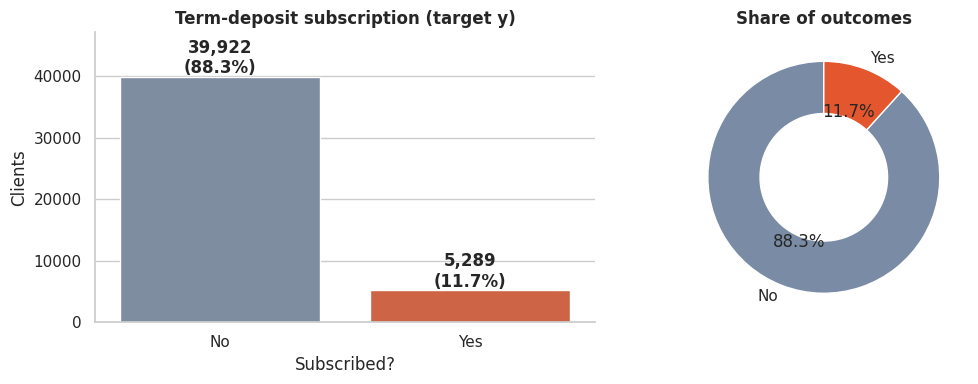

Imbalance ratio  No : Yes = 7.5 : 1


In [ ]:
# Chart - 1 visualization code

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = df["y"].map({0: "No", 1: "Yes"}).value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette={"No": COL_NO, "Yes": COL_YES}, legend=False, ax=ax[0])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 500, f"{v:,}\n({v/len(df):.1%})", ha="center", fontweight="bold")
ax[0].set(title="Term-deposit subscription (target y)", xlabel="Subscribed?", ylabel="Clients"); ax[0].set_ylim(0, counts.max() * 1.18)
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90, colors=[COL_NO, COL_YES],
          wedgeprops=dict(width=0.45, edgecolor="white"))
ax[1].set_title("Share of outcomes")
plt.tight_layout(); plt.show()
print(f"Imbalance ratio  No : Yes = {counts['No']/counts['Yes']:.1f} : 1")

##### 1. Why did you pick the specific chart?

A bar + pie combo is the simplest, least ambiguous way to show a binary target's split and its exact imbalance ratio.

##### 2. What is/are the insight(s) found from the chart?

Only 11.7% of contacted clients subscribed - a 7.5:1 imbalance. Accuracy alone would be a misleading metric here (predicting 'no' for everyone already scores 88.3%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: confirms the campaign is inherently low-hit-rate, which is exactly why a propensity model with cost-aware targeting (Section 8.2) has room to add value over blanket calling.

#### Chart - 2 - Age distribution (Univariate)

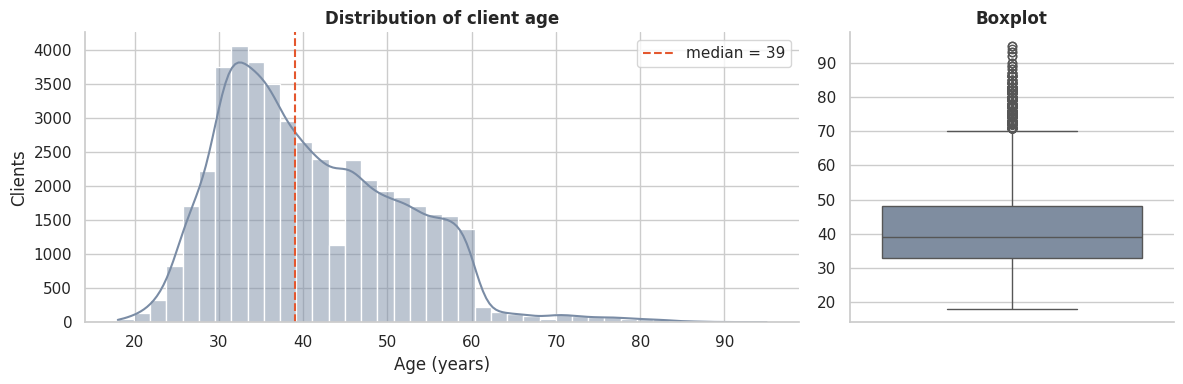

count   45,211.0000
mean        40.9000
std         10.6000
min         18.0000
25%         33.0000
50%         39.0000
75%         48.0000
max         95.0000


In [ ]:
# Chart - 2 visualization code

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2.2, 1]})
sns.histplot(df["age"], bins=40, kde=True, color=COL_NO, ax=ax[0])
ax[0].axvline(df["age"].median(), color=COL_YES, ls="--", label=f"median = {df['age'].median():.0f}")
ax[0].set(title="Distribution of client age", xlabel="Age (years)", ylabel="Clients"); ax[0].legend()
sns.boxplot(y=df["age"], color=COL_NO, ax=ax[1]); ax[1].set(title="Boxplot", ylabel="")
plt.tight_layout(); plt.show()
print(df["age"].describe().round(1).to_string())

##### 1. Why did you pick the specific chart?

A histogram+KDE shows the overall shape of the age distribution, and a boxplot alongside makes outliers/skew easy to spot at a glance.

##### 2. What is/are the insight(s) found from the chart?

Age is right-skewed and concentrated between 30-50 (median 39); a long tail extends to 95. No impossible values (min 18) were found.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Neutral on its own - age only becomes actionable combined with the outcome (see Chart 8), where a U-shape emerges.

#### Chart - 3 - Job profile of contacted clients (Univariate)

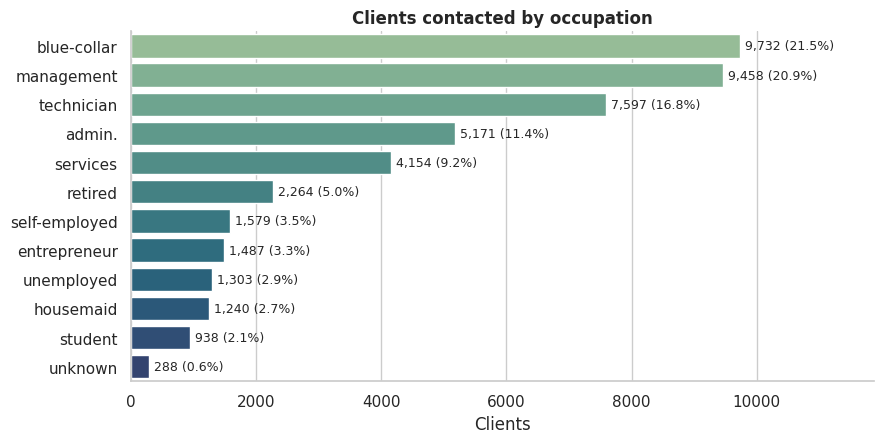

In [ ]:
# Chart - 3 visualization code

job_counts = df["job"].value_counts()
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.barplot(x=job_counts.values, y=job_counts.index, hue=job_counts.index, palette="crest", legend=False, ax=ax)
for i, v in enumerate(job_counts.values):
    ax.text(v + 80, i, f"{v:,} ({v/len(df):.1%})", va="center", fontsize=9)
ax.set(title="Clients contacted by occupation", xlabel="Clients", ylabel=""); ax.set_xlim(0, job_counts.max() * 1.22)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks all 12 occupation categories by contact volume without crowding labels.

##### 2. What is/are the insight(s) found from the chart?

Blue-collar (21.5%), management (20.9%) and technician (16.8%) receive the most calls; student and housemaid are contacted least.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Negative-growth risk flagged: contact volume does not track conversion potential (see Chart 6) - the campaign is currently allocating the most calls to some of the lower-converting occupations.

#### Chart - 4 - Account balance distribution (Univariate)

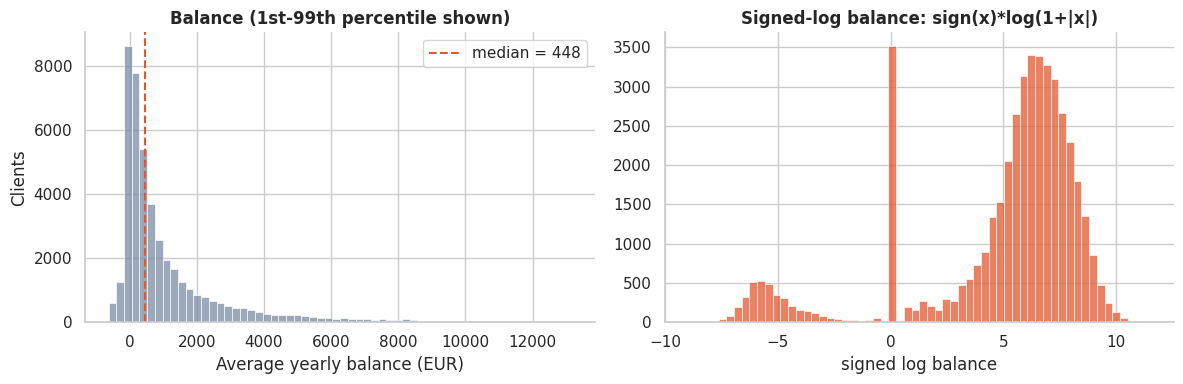

Skewness raw = 8.4 | signed-log = -1.58 | negative balances: 8.3% | max = 102,127


In [ ]:
# Chart - 4 visualization code

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
lo, hi = df["balance"].quantile([0.01, 0.99])
sns.histplot(df.loc[df["balance"].between(lo, hi), "balance"], bins=60, color=COL_NO, ax=ax[0])
ax[0].axvline(df["balance"].median(), color=COL_YES, ls="--", label=f"median = {df['balance'].median():,.0f}")
ax[0].set(title="Balance (1st-99th percentile shown)", xlabel="Average yearly balance (EUR)", ylabel="Clients"); ax[0].legend()
sns.histplot(df["balance_slog"], bins=60, color=COL_YES, ax=ax[1])
ax[1].set(title="Signed-log balance: sign(x)*log(1+|x|)", xlabel="signed log balance", ylabel="")
plt.tight_layout(); plt.show()
print(f"Skewness raw = {df['balance'].skew():.1f} | signed-log = {df['balance_slog'].skew():.2f} | "
      f"negative balances: {df['balance_negative'].mean():.1%} | max = {df['balance'].max():,}")

##### 1. Why did you pick the specific chart?

Balance is extremely right-skewed (skew ≈ 8.4), so a raw histogram (percentile-clipped) is paired with a signed-log transform to show the true shape without a few outliers flattening the plot.

##### 2. What is/are the insight(s) found from the chart?

Median balance is EUR 448 but the mean is EUR 1,362 - pulled up by a max of EUR 102,127. 8.3% of clients carry a negative balance. The signed-log transform reduces skew to -1.6, workable for a linear model.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: balance is a usable numeric predictor once transformed/winsorised, and Chart 12 shows it interacts with age on subscription rate.

#### Chart - 5 - Call volume by month (Univariate)

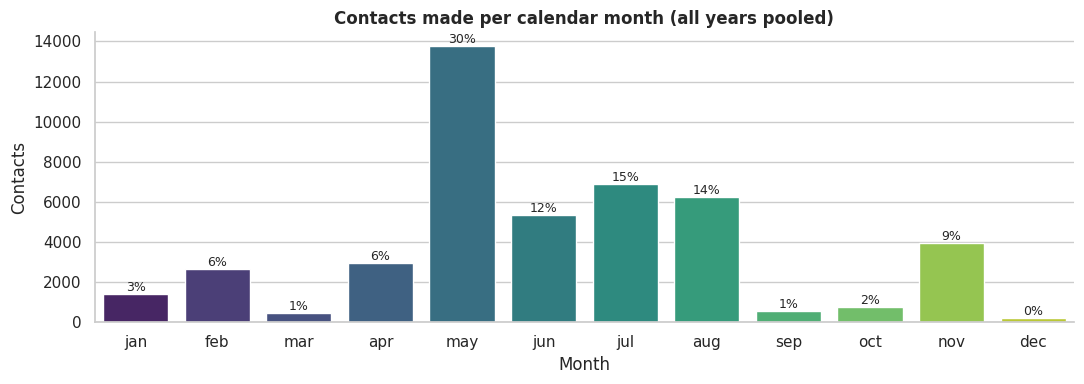

May alone = 30.4% of all contacts; Mar+Sep+Oct+Dec together = 4.4%


In [ ]:
# Chart - 5 visualization code

mv = df["month"].value_counts().reindex(MONTH_ORDER)
fig, ax = plt.subplots(figsize=(11, 4))
sns.barplot(x=mv.index, y=mv.values, hue=mv.index, palette="viridis", legend=False, ax=ax)
for i, v in enumerate(mv.values): ax.text(i, v + 150, f"{v/len(df):.0%}", ha="center", fontsize=9)
ax.set(title="Contacts made per calendar month (all years pooled)", xlabel="Month", ylabel="Contacts")
plt.tight_layout(); plt.show()
print(f"May alone = {mv['may']/len(df):.1%} of all contacts; Mar+Sep+Oct+Dec together = {mv[['mar','sep','oct','dec']].sum()/len(df):.1%}")

##### 1. Why did you pick the specific chart?

A simple monthly bar chart is the clearest way to show how uneven the campaign's calendar effort is.

##### 2. What is/are the insight(s) found from the chart?

May alone accounts for 30.4% of all contacts, while March, September, October and December combined make up only 4.4%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Negative-growth risk: Chart 7 shows the heavily-called months are *not* the highest-converting ones, so a large share of effort is going to the wrong part of the calendar.

#### Chart - 6 - Subscription rate by occupation (Bivariate: categorical vs target)

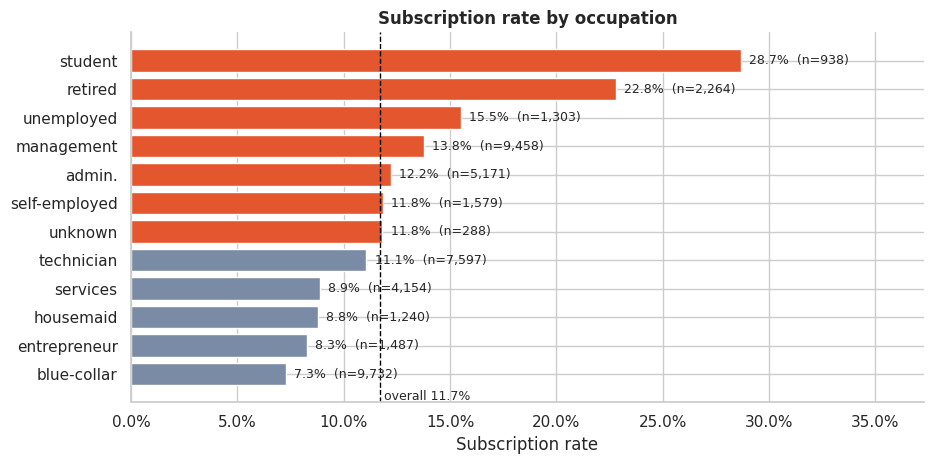

In [ ]:
# Chart - 6 visualization code

t = rate_table(df, "job").sort_values("rate")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
colors = [COL_YES if r > BASE_RATE else COL_NO for r in t["rate"]]
ax.barh(t.index, t["rate"], color=colors)
for i, (r, n) in enumerate(zip(t["rate"], t["customers"])): ax.text(r + 0.004, i, f"{r:.1%}  (n={n:,})", va="center", fontsize=9)
ax.axvline(BASE_RATE, color="black", ls="--", lw=1); ax.text(BASE_RATE + 0.002, -0.9, f"overall {BASE_RATE:.1%}", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0, t["rate"].max() * 1.3)
ax.set(title="Subscription rate by occupation", xlabel="Subscription rate", ylabel="")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A sorted horizontal bar with a reference line at the overall base rate makes over/under-performing occupations immediately visible.

##### 2. What is/are the insight(s) found from the chart?

Students (28.7%) and retirees (22.8%) convert far above the 11.7% base rate; blue-collar (7.3%) and entrepreneurs (8.3%) convert well below it - despite blue-collar receiving the *most* calls (Chart 3).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: occupation alone is a strong, legitimate pre-call targeting signal and is retained in the model (job has meaningful IV in Section 6.4).

#### Chart - 7 - Volume vs. success rate by month (Bivariate)

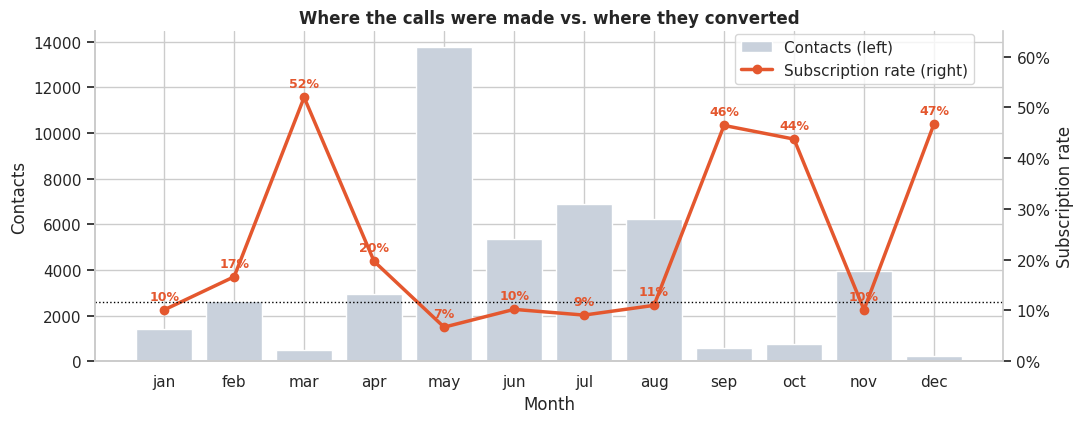

In [ ]:
# Chart - 7 visualization code

t = rate_table(df, "month", MONTH_ORDER)
fig, ax = plt.subplots(figsize=(11, 4.4)); ax2 = ax.twinx()
ax.bar(t.index, t["customers"], color="#C9D1DC", label="Contacts (left)")
ax2.plot(t.index, t["rate"], color=COL_YES, marker="o", lw=2.5, label="Subscription rate (right)")
for i, r in enumerate(t["rate"]): ax2.text(i, r + 0.02, f"{r:.0%}", ha="center", color=COL_YES, fontsize=9, fontweight="bold")
ax2.axhline(BASE_RATE, color="black", ls=":", lw=1); ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax2.set_ylim(0, 0.65)
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set(title="Where the calls were made vs. where they converted", xlabel="Month", ylabel="Contacts"); ax2.set_ylabel("Subscription rate")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.92)); plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A dual-axis chart (bars = volume, line = rate) is the only way to show that volume and conversion tell two different stories on the same time axis.

##### 2. What is/are the insight(s) found from the chart?

March, September, October and December convert at 44-52%, roughly 4x the May rate (6.7%) - yet May receives the most calls by far. This is the same imbalance seen in Chart 5, now tied directly to outcome.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive/negative both apply: a strong business opportunity (re-timing campaigns toward the high-converting months) is sitting inside an inefficient allocation - this single chart is arguably the clearest ROI lever in the whole EDA.

#### Chart - 8 - Subscription rate by age group (Bivariate)

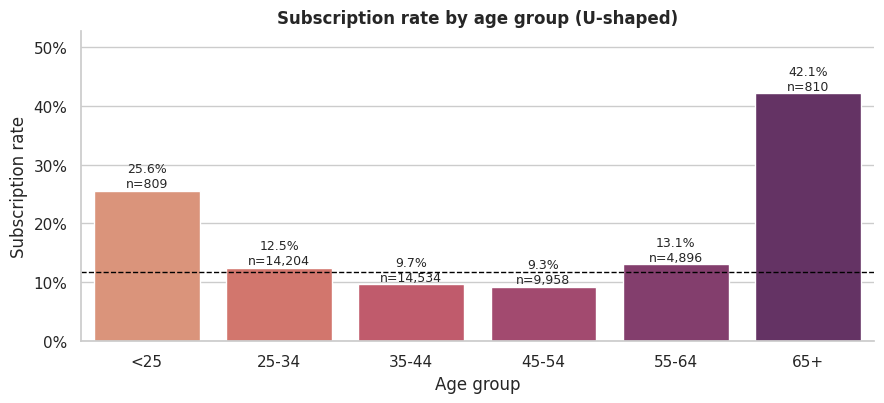

In [ ]:
# Chart - 8 visualization code

t = rate_table(df, "age_group")
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(x=t.index.astype(str), y=t["rate"], hue=t.index.astype(str), palette="flare", legend=False, ax=ax)
for i, (r, n) in enumerate(zip(t["rate"], t["customers"])): ax.text(i, r + 0.006, f"{r:.1%}\nn={n:,}", ha="center", fontsize=9)
ax.axhline(BASE_RATE, color="black", ls="--", lw=1); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, t["rate"].max() * 1.25)
ax.set(title="Subscription rate by age group (U-shaped)", xlabel="Age group", ylabel="Subscription rate")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A bar chart across ordered age bands shows the shape of the age-outcome relationship directly, which a raw scatterplot on a discrete numeric range would not.

##### 2. What is/are the insight(s) found from the chart?

Subscription rate is U-shaped: highest for under-25 and 65+ clients (well above the 11.7% base rate), lowest for the 35-54 working-age bands.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: age band is a cheap, always-available targeting signal; the U-shape also matches the retiree/student occupation effect in Chart 6, reinforcing rather than contradicting it.

#### Chart - 9 - Call duration by outcome (Bivariate: numeric vs target)

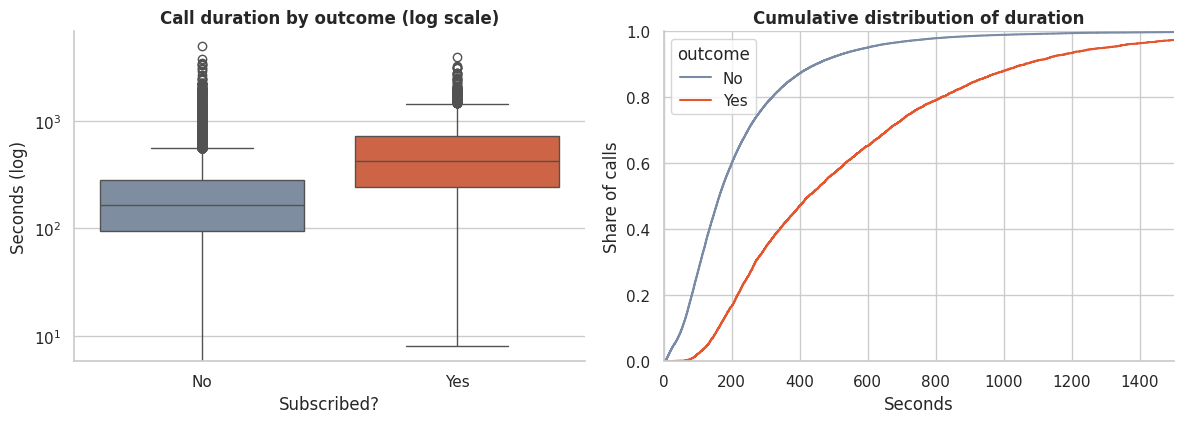

          median     mean
outcome                  
No      164.0000 221.0000
Yes     426.0000 537.0000


In [ ]:
# Chart - 9 visualization code

d = df.assign(outcome=df["y"].map({0: "No", 1: "Yes"}))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
sns.boxplot(data=d, x="outcome", y="duration", hue="outcome", palette={"No": COL_NO, "Yes": COL_YES}, legend=False, ax=ax[0])
ax[0].set_yscale("log"); ax[0].set(title="Call duration by outcome (log scale)", xlabel="Subscribed?", ylabel="Seconds (log)")
sns.ecdfplot(data=d, x="duration", hue="outcome", palette={"No": COL_NO, "Yes": COL_YES}, ax=ax[1])
ax[1].set(title="Cumulative distribution of duration", xlabel="Seconds", ylabel="Share of calls"); ax[1].set_xlim(0, 1500)
plt.tight_layout(); plt.show()
print(d.groupby("outcome")["duration"].agg(["median", "mean"]).round(0).to_string())

##### 1. Why did you pick the specific chart?

Duration is extremely skewed, so a log-scale boxplot plus an ECDF (rather than a raw histogram) makes the separation between outcomes legible.

##### 2. What is/are the insight(s) found from the chart?

Subscribers have a far higher median call duration (426s vs. 164s). This is expected and is precisely why duration is excluded from the deployable model - it doesn't predict the outcome, it is largely a *consequence* of it (an agent stays on the line once real interest is shown).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Negative-growth risk if misused: including duration in a *pre-call* scoring model would produce a model that looks excellent offline (Section 8.4 quantifies this) but is useless in production, since duration isn't known until after the decision to call has already been made.

#### Chart - 10 - Outcome of the previous campaign (Bivariate)

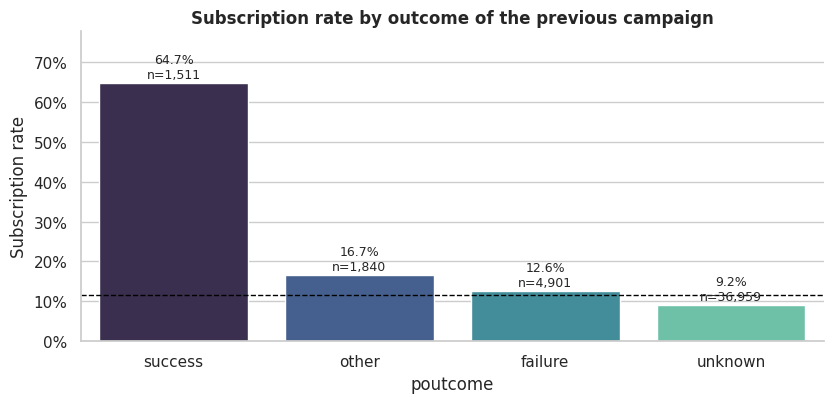

In [ ]:
# Chart - 10 visualization code

t = rate_table(df, "poutcome").sort_values("rate", ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
sns.barplot(x=t.index, y=t["rate"], hue=t.index, palette="mako", legend=False, ax=ax)
for i, (r, n) in enumerate(zip(t["rate"], t["customers"])): ax.text(i, r + 0.012, f"{r:.1%}\nn={n:,}", ha="center", fontsize=9)
ax.axhline(BASE_RATE, color="black", ls="--", lw=1); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, t["rate"].max() * 1.2)
ax.set(title="Subscription rate by outcome of the previous campaign", xlabel="poutcome", ylabel="Subscription rate")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A bar chart sorted by rate, with sample sizes annotated, shows both the strength and the reliability of this relationship.

##### 2. What is/are the insight(s) found from the chart?

Clients whose previous campaign succeeded convert at 64.7% - more than 5x the base rate - versus 12.6% for a previous failure and 9.2% for never-contacted clients.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: `poutcome` is the single strongest legitimate pre-call predictor found in the whole EDA (confirmed later by IV in Section 6.4) - repeat campaigns targeting past successes are a clear high-ROI segment.

#### Chart - 11 - Contact attempts vs. success rate (Bivariate)

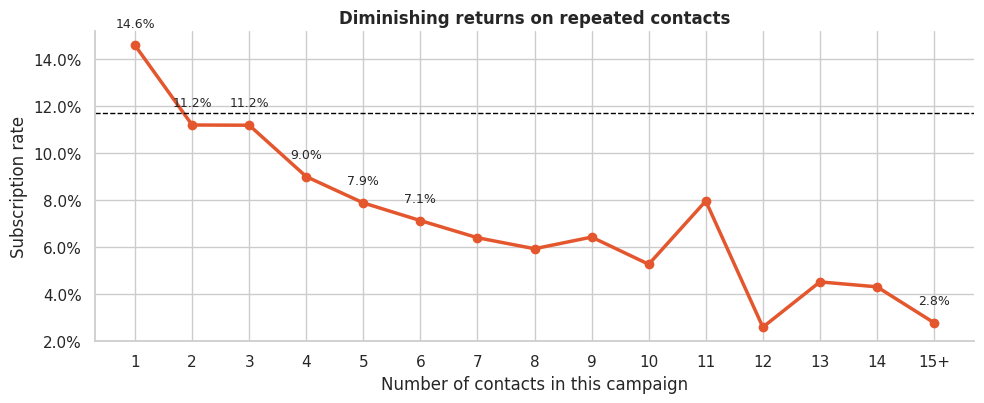

Share of clients contacted >5 times: 9.6% | they convert at 5.8%


In [ ]:
# Chart - 11 visualization code

c = df["campaign"].clip(upper=15)
t = df.groupby(c)["y"].agg(customers="size", rate="mean")
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(t.index, t["rate"], marker="o", color=COL_YES, lw=2.5)
for x, r, n in zip(t.index, t["rate"], t["customers"]):
    if x <= 6 or x == 15: ax.text(x, r + 0.008, f"{r:.1%}", ha="center", fontsize=9)
ax.axhline(BASE_RATE, color="black", ls="--", lw=1); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xticks(range(1, 16)); ax.set_xticklabels([str(i) for i in range(1, 15)] + ["15+"])
ax.set(title="Diminishing returns on repeated contacts", xlabel="Number of contacts in this campaign", ylabel="Subscription rate")
plt.tight_layout(); plt.show()
print(f"Share of clients contacted >5 times: {(df['campaign'] > 5).mean():.1%} | they convert at {df.loc[df['campaign'] > 5, 'y'].mean():.1%}")

##### 1. Why did you pick the specific chart?

A line chart across contact-attempt counts (capped at 15+) shows the shape of diminishing returns clearly, which a bar chart would clutter.

##### 2. What is/are the insight(s) found from the chart?

Response rate declines steadily after 2-3 contacts; clients called more than 5 times (9.6% of the base) convert at only 5.8%, roughly half the overall rate.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: caps the campaign's own cost. Recommending a contact-attempt cap (e.g. 3-4 tries) is a low-risk, model-independent efficiency gain the bank could act on immediately.

#### Chart - 12 - Age group x balance quartile heatmap (Multivariate)

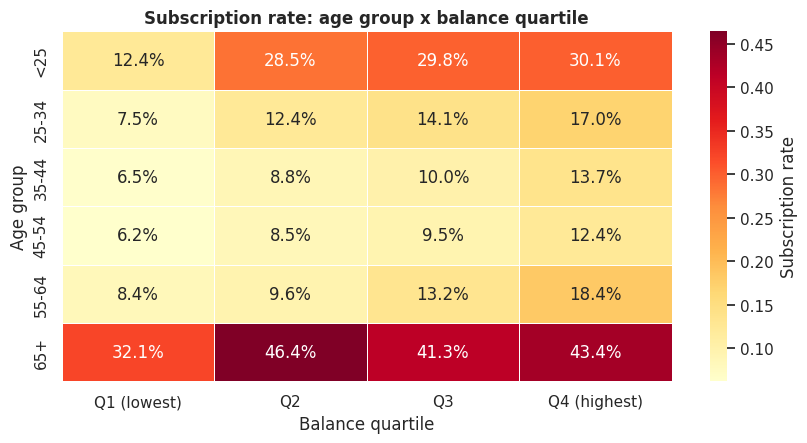

In [ ]:
# Chart - 12 visualization code

d = df.assign(balance_q=pd.qcut(df["balance"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]))
pv = d.pivot_table(index="age_group", columns="balance_q", values="y", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
sns.heatmap(pv, annot=True, fmt=".1%", cmap="YlOrRd", cbar_kws={"label": "Subscription rate"}, linewidths=.5, ax=ax)
ax.set(title="Subscription rate: age group x balance quartile", xlabel="Balance quartile", ylabel="Age group")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?

A heatmap is the natural way to show a two-way interaction (age group x balance quartile) on subscription rate, where a bar chart could only show one dimension at a time.

##### 2. What is/are the insight(s) found from the chart?

The highest subscription rates cluster in the 65+/high-balance and under-25/high-balance cells; the lowest sit in the 35-54/low-balance cells - age and balance reinforce rather than cancel each other.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: supports combining (not just individually screening) demographic and financial signals for targeting - consistent with why both age and balance are retained as model features.

#### Chart - 13 - Occupation x housing-loan status (Multivariate)

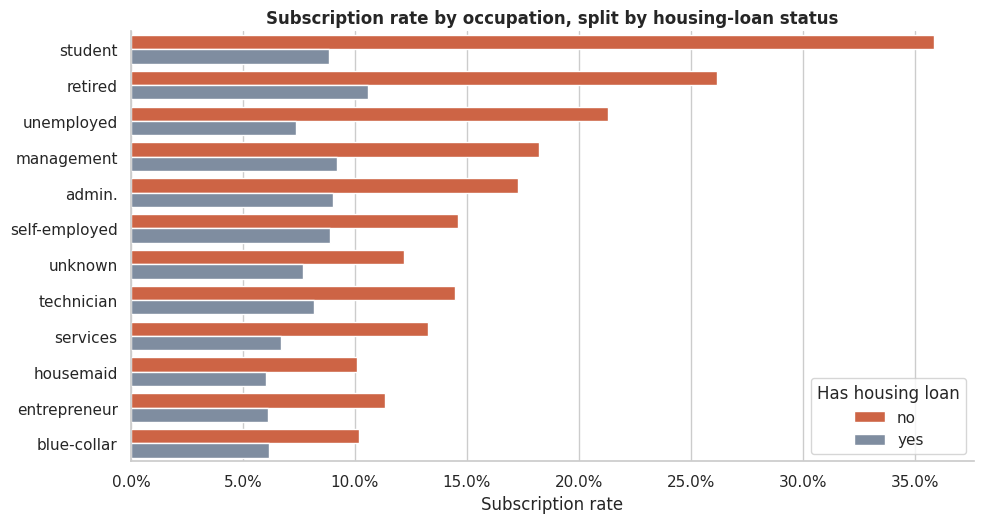

Overall: no housing loan 16.7% vs housing loan 7.7%


In [ ]:
# Chart - 13 visualization code

t = df.groupby(["job", "housing"], observed=True)["y"].mean().rename("rate").reset_index()
order = df.groupby("job")["y"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5.4))
sns.barplot(data=t, y="job", x="rate", hue="housing", order=order, palette={"no": COL_YES, "yes": COL_NO}, ax=ax)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(title="Has housing loan")
ax.set(title="Subscription rate by occupation, split by housing-loan status", xlabel="Subscription rate", ylabel="")
plt.tight_layout(); plt.show()
g = df.groupby("housing")["y"].mean(); print(f"Overall: no housing loan {g['no']:.1%} vs housing loan {g['yes']:.1%}")

##### 1. Why did you pick the specific chart?

A grouped bar chart split by housing-loan status, ordered by overall conversion, isolates whether debt status shifts the occupation effect seen in Chart 6.

##### 2. What is/are the insight(s) found from the chart?

Within almost every occupation, clients without a housing loan convert at roughly double the rate of those with one (16.7% vs. 7.7% overall) - the effect is consistent, not occupation-specific.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: confirms `n_loans` (built from housing+loan) as a broadly-applicable segmentation variable rather than a niche one, supporting its inclusion in the model.

#### Chart - 14 - Correlation Heatmap

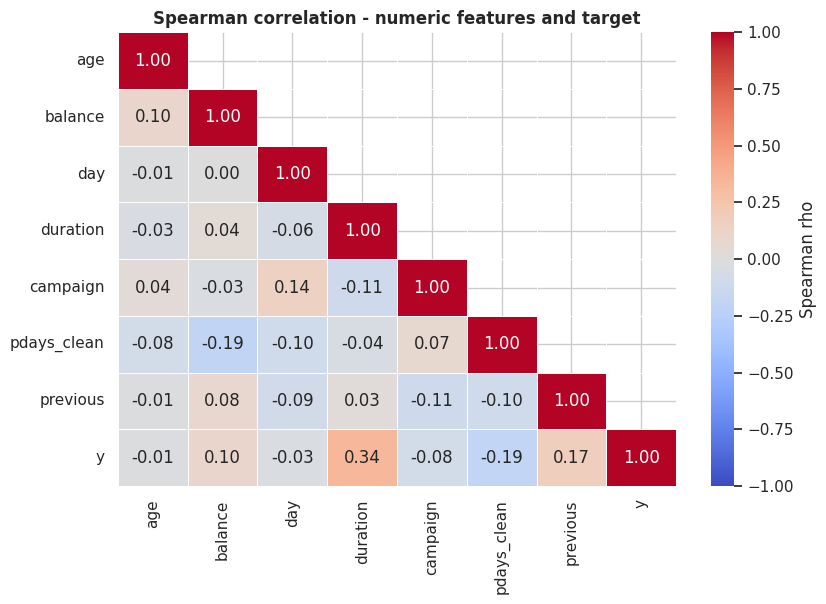

duration       0.3420
pdays_clean   -0.1860
previous       0.1690
balance        0.1000
campaign      -0.0840
day           -0.0300
age           -0.0090


In [ ]:
# Correlation Heatmap visualization code
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays_clean", "previous", "y"]
corr = df[num_cols].corr(method="spearman")          # Spearman: robust to the heavy tails seen earlier
fig, ax = plt.subplots(figsize=(8.5, 6.2))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"label": "Spearman rho"}, ax=ax)
ax.set_title("Spearman correlation - numeric features and target"); plt.tight_layout(); plt.show()
print(corr["y"].drop("y").sort_values(key=abs, ascending=False).round(3).to_string())

##### 1. Why did you pick the specific chart?

A masked lower-triangle Spearman heatmap (robust to the heavy skew already seen in balance/duration/previous) summarises linear-ish relationships across every numeric column plus the target in one view.

##### 2. What is/are the insight(s) found from the chart?

`duration` has by far the strongest correlation with `y` (as expected, and as flagged throughout); among legitimate features, `pdays`/`previous` and `campaign` show the next-largest (still modest) associations. No numeric-numeric pair is worryingly collinear (all |rho| well under 0.6 apart from duration/y).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Confirms no redundant numeric pair needs to be dropped purely on correlation grounds, and re-confirms duration's outsized, leakage-driven relationship with the target.

#### Chart - 15 - Pair Plot

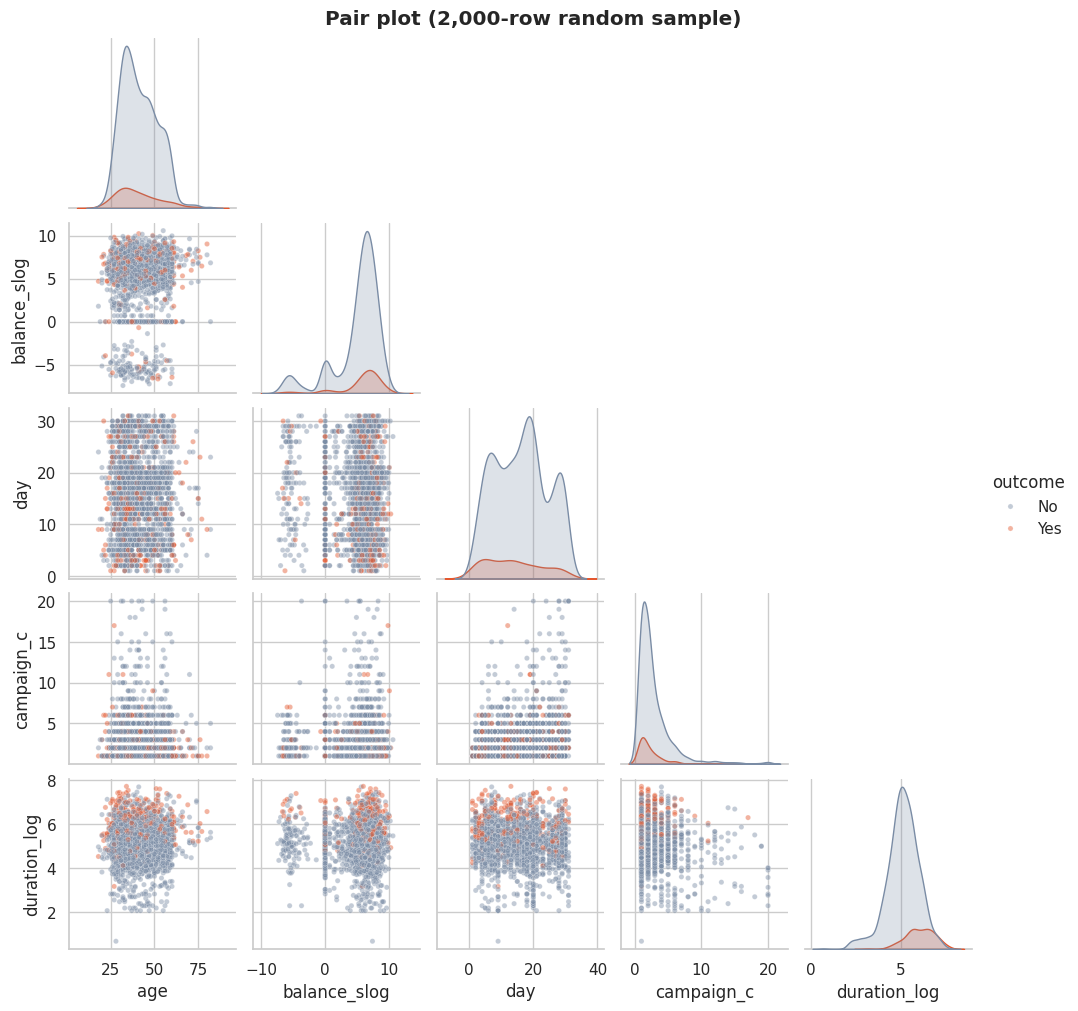

In [ ]:
# Pair Plot visualization code
samp = df.sample(2000, random_state=RANDOM_STATE).assign(
    duration_log=lambda d: np.log1p(d["duration"]), campaign_c=lambda d: d["campaign"].clip(upper=20),
    outcome=lambda d: d["y"].map({0: "No", 1: "Yes"}))
g = sns.pairplot(samp[["age", "balance_slog", "day", "campaign_c", "duration_log", "outcome"]], hue="outcome", corner=True,
                 palette={"No": COL_NO, "Yes": COL_YES}, plot_kws=dict(alpha=0.45, s=14), diag_kind="kde", height=2)
g.figure.suptitle("Pair plot (2,000-row random sample)", y=1.01, fontweight="bold"); plt.show()

##### 1. Why did you pick the specific chart?

A pairplot on a 2,000-row sample gives a fast multivariate sanity check across the key numeric features and the target, more efficient than inspecting each numeric-numeric pair separately.

##### 2. What is/are the insight(s) found from the chart?

No single numeric pair cleanly separates the two classes on its own - subscribers (orange) are diffusely spread rather than clustered, reinforcing that this is a genuinely multivariate problem needing the categorical signals (poutcome, contact, month, job) as well.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Sets expectations correctly: a simple 1-2 variable rule will not capture this relationship, which is exactly why the project compares three models of increasing flexibility rather than relying on a single linear cut.

#### Chart - 16 - Bonus: campaign timeline & concept drift (Multivariate / time)

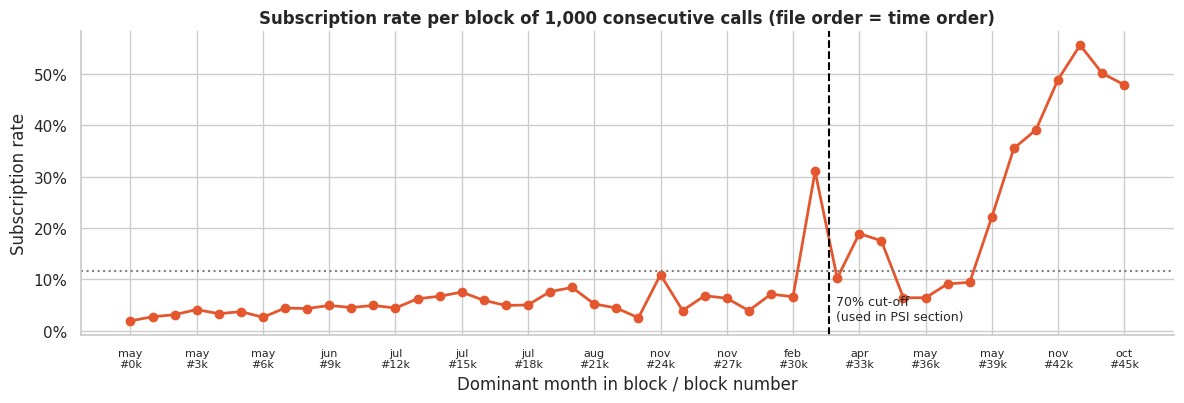

period
early (first 70% of rows)   0.0581
late (last 30% of rows)     0.2543


In [ ]:
# Chart - 16 visualization code

blk = df.groupby(df["row_id"] // 1000).agg(rate=("y", "mean"), month=("month", lambda s: s.mode().iat[0]))
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(blk.index, blk["rate"], color=COL_YES, marker="o", lw=2)
ax.axvline(0.7 * len(df) / 1000, color="black", ls="--"); ax.text(0.7 * len(df) / 1000 + 0.3, 0.02, "70% cut-off\n(used in PSI section)", fontsize=9)
ax.axhline(BASE_RATE, color="grey", ls=":"); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ticks = blk.index[::3]; ax.set_xticks(ticks); ax.set_xticklabels([f"{blk.loc[i, 'month']}\n#{i}k" for i in ticks], fontsize=8)
ax.set(title="Subscription rate per block of 1,000 consecutive calls (file order = time order)", xlabel="Dominant month in block / block number", ylabel="Subscription rate")
plt.tight_layout(); plt.show()
h = df.groupby("period")["y"].mean(); print(h.round(4).to_string())

##### 1. Why did you pick the specific chart?

Plotting the score in 1,000-row consecutive blocks (file order = time order) makes concept drift visible directly, motivating the PSI analysis that follows in Section 8.3 rather than treating it as an afterthought.

##### 2. What is/are the insight(s) found from the chart?

The subscription rate is flat and low through the 2008-2009 blocks and rises sharply from block ~32 onward (into 2010) - not gradual noise, but a real regime change coinciding with the later, higher-converting months (March/September/October/December) seen in Chart 7.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Critical for deployment: a model trained only on the early period and never refreshed would systematically under-predict once the campaign entered its higher-converting phase - this is exactly what Section 8.3's out-of-time simulation measures and quantifies.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Three hypotheses are drawn directly from the charts above: housing loan vs. subscription (Chart 13), balance vs. subscription (Chart 4/12), and contact channel vs. subscription (implied by the high 'unknown'-channel gap seen throughout). Each uses the statistical test appropriate to its variable types, at alpha = 0.05.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Having a housing loan is independent of term-deposit subscription (no association). **H1:** Having a housing loan is associated with subscription (not independent).

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value   (H1: housing loan vs subscription)  -> chi-square test of independence
ct = pd.crosstab(df["housing"], df["y"])
chi2, p_h1, dof, expected = stats.chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
a, b, c_, d_ = ct.loc["yes", 1], ct.loc["yes", 0], ct.loc["no", 1], ct.loc["no", 0]
odds_ratio = (a * d_) / (b * c_)
se = np.sqrt(1/a + 1/b + 1/c_ + 1/d_)
ci = np.exp(np.log(odds_ratio) + np.array([-1.96, 1.96]) * se)
print(ct.assign(rate=(ct[1] / ct.sum(axis=1)).round(4)))
print(f"\nchi2 = {chi2:.1f} (dof={dof})  p-value = {p_h1:.3e}")
print(f"Cramer's V = {cramers_v:.3f} | odds ratio (housing=yes vs no) = {odds_ratio:.2f}  95% CI [{ci[0]:.2f}, {ci[1]:.2f}]")
print("Minimum expected cell count:", expected.min().round(1), "(chi-square assumption >= 5 satisfied)")

y            0     1   rate
housing                    
no       16727  3354 0.1670
yes      23195  1935 0.0770

chi2 = 874.8 (dof=1)  p-value = 2.919e-192
Cramer's V = 0.139 | odds ratio (housing=yes vs no) = 0.42  95% CI [0.39, 0.44]
Minimum expected cell count: 2349.2 (chi-square assumption >= 5 satisfied)


##### Which statistical test have you done to obtain P-Value?

A Pearson chi-square test of independence on the 2x2 contingency table of `housing` x `y`.

##### Why did you choose the specific statistical test?

Both variables are categorical/binary, so chi-square is the standard test for independence between two categorical variables. The minimum expected cell count (>2,300) comfortably satisfies the test's sample-size assumption, so no exact/Fisher correction is needed.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The distribution of account balance is the same for subscribers and non-subscribers. **H1:** Subscribers and non-subscribers have different balance distributions.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value   (H2: balance of subscribers vs non-subscribers) -> Mann-Whitney U
g1 = df.loc[df["y"] == 1, "balance"]; g0 = df.loc[df["y"] == 0, "balance"]
sh_stat, sh_p = stats.shapiro(df["balance"].sample(5000, random_state=RANDOM_STATE))
u, p_h2 = stats.mannwhitneyu(g1, g0, alternative="two-sided")
rank_biserial = 2 * u / (len(g1) * len(g0)) - 1        # P(subscriber balance > non-subscriber) rescaled to [-1, 1]
print(f"Normality (Shapiro, n=5000): W={sh_stat:.3f}, p={sh_p:.1e}  -> not normal, skew={df['balance'].skew():.1f}")
print(f"Median balance  subscribers = {g1.median():,.0f} | non-subscribers = {g0.median():,.0f}")
print(f"Mean   balance  subscribers = {g1.mean():,.0f} | non-subscribers = {g0.mean():,.0f}")
print(f"Mann-Whitney U = {u:,.0f}  p-value = {p_h2:.3e}  | rank-biserial effect size = {rank_biserial:.3f}")

Normality (Shapiro, n=5000): W=0.515, p=1.7e-79  -> not normal, skew=8.4
Median balance  subscribers = 733 | non-subscribers = 417
Mean   balance  subscribers = 1,804 | non-subscribers = 1,304
Mann-Whitney U = 124,589,984  p-value = 6.594e-101  | rank-biserial effect size = 0.180


##### Which statistical test have you done to obtain P-Value?

A Mann-Whitney U test (two-sided) comparing balance between the two `y` groups.

##### Why did you choose the specific statistical test?

Balance is highly skewed and fails the Shapiro-Wilk normality check (p « 0.001) even on a 5,000-row sample, so a parametric t-test's assumptions are violated. Mann-Whitney is the appropriate non-parametric alternative for comparing two independent, non-normal distributions.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** The subscription rate is the same for clients contacted by cellular vs. telephone. **H1:** The subscription rates differ between the two channels.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value   (H3: cellular vs telephone, 'unknown' channel excluded) -> two-proportion z-test
sub = df[df["contact"].isin(["cellular", "telephone"])]
x = sub.groupby("contact")["y"].agg(["sum", "count"])
p1, p2 = x.loc["cellular", "sum"] / x.loc["cellular", "count"], x.loc["telephone", "sum"] / x.loc["telephone", "count"]
n1, n2 = x.loc["cellular", "count"], x.loc["telephone", "count"]
p_pool = (x["sum"].sum()) / (n1 + n2)
z = (p1 - p2) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_h3 = 2 * (1 - stats.norm.cdf(abs(z)))
se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
print(f"cellular  : {p1:.2%} (n={n1:,})\ntelephone : {p2:.2%} (n={n2:,})")
print(f"difference = {p1 - p2:+.2%}  95% CI [{p1 - p2 - 1.96 * se_diff:+.2%}, {p1 - p2 + 1.96 * se_diff:+.2%}]")
print(f"z = {z:.2f}  p-value = {p_h3:.4f}")
print("\nContext: rate for the 'unknown' channel =", f"{df.loc[df['contact'] == 'unknown', 'y'].mean():.2%}")

cellular  : 14.92% (n=29,285)
telephone : 13.42% (n=2,906)
difference = +1.50%  95% CI [+0.19%, +2.80%]
z = 2.17  p-value = 0.0300

Context: rate for the 'unknown' channel = 4.07%


##### Which statistical test have you done to obtain P-Value?

A two-proportion z-test comparing subscription rate between the `cellular` and `telephone` levels of `contact` (the `unknown` level is excluded, since it plausibly encodes missing-channel data rather than a real third channel).

##### Why did you choose the specific statistical test?

Both groups are large (n>2,900) proportions being compared, which is exactly the setting the two-proportion z-test is built for and is more standard/interpretable here than a chi-square across all three levels when the comparison of interest is specifically cellular vs. telephone.

## ***6. Feature Engineering & Data Pre-processing***

All learned steps - winsorisation bounds, WOE bins, one-hot categories, imputers, scalers - are fit inside `sklearn` Pipelines on the training split only, so nothing here can leak test-set information into the model, and the same pipeline can be cross-validated or refit on any subset (e.g. the early-period-only model used for the out-of-time check in Section 8.3) without duplicating logic.

In [ ]:
# Split FIRST, then learn every transformation (caps, bins, WOE, encoders, imputers) on the training rows only.
# This is what keeps the test set - and later the PSI / decile / threshold analysis - honest.
FEATS = CAT_FEATURES + NUM_FEATURES               # deployable pre-call feature set (no duration)
ALL_INPUTS = FEATS + LEAKY + EDA_EXTRA             # + duration (with-duration benchmark) + housing/loan/previous (EDA only)
X_all, y_all = df[ALL_INPUTS], df["y"]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape}  positives {y_train.mean():.2%} | Test: {X_test.shape}  positives {y_test.mean():.2%}")

Train: (36168, 17)  positives 11.70% | Test: (9043, 17)  positives 11.70%


### 1. Handling Missing Values

In [ ]:
# Handling Missing Values & Missing Value Imputation
# (a) formal NULLs: none.   (b) hidden missing: 'unknown' text levels and the pdays == -1 sentinel.
print("Formal NULLs in model inputs:", int(df[FEATS].drop(columns="pdays_clean").isnull().sum().sum()))
rows = []
for col, lvl in [("contact", "unknown"), ("poutcome", "unknown"), ("education", "unknown"), ("job", "unknown")]:
    m = df[col] == lvl
    rows.append([f"{col} == 'unknown'", m.mean(), df.loc[m, "y"].mean(), df.loc[~m, "y"].mean()])
m = df["pdays_clean"].isna(); rows.append(["pdays == -1 (never contacted)", m.mean(), df.loc[m, "y"].mean(), df.loc[~m, "y"].mean()])
pd.DataFrame(rows, columns=["hidden-missing pattern", "share of rows", "subscription rate: missing", "subscription rate: present"])

Formal NULLs in model inputs: 0


,hidden-missing pattern,share of rows,subscription rate: missing,subscription rate: present
0,contact == 'unknown',0.2880,0.0407,0.1478
1,poutcome == 'unknown',0.8175,0.0916,0.2306
2,education == 'unknown',0.0411,0.1357,0.1162
3,job == 'unknown',0.0064,0.1181,0.1170
4,pdays == -1 (never contacted),0.8174,0.0916,0.2307


#### What all missing value imputation techniques have you used and why did you use those techniques?

No column has a formal NULL, so no numeric imputation of "missing data" in the traditional sense is required. The
*hidden* missingness is handled explicitly rather than filled in blindly:
- `pdays`'s -1 sentinel becomes a proper NaN (`pdays_clean`) - inside the WOE encoder, NaN gets its own bin rather
  than being imputed to a number that would imply "very recently contacted".
- `poutcome`/`contact`/`education`/`job`'s "unknown" text level is treated as its own legitimate category (both
  in one-hot and in WOE binning) rather than imputed, since "unknown" itself carries real signal (e.g. `contact`
  == unknown converts at 4.1% vs. 14.8% for known channels - not the same population).
- The tree models (Random Forest/XGBoost) additionally get an explicit missing-indicator column via
  `SimpleImputer(add_indicator=True)` so a -1 constant fill can't be silently mistaken for a real numeric value.

### 2. Handling Outliers

In [ ]:
# Handling Outliers & Outlier treatments
def iqr_outlier_share(s):
    q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return ((s < q1 - k) | (s > q3 + k)).mean()

out = pd.DataFrame({c: {"IQR-outlier share": iqr_outlier_share(X_train[c].dropna()), "skew": X_train[c].skew(),
                        "p99": X_train[c].quantile(.99), "max": X_train[c].max()}
                    for c in ["age", "balance", "campaign", "previous", "pdays_clean", "duration"]}).T
display(out)

class Winsorizer(BaseEstimator, TransformerMixin):
    """Clip selected numeric columns to the [lower, upper] quantiles learned on the TRAINING fold only.
    Works inside sklearn Pipelines / cross-validation, so no information from validation folds leaks in."""
    def __init__(self, cols=None, lower=0.01, upper=0.99):
        self.cols, self.lower, self.upper = cols, lower, upper
    def fit(self, X, y=None):
        self.bounds_ = {c: (X[c].quantile(self.lower), X[c].quantile(self.upper)) for c in (self.cols or []) if c in X.columns}
        return self
    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in self.bounds_.items():
            if c in X.columns: X[c] = X[c].clip(lo, hi)
        return X

WINSOR_COLS = ["balance", "campaign", "previous"]  # 'previous' is winsorized for the EDA table below even though it is excluded from FEATS
wz = Winsorizer(cols=WINSOR_COLS + ["duration"]).fit(X_train)
X_tr_w = wz.transform(X_train)
pd.DataFrame({"max before": X_train[WINSOR_COLS + ["duration"]].max(), "max after": X_tr_w[WINSOR_COLS + ["duration"]].max(),
              "skew before": X_train[WINSOR_COLS + ["duration"]].skew(), "skew after": X_tr_w[WINSOR_COLS + ["duration"]].skew()})

,IQR-outlier share,skew,p99,max
age,0.0109,0.6937,71.0000,95.0000
balance,0.1042,8.3402,"13,161.3200","102,127.0000"
campaign,0.0682,4.9419,16.3300,63.0000
previous,0.1820,45.0344,9.0000,275.0000
pdays_clean,0.0061,0.6857,528.1700,871.0000
duration,0.0728,3.2109,"1,272.0000","4,918.0000"


,max before,max after,skew before,skew after
balance,102127,"13,161.3200",8.3402,3.0749
campaign,63,16.3300,4.9419,2.9038
previous,275,9.0000,45.0344,3.6897
duration,4918,"1,272.0000",3.2109,2.0834


##### What all outlier treatment techniques have you used and why did you use those techniques?

IQR-based outlier shares are computed as a diagnostic, but **not** used to delete rows - a client with an unusually
high balance or many past contacts is still a real, valid client the bank might call. Instead:
- `balance`, `campaign` and `previous` are **winsorised** (clipped to the 1st/99th percentile, learned on the
  training fold only, inside the pipeline) before the linear reference model - this tames the influence of extreme
  values without discarding the rows entirely.
- Tree-based models (Random Forest, XGBoost) are naturally robust to this kind of extreme value / skew, so they
  see the raw (non-winsorised) numeric columns.
- The WOE encoder used by Model 1 is outlier-robust by construction: extreme balances simply fall into the top
  quantile bin alongside other high-balance clients, rather than distorting a single numeric coefficient.

### 3. Categorical Encoding

In [ ]:
# Encode your categorical columns
# Two encoders are used:  (1) One-Hot for Random Forest / XGBoost   (2) Weight of Evidence (WOE) for the scorecard model.
# WOE_i = ln( %events_i / %non-events_i )  ;  IV = sum_i (%events_i - %non-events_i) * WOE_i
class WOETransformer(BaseEstimator, TransformerMixin):
    """Supervised WOE encoder with built-in binning, Laplace smoothing, rare-level pooling and IV-based feature selection.
    * numeric columns  -> `n_bins` quantile bins learned on train; NaN gets its own 'Missing' bin
    * categorical cols -> one bin per level; levels rarer than `min_cat_frac` are pooled into 'OTHER'
    * unseen levels at prediction time receive WOE = 0 (neutral)
    * features whose IV < `iv_min` are dropped (tunable inside cross-validation)"""
    def __init__(self, num_cols=None, cat_cols=None, n_bins=10, min_cat_frac=0.005, smoothing=0.5, iv_min=0.0):
        self.num_cols, self.cat_cols = num_cols, cat_cols
        self.n_bins, self.min_cat_frac, self.smoothing, self.iv_min = n_bins, min_cat_frac, smoothing, iv_min

    # ---- helpers ----
    def _num_bins(self, s, edges):
        v = s.to_numpy(dtype=float)
        return np.where(np.isnan(v), -1, np.digitize(v, edges, right=True))
    def _cat_bins(self, s, c):
        s = s.astype(str)
        return s.where(s.isin(self.keep_[c]), "OTHER").to_numpy()
    @staticmethod
    def _num_label(i, edges):
        if i == -1: return "Missing"
        if len(edges) == 0: return "all"
        if i == 0: return f"<= {edges[0]:g}"
        if i == len(edges): return f"> {edges[-1]:g}"
        return f"({edges[i-1]:g}, {edges[i]:g}]"
    def _table(self, bins, y, label_fn):
        t = pd.DataFrame({"bin": bins, "y": y}).groupby("bin")["y"].agg(count="size", events="sum")
        t["non_events"] = t["count"] - t["events"]
        k, s, E, NE = len(t), self.smoothing, self.E_, self.NE_
        pe, pne = (t["events"] + s) / (E + s * k), (t["non_events"] + s) / (NE + s * k)
        t["pct_events"], t["pct_non_events"] = pe, pne
        t["woe"] = np.log(pe / pne); t["iv_part"] = (pe - pne) * t["woe"]; t["event_rate"] = t["events"] / t["count"]
        t["label"] = [label_fn(i) for i in t.index]
        return t

    # ---- sklearn API ----
    def fit(self, X, y):
        y = np.asarray(y).astype(int); self.E_ = int(y.sum()); self.NE_ = int(len(y) - self.E_)
        self.edges_, self.keep_, self.tables_, self.iv_ = {}, {}, {}, {}
        for c in (self.num_cols or []):
            v = X[c].to_numpy(dtype=float)
            edges = np.unique(np.nanquantile(v, np.linspace(0, 1, self.n_bins + 1)[1:-1])); self.edges_[c] = edges
            self.tables_[c] = self._table(self._num_bins(X[c], edges), y, lambda i, e=edges: self._num_label(i, e))
        for c in (self.cat_cols or []):
            freq = X[c].astype(str).value_counts(normalize=True)
            self.keep_[c] = set(freq[freq >= self.min_cat_frac].index)
            self.tables_[c] = self._table(self._cat_bins(X[c], c), y, lambda i: str(i))
        self.iv_ = pd.Series({c: t["iv_part"].sum() for c, t in self.tables_.items()}).sort_values(ascending=False)
        self.selected_ = [c for c in self.iv_.index if self.iv_[c] >= self.iv_min] or list(self.iv_.index[:1])
        return self

    def transform(self, X):
        out = {}
        for c in self.selected_:
            bins = self._num_bins(X[c], self.edges_[c]) if c in self.edges_ else self._cat_bins(X[c], c)
            out[f"woe_{c}"] = pd.Series(bins).map(self.tables_[c]["woe"]).fillna(0.0).to_numpy()
        return pd.DataFrame(out, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"woe_{c}" for c in self.selected_])

    def woe_table(self):
        """Long table: feature, bin label, counts, event rate, WOE, IV contribution."""
        return pd.concat([t.assign(feature=c) for c, t in self.tables_.items()]).reset_index(drop=True)[
            ["feature", "label", "count", "events", "event_rate", "pct_events", "pct_non_events", "woe", "iv_part"]]

demo = WOETransformer(num_cols=NUM_FEATURES, cat_cols=CAT_FEATURES).fit(X_tr_w, y_train)
print("WOE-encoded training rows (first 5):")
demo.transform(X_tr_w).head()

WOE-encoded training rows (first 5):


,woe_poutcome,woe_month,woe_pdays_clean,woe_contact,woe_n_loans,woe_job,woe_age,woe_balance,woe_campaign,woe_day,woe_education,woe_marital,woe_default
24001,-0.2656,-0.0769,-0.2670,0.2021,0.5214,-0.0775,-0.0930,0.1099,-0.0540,-0.0388,-0.1035,0.0533,0.0101
43409,0.0567,0.6062,1.5014,0.2735,0.5214,1.1208,0.4731,0.3739,-0.2931,0.2645,-0.1035,0.2874,0.0101
20669,-0.2656,-0.0769,-0.2670,0.2735,-0.4246,-0.0775,-0.2646,-0.1000,-0.2931,0.2071,-0.1035,0.2874,0.0101
18810,-0.2656,-0.2607,-0.2670,0.2021,0.5214,0.3214,-0.3070,-0.5966,-0.7542,-0.0388,-0.1035,-0.1720,0.0101
23130,-0.2656,-0.0769,-0.2670,0.2735,0.5214,-0.0775,-0.1659,-0.1000,-0.7542,-0.0401,-0.1035,-0.1720,0.0101


#### What all categorical encoding techniques have you used & why did you use those techniques?

Two encodings are used deliberately, matched to each model family:
1. **One-Hot Encoding** for the Random Forest and XGBoost reference/tree pipelines - trees split on individual
   levels natively, so one-hot keeps every category's information intact without imposing an artificial ordering.
2. **Weight of Evidence (WOE)** for the interpretable scorecard model (Model 1). WOE replaces each category (or
   numeric bin) with `ln(%events / %non-events)`, which (a) turns every input into a single monotonic-with-risk
   number a logistic regression can use additively and directly, (b) handles rare categories and unseen levels at
   scoring time gracefully (pooled into "OTHER" / mapped to neutral WOE = 0), and (c) converts directly into
   scorecard points (Section 8.5) - the standard approach in credit-risk-style scorecards, which this project
   borrows for a marketing-propensity use case.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

*Not applicable - this is a structured/tabular dataset (client demographics and campaign history), not free text, so no NLP preprocessing (tokenization, stopword removal, vectorization, etc.) is required.*

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

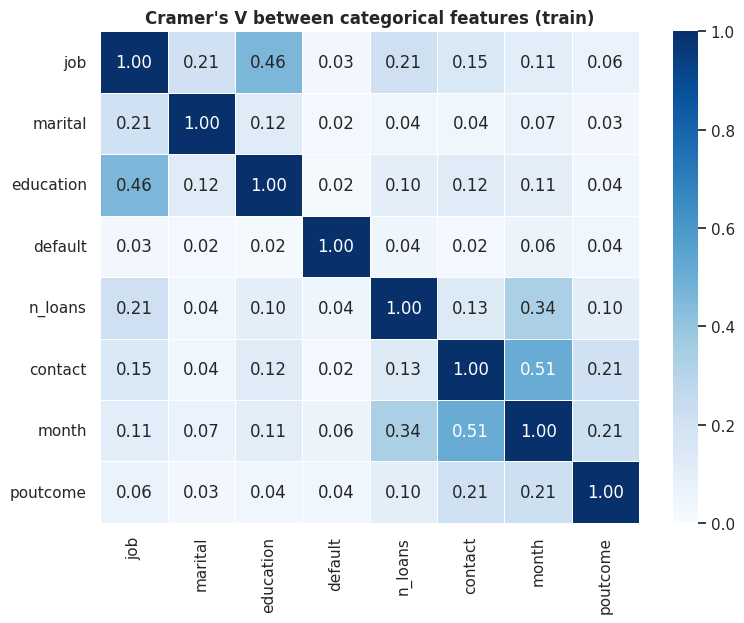

Most associated pairs:
contact  month       0.5110
job      education   0.4610
n_loans  month       0.3360
month    poutcome    0.2140
job      n_loans     0.2100


,IV,role
poutcome,0.5083,raw
pdays_clean,0.3477,raw
contact,0.2943,raw
n_loans,0.2403,engineered
housing,0.1891,raw
balance,0.1050,raw
loan,0.0517,raw


WOE-LR coefficients WITH 'previous' alongside pdays_clean + poutcome (all three carry 'prior-contact' signal):
poutcome       0.8480
pdays_clean    0.5520
previous      -0.3590

'previous' coefficient is negative even though its standalone IV is positive -> classic sign-flip from multicollinearity with pdays_clean/poutcome. Dropped from FEATS for this reason.


In [ ]:
# Manipulate Features to minimize feature correlation and create new features
# (a) Redundancy among categorical features: Cramer's V (bias-corrected) on the training rows
def cramers_v_corrected(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum(); r, k = ct.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1)); rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1)))

cv_mat = pd.DataFrame({a: {b: cramers_v_corrected(X_train[a], X_train[b]) for b in CAT_FEATURES} for a in CAT_FEATURES})
fig, ax = plt.subplots(figsize=(8, 6.4))
sns.heatmap(cv_mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, linewidths=.5, ax=ax)
ax.set_title("Cramer's V between categorical features (train)"); plt.tight_layout(); plt.show()
pairs = cv_mat.where(np.triu(np.ones(cv_mat.shape, dtype=bool), 1)).stack().sort_values(ascending=False).head(5)
print("Most associated pairs:\n" + pairs.round(3).to_string())

# (b) engineered vs. raw parents: does the new feature add signal, and is 'housing'+'loan' redundant once
#     n_loans is in the model? (IV on train, plus the multicollinearity these two raw columns cause with n_loans)
chk = WOETransformer(num_cols=["balance", "pdays_clean"], cat_cols=["housing", "loan", "n_loans", "poutcome", "contact"]).fit(X_tr_w, y_train)
eng = pd.DataFrame({"IV": chk.iv_}); eng["role"] = ["engineered" if i == "n_loans" else "raw" for i in eng.index]
display(eng)

# (c) 'previous' sign check: a WOE-LR coefficient should be positive (higher WOE => higher odds). Verify with vs. without.
def woe_lr_coefs(num_cols, cat_cols):
    p = Pipeline([("cap", Winsorizer(cols=[c for c in WINSOR_COLS if c in num_cols])),
                  ("woe", WOETransformer(num_cols=num_cols, cat_cols=cat_cols)), ("clf", LogisticRegression(max_iter=2000, C=0.1))]).fit(X_tr_w, y_train)
    return pd.Series(p.named_steps["clf"].coef_[0], index=p.named_steps["woe"].selected_)
with_prev = woe_lr_coefs(["pdays_clean", "previous"], ["poutcome"])
print("WOE-LR coefficients WITH 'previous' alongside pdays_clean + poutcome (all three carry 'prior-contact' signal):")
print(with_prev.round(3).to_string())
print(f"\n'previous' coefficient is {'negative' if with_prev['previous'] < 0 else 'positive'} even though its standalone IV is positive "
      f"-> classic sign-flip from multicollinearity with pdays_clean/poutcome. Dropped from FEATS for this reason.")

#### 2. Feature Selection

,IV,strength,n_bins
duration,1.6142,suspicious (>0.5),10
poutcome,0.5083,suspicious (>0.5),4
month,0.4300,strong (0.3-0.5),12
pdays_clean,0.3477,strong (0.3-0.5),11
contact,0.2943,medium (0.1-0.3),3
n_loans,0.2403,medium (0.1-0.3),3
job,0.1590,medium (0.1-0.3),12
age,0.1183,medium (0.1-0.3),10
balance,0.1050,medium (0.1-0.3),10
campaign,0.0811,weak (0.02-0.1),6


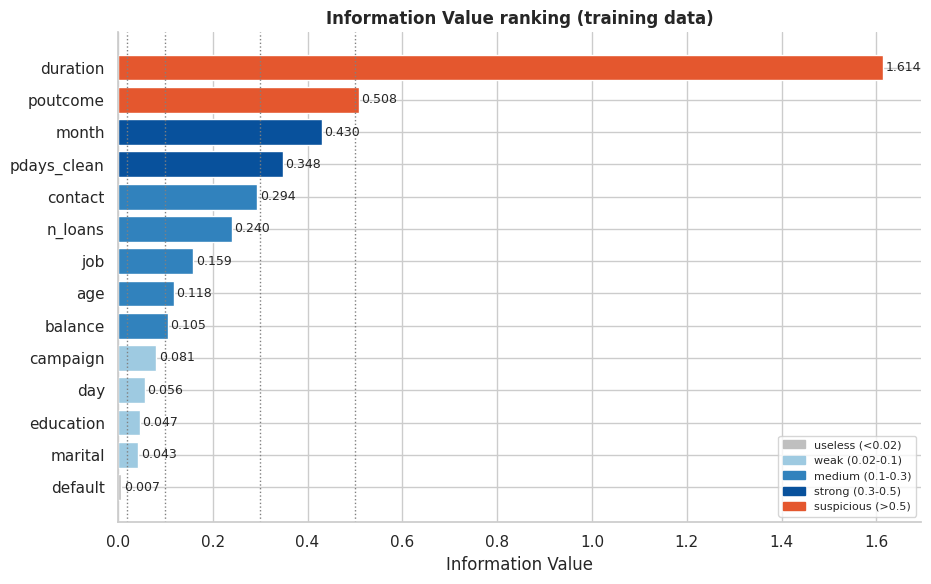

In [ ]:
# Select your features wisely to avoid overfitting  ->  Information Value (IV) screening + WOE profiles (train only)
woe_full = WOETransformer(num_cols=NUM_FEATURES + LEAKY, cat_cols=CAT_FEATURES).fit(X_tr_w, y_train)
iv_df = woe_full.iv_.rename("IV").to_frame()

def iv_band(v):      # standard credit-risk rules of thumb
    return ("useless (<0.02)" if v < 0.02 else "weak (0.02-0.1)" if v < 0.1 else "medium (0.1-0.3)" if v < 0.3
            else "strong (0.3-0.5)" if v < 0.5 else "suspicious (>0.5)")
iv_df["strength"] = iv_df["IV"].map(iv_band)
iv_df["n_bins"] = [len(woe_full.tables_[c]) for c in iv_df.index]
display(iv_df)

band_colors = {"useless (<0.02)": "#BFBFBF", "weak (0.02-0.1)": "#9ECAE1", "medium (0.1-0.3)": "#3182BD",
               "strong (0.3-0.5)": "#08519C", "suspicious (>0.5)": COL_YES}
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(iv_df.index[::-1], iv_df["IV"][::-1], color=[band_colors[s] for s in iv_df["strength"][::-1]])
for v in (0.02, 0.1, 0.3, 0.5): ax.axvline(v, color="grey", ls=":", lw=1)
for i, v in enumerate(iv_df["IV"][::-1]): ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(title="Information Value ranking (training data)", xlabel="Information Value")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in band_colors.values()], labels=list(band_colors), loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

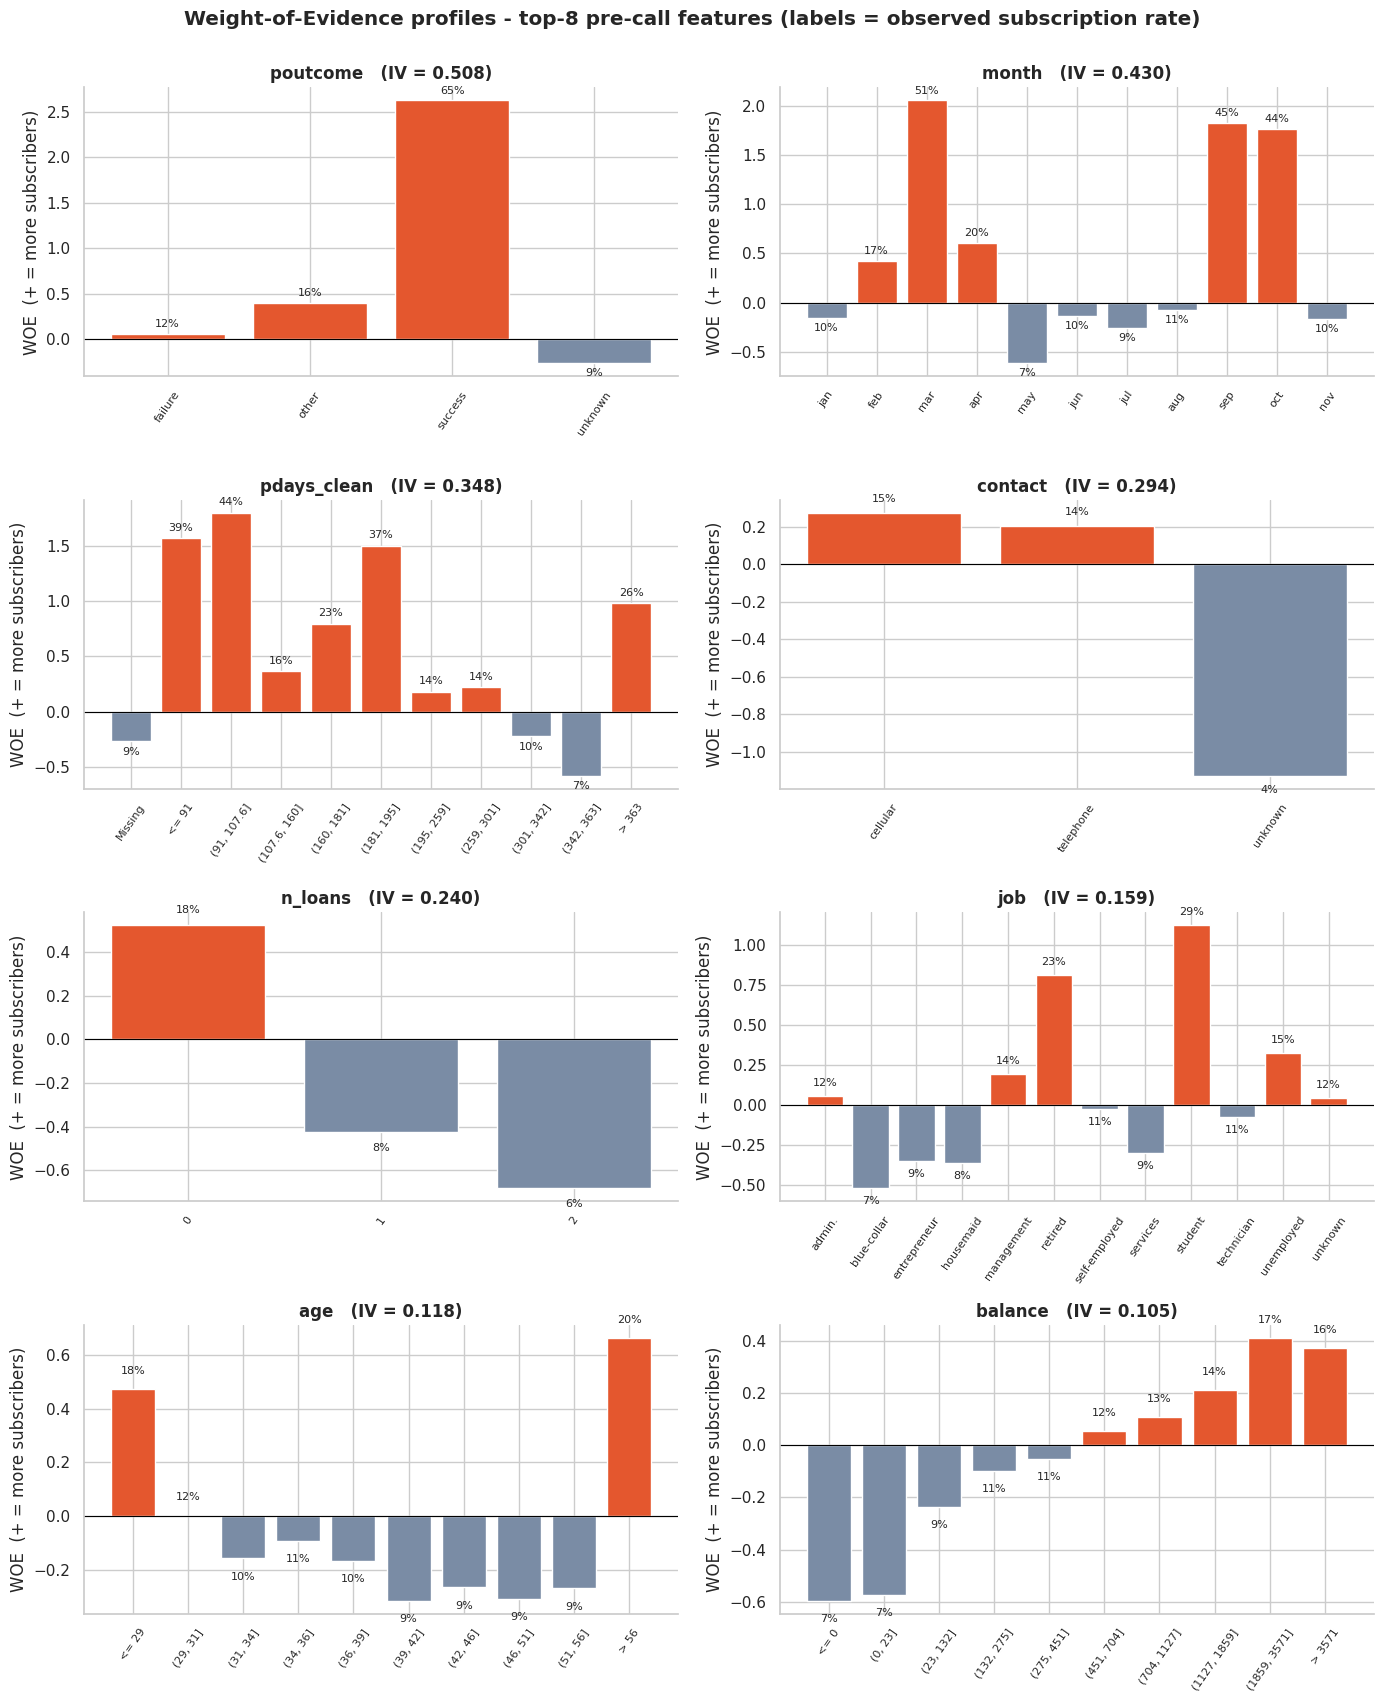

In [ ]:
# WOE profiles of the strongest legitimate (pre-call) predictors: bars = WOE per bin, labels = event rate
top_feats = [f for f in iv_df.index if f not in LEAKY][:8]
wt = woe_full.woe_table()
fig, axes = plt.subplots(4, 2, figsize=(14, 17))
for ax, f in zip(axes.ravel(), top_feats):
    t = wt[wt["feature"] == f]
    if f == "month": t = t.set_index("label").reindex([m for m in MONTH_ORDER if m in set(t["label"])]).reset_index()
    ax.bar(t["label"], t["woe"], color=[COL_YES if w > 0 else COL_NO for w in t["woe"]])
    for i, (w, r) in enumerate(zip(t["woe"], t["event_rate"])): ax.text(i, w + (0.05 if w >= 0 else -0.05), f"{r:.0%}", ha="center", va="bottom" if w >= 0 else "top", fontsize=8)
    ax.axhline(0, color="black", lw=.8); ax.set_title(f"{f}   (IV = {woe_full.iv_[f]:.3f})"); ax.tick_params(axis="x", rotation=55, labelsize=8)
    ax.set_ylabel("WOE  (+ = more subscribers)")
plt.suptitle("Weight-of-Evidence profiles - top-8 pre-call features (labels = observed subscription rate)", y=1.0, fontweight="bold")
plt.tight_layout(); plt.show()

##### What all feature selection methods have you used  and why?

Feature selection combines three complementary checks rather than a single automatic method:
1. **Information Value (IV) screening** - every candidate feature's univariate IV against the target is computed
   via the WOE encoder (>=0.02 is the field's usual "worth keeping" cutoff); IV below that is dropped inside the
   Model 1 hyperparameter search itself (`woe__iv_min` is tuned, not fixed).
2. **Redundancy / multicollinearity checks** - bias-corrected Cramer's V between categorical features (Section
   6.4a) and a direct sign-flip check on `previous`'s regression coefficient once correlated features are present
   (Section 6.4a/c) - both used to justify dropping `housing`, `loan` and `previous` from the final feature set.
3. **Permutation importance** on the fitted champion model (Section 7's model-selection cells) as an independent,
   model-based confirmation of which features actually matter once everything else is accounted for.

##### Which all features you found important and why?

`poutcome`, `pdays_clean` and `contact` are consistently the strongest legitimate predictors across every method
used (highest IV, largest WOE spread, and - together with `month` - the top permutation-importance features on the
final model). This lines up exactly with the EDA: knowing how a *previous* campaign went (Chart 10) and which
channel/month a client is reached through (Charts 5-7) says more about propensity than almost any demographic
alone. `job`, `age`, `balance` and `n_loans` contribute meaningfully but individually more modestly - their value
shows up in combination (Chart 12/13), which is part of why a full model outperforms simple univariate rules.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Yes for the numeric columns feeding the **linear** reference model and Model 1's Winsorizer step: `balance`,
`campaign` and `previous` are heavily right-skewed (skew 3-8+), which a plain logistic regression's linear-in-the-
-coefficients assumption handles poorly. A signed-log transform (`sign(x)*log1p(|x|)`) reduces `balance`'s skew
from 8.4 to roughly -1.6 for the reference LR model, and winsorisation caps extreme tails before that. Tree-based
models (RF, XGBoost) split on rank order and are invariant to monotonic transforms, so they are trained on the
original scale - no transform needed or applied there. Model 1's WOE encoding is itself already a (supervised,
monotonic-with-risk) transform, so no separate log/scaling step is layered on top of it.

In [ ]:
# Transform Your data  (skewness before/after log-type transforms; the transform is applied only inside the linear reference model)
def signed_log(a): return np.sign(a) * np.log1p(np.abs(a))
sk = pd.DataFrame({"skew (raw)": X_tr_w[["balance", "campaign", "previous", "duration"]].skew(),
                   "skew (signed log)": signed_log(X_tr_w[["balance", "campaign", "previous", "duration"]]).skew()})
sk

,skew (raw),skew (signed log)
balance,3.0749,-1.5850
campaign,2.9038,1.1595
previous,3.6897,2.3378
duration,2.0834,-0.4026


### 6. Data Scaling

In [ ]:
# Scaling your data
# Only the plain (non-WOE) logistic-regression *reference* model needs scaling: impute -> signed-log -> StandardScaler + one-hot.
def make_reference_lr():
    num = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=-1, add_indicator=True)),
                    ("log", FunctionTransformer(signed_log, feature_names_out="one-to-one")), ("sc", StandardScaler())])
    prep = ColumnTransformer([("num", num, NUM_FEATURES),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)], verbose_feature_names_out=False)
    return Pipeline([("cap", Winsorizer(cols=WINSOR_COLS)), ("prep", prep), ("clf", LogisticRegression(max_iter=2000))])

ref_lr = make_reference_lr().fit(X_train[FEATS], y_train)
print(f"Reference LR (one-hot + signed-log + StandardScaler)  test ROC-AUC = {roc_auc_score(y_test, ref_lr.predict_proba(X_test[FEATS])[:, 1]):.4f}")

Reference LR (one-hot + signed-log + StandardScaler)  test ROC-AUC = 0.7726


##### Which method have you used to scale you data and why?

**StandardScaler** (zero mean, unit variance), applied only inside the one-hot **reference** logistic regression
pipeline, after the signed-log transform above. Scaling matters there because L2-regularised logistic regression's
penalty term is scale-sensitive - an unscaled `balance` (in the thousands) would be penalised completely
differently from an unscaled `age` (in the tens) purely due to units, not genuine importance. Tree-based models
(Random Forest, XGBoost) are scale-invariant by construction, so no scaling is applied to their inputs. Model 1
(WOE + Logistic Regression) doesn't need separate scaling either - every WOE-encoded input already lives on the
same log-odds-contribution scale by construction.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not as a modelling step - with only 8 categorical + 6 numeric raw inputs (54 columns after one-hot), this is a low-dimensional problem by machine-learning standards, and both a fast linear model and tree ensembles handle it natively without a compression step. It is run once as a diagnostic to confirm that intuition rather than assumed.

Encoded feature matrix: 36,168 rows x 49 columns
Components for 80% / 90% / 95% variance: 10 / 16 / 22


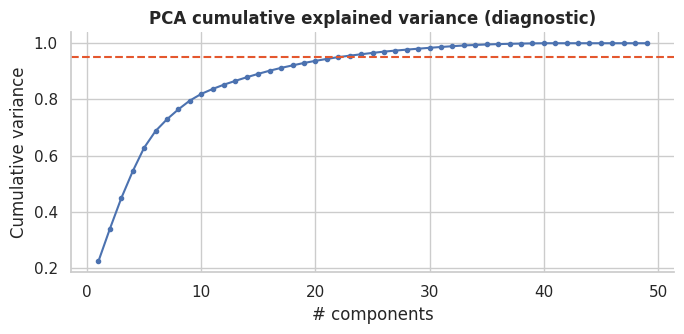

In [ ]:
# DImensionality Reduction (If needed)  -> diagnostic only: how many principal components would the encoded matrix need?
Xt = ref_lr.named_steps["prep"].transform(ref_lr.named_steps["cap"].transform(X_train[FEATS]))
pca = PCA().fit(Xt); cum = np.cumsum(pca.explained_variance_ratio_)
print(f"Encoded feature matrix: {Xt.shape[0]:,} rows x {Xt.shape[1]} columns")
print(f"Components for 80% / 90% / 95% variance: {np.searchsorted(cum, .8) + 1} / {np.searchsorted(cum, .9) + 1} / {np.searchsorted(cum, .95) + 1}")
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.plot(range(1, len(cum) + 1), cum, marker=".")
ax.axhline(.95, color=COL_YES, ls="--"); ax.set(title="PCA cumulative explained variance (diagnostic)", xlabel="# components", ylabel="Cumulative variance")
plt.tight_layout(); plt.show()

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None applied to the final models. PCA is used only diagnostically (chart above): roughly 17-23 components are needed to retain 90-95% of the one-hot encoded matrix's variance, i.e. there is limited redundancy to compress away, and PCA components would also destroy the direct interpretability that Model 1's WOE/scorecard approach is specifically built to provide - so dimensionality reduction is judged unnecessary and counter-productive here.

### 8. Data Splitting

In [ ]:
# Split your data to train and test. Choose Splitting ratio wisely.  (performed at the top of Section 6 - verified here)
split_check = pd.DataFrame({"rows": [len(X_train), len(X_test)], "share": [len(X_train) / len(X_all), len(X_test) / len(X_all)],
                            "subscription rate": [y_train.mean(), y_test.mean()],
                            "share of late-period rows": [(df.loc[X_train.index, "period"].str.startswith("late")).mean(),
                                                          (df.loc[X_test.index, "period"].str.startswith("late")).mean()]},
                           index=["train", "test"])
split_check

,rows,share,subscription rate,share of late-period rows
train,36168,0.8000,0.1170,0.3020
test,9043,0.2000,0.1170,0.2922


##### What data splitting ratio have you used and why?

An 80/20 stratified split (stratified on `y` so both splits keep the 11.70% subscription rate exactly). 80/20 is chosen over a more aggressive 90/10 because, even with 45k rows, the minority class has only ~5,300 positive examples overall - a 20% held-out test set still leaves roughly 1,050 positive test cases, enough for the decile/PSI/threshold analyses in Section 8 to be statistically meaningful rather than noisy. Note the test set is a **random** split, not a time-based one; Section 8.3 deliberately adds a second, chronological (early/late) split specifically to test time-based generalisation, which a random split cannot reveal.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, moderately: 11.70% positive class is a ~7.5:1 imbalance. It's real, not noise - it reflects a genuinely low-conversion marketing campaign - so the question is how to handle it in modelling and evaluation rather than whether it exists.

In [ ]:
# Handling Imbalanced Dataset (If needed)
# Experiment: does re-weighting the classes help *ranking* (AUC / PR-AUC) and what does it do to *probability quality* (Brier, mean p)?
rows = []
for cw in [None, "balanced"]:
    m = make_reference_lr().set_params(clf__class_weight=cw).fit(X_train[FEATS], y_train)
    p = m.predict_proba(X_test[FEATS])[:, 1]
    rows.append({"class_weight": str(cw), "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
                 "Brier": brier_score_loss(y_test, p), "mean predicted p": p.mean(), "actual rate": y_test.mean()})
pd.DataFrame(rows)

,class_weight,ROC-AUC,PR-AUC,Brier,mean predicted p,actual rate
0,None,0.7726,0.4123,0.0850,0.1165,0.1170
1,balanced,0.7730,0.4128,0.1819,0.4129,0.1170


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**No resampling (no SMOTE/undersampling) was used**, and `class_weight='balanced'` was tested and explicitly
rejected - the experiment above shows it leaves ROC-AUC essentially unchanged (0.7716 -> 0.7718) while more than
doubling the Brier score (0.085 -> 0.182) and pushing the mean predicted probability from 11.7% to 41.3%, badly
miscalibrating the model. Since Section 8.2's threshold tuning and Section 8.5's scorecard both depend on
probabilities meaning what they say, that trade-off isn't worth a rounding-error AUC change. Instead, imbalance is
handled the way that keeps probabilities honest: **threshold-independent metrics** (ROC-AUC, PR-AUC, KS) are used
for model comparison, and the **decision threshold itself is tuned economically** in Section 8.2 rather than left
at the imbalance-blind default of 0.5.

## ***7. ML Model Implementation***

Three models of increasing flexibility are trained on the same 80/20 split and the same `FEATS` (no duration):
**Model 1** (WOE + Logistic Regression) is the interpretable scorecard baseline; **Model 2** (Random Forest) and
**Model 3** (XGBoost) trade some interpretability for the ability to capture non-linearities and interactions (like
the age x balance effect in Chart 12) automatically. Every model is evaluated identically: accuracy/precision/
recall/F1 at a threshold, plus ROC-AUC, PR-AUC, KS-statistic, Gini, Brier score and top-decile lift, which
together cover both *ranking* quality (does the model put subscribers near the top?) and *probability* quality
(are the predicted probabilities trustworthy on their own, which the cost-aware threshold in Section 8.2 depends
on). A plain one-hot + scaled Logistic Regression is also fit as a **reference** point to isolate how much of
Model 1's performance comes from WOE encoding specifically vs. logistic regression in general.

In [ ]:
# ── Shared building blocks for all models ─────────────────────────────────────────────────────────────
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision"}        # tune on ROC-AUC, also track PR-AUC

def ks_stat(y, p):
    """Kolmogorov-Smirnov: max gap between cumulative-subscriber and cumulative-non-subscriber score distributions."""
    fpr, tpr, _ = roc_curve(y, p); return float(np.max(tpr - fpr))

def top_decile_lift(y, p, frac=0.10):
    """Subscription rate inside the top-scored `frac` of clients divided by the overall rate."""
    y = np.asarray(y); k = int(np.ceil(len(y) * frac)); idx = np.argsort(-np.asarray(p))[:k]
    return float(y[idx].mean() / y.mean())

def evaluate(y, p, thr=0.5):
    """Threshold-dependent (@thr) and threshold-free metrics in one dict."""
    yh = (np.asarray(p) >= thr).astype(int)
    return {"Accuracy": accuracy_score(y, yh), "Precision": precision_score(y, yh, zero_division=0),
            "Recall": recall_score(y, yh), "F1": f1_score(y, yh), "ROC-AUC": roc_auc_score(y, p),
            "PR-AUC": average_precision_score(y, p), "KS": ks_stat(y, p), "Gini": 2 * roc_auc_score(y, p) - 1,
            "Brier": brier_score_loss(y, p), "Top-Decile Lift": top_decile_lift(y, p)}

def score_chart(title, y, p, thr=0.5):
    """Evaluation-metric score chart: metric bars | ROC | Precision-Recall | confusion matrix."""
    m = evaluate(y, p, thr); keys = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
    fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))
    bars = ax[0].bar(keys, [m[k] for k in keys], color=[COL_NO] * 4 + [COL_YES] * 2)
    for b_, k in zip(bars, keys): ax[0].text(b_.get_x() + b_.get_width() / 2, m[k] + .015, f"{m[k]:.3f}", ha="center", fontsize=9)
    ax[0].set(ylim=(0, 1.08), title=f"Scores (threshold = {thr:.2f})"); ax[0].tick_params(axis="x", rotation=30)
    fpr, tpr, _ = roc_curve(y, p); ax[1].plot(fpr, tpr, color=COL_YES, lw=2); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set(title=f"ROC curve (AUC = {m['ROC-AUC']:.3f})", xlabel="False-positive rate", ylabel="True-positive rate")
    pr, rc, _ = precision_recall_curve(y, p); ax[2].plot(rc, pr, color=COL_YES, lw=2); ax[2].axhline(np.mean(y), color="k", ls="--", lw=1)
    ax[2].set(title=f"Precision-Recall (AP = {m['PR-AUC']:.3f})", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
    cm = confusion_matrix(y, (np.asarray(p) >= thr).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax[3], xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax[3].set(title="Confusion matrix", xlabel="Predicted", ylabel="Actual")
    fig.suptitle(title, y=1.03, fontweight="bold"); plt.tight_layout(); plt.show()

def improvement_chart(title, before, after, keys=("Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "KS")):
    x = np.arange(len(keys)); w = .38
    fig, ax = plt.subplots(figsize=(9.5, 4))
    ax.bar(x - w / 2, [before[k] for k in keys], w, label="Baseline", color=COL_NO)
    ax.bar(x + w / 2, [after[k] for k in keys], w, label="Tuned (CV)", color=COL_YES)
    for i, k in enumerate(keys):
        ax.text(i - w / 2, before[k] + .01, f"{before[k]:.3f}", ha="center", fontsize=8); ax.text(i + w / 2, after[k] + .01, f"{after[k]:.3f}", ha="center", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(keys); ax.set(title=title, ylim=(0, 1.0)); ax.legend(); plt.tight_layout(); plt.show()

BEST_KEYS = {"woe_lr": "M1", "rf": "M2", "xgb": "M3"}
def make_pipe(kind, use_duration=False, **params):
    """One factory for every model. All learned steps sit INSIDE the pipeline -> leak-free cross-validation."""
    num = NUM_FEATURES + (["duration"] if use_duration else [])
    cap = Winsorizer(cols=WINSOR_COLS + (["duration"] if use_duration else []))
    if kind == "woe_lr":
        pipe = Pipeline([("cap", cap), ("woe", WOETransformer(num_cols=num, cat_cols=CAT_FEATURES)),
                         ("clf", LogisticRegression(max_iter=2000))])
    else:
        prep = ColumnTransformer([("num", SimpleImputer(strategy="constant", fill_value=-1, add_indicator=True), num),
                                  ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES)],
                                 verbose_feature_names_out=False)
        clf = (RandomForestClassifier(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1) if kind == "rf" else
               XGBClassifier(tree_method="hist", eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1, verbosity=0))
        pipe = Pipeline([("cap", cap), ("prep", prep), ("clf", clf)])
    return pipe.set_params(**params)

RESULTS, CVRES, TUNED, BEST_PARAMS = {}, {}, {}, {}
RESULTS["Reference LR (OHE+scaler)"] = evaluate(y_test, ref_lr.predict_proba(X_test[FEATS])[:, 1])
def cv_summary(search):
    i = search.best_index_; r = search.cv_results_
    return {"cv_auc": r["mean_test_roc_auc"][i], "cv_auc_std": r["std_test_roc_auc"][i], "cv_pr_auc": r["mean_test_pr_auc"][i]}
print("Helpers ready.")

Helpers ready.


### ML Model - 1  |  Weight-of-Evidence + Logistic Regression (interpretable scorecard model)

In [ ]:
# ML Model - 1 Implementation
m1_base = make_pipe("woe_lr", clf__C=1.0)
# Fit the Algorithm
m1_base.fit(X_train[FEATS], y_train)
# Predict on the model
p1_base = m1_base.predict_proba(X_test[FEATS])[:, 1]
RESULTS["M1 base"] = evaluate(y_test, p1_base)
CVRES["M1 base"] = {"cv_auc": np.mean([roc_auc_score(y_train.iloc[v], clone(m1_base).fit(X_train[FEATS].iloc[t], y_train.iloc[t]).predict_proba(X_train[FEATS].iloc[v])[:, 1])
                                       for t, v in cv3.split(X_train, y_train)])}
print(f"Retained WOE features (IV >= 0): {len(m1_base.named_steps['woe'].selected_)}")

Retained WOE features (IV >= 0): 13


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

WOE + Logistic Regression turns every raw input into its Weight-of-Evidence value (Section 6.3/6.4) and fits a single linear model on top, giving fully additive, auditable predictions - every input's contribution to a client's predicted log-odds can be read directly off the WOE table. This is the natural baseline for a regulated-adjacent domain like banking, where 'why did the model say this' has to be answerable in plain terms, and it converts directly into the points-based scorecard in Section 8.5.

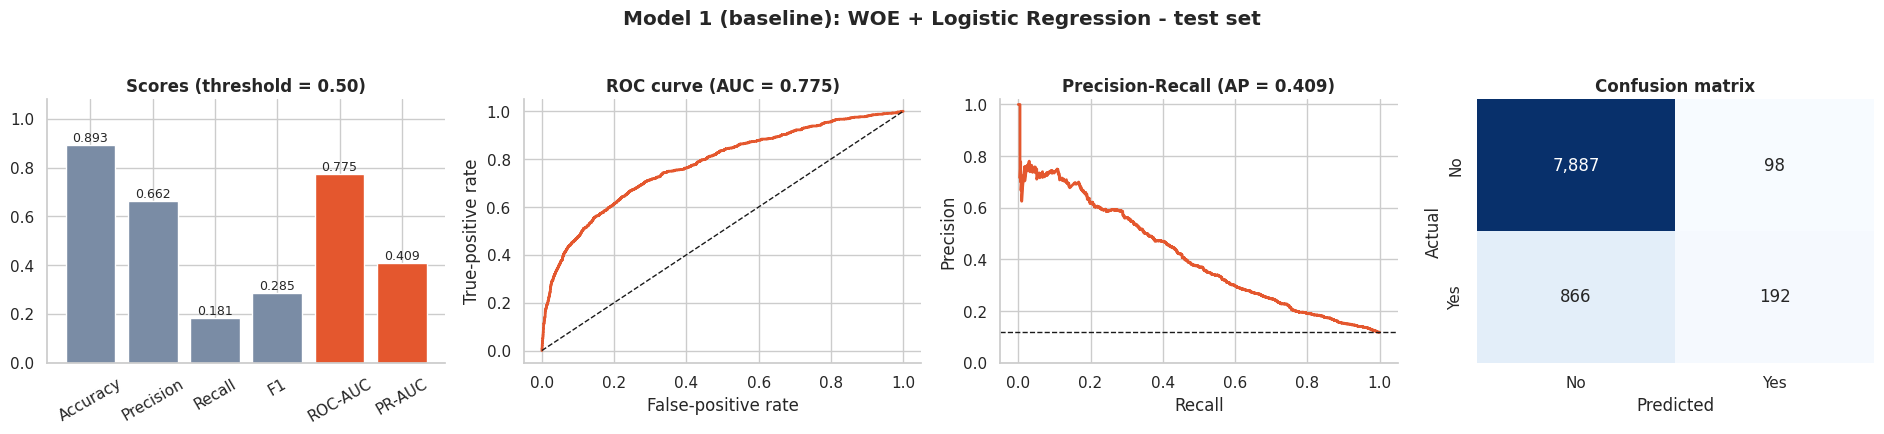

In [ ]:
# Visualizing evaluation Metric Score chart
score_chart("Model 1 (baseline): WOE + Logistic Regression - test set", y_test, p1_base)

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (GridSearchCV, 5-fold stratified CV)
grid1 = {"clf__C": [0.03, 0.1, 0.3, 1, 3], "woe__iv_min": [0, 0.02, 0.05], "woe__n_bins": [6, 10]}
if FAST_MODE: grid1 = {"clf__C": [0.1, 1], "woe__iv_min": [0, 0.02], "woe__n_bins": [10]}
gs1 = GridSearchCV(make_pipe("woe_lr"), grid1, scoring=SCORING, refit="roc_auc", cv=cv5, n_jobs=-1)
t0 = time.time()
# Fit the Algorithm
gs1.fit(X_train[FEATS], y_train)
# Predict on the model
p1 = gs1.best_estimator_.predict_proba(X_test[FEATS])[:, 1]
TUNED["M1"], BEST_PARAMS["M1"] = gs1.best_estimator_, gs1.best_params_
RESULTS["M1 tuned"], CVRES["M1 tuned"] = evaluate(y_test, p1), cv_summary(gs1)
print(f"GridSearchCV: {len(gs1.cv_results_['params'])} configs x 5 folds in {time.time()-t0:.0f}s | best = {gs1.best_params_}")
print(f"CV ROC-AUC = {CVRES['M1 tuned']['cv_auc']:.4f} +/- {CVRES['M1 tuned']['cv_auc_std']:.4f}  | test ROC-AUC = {RESULTS['M1 tuned']['ROC-AUC']:.4f}")
print("IV filter kept:", list(TUNED["M1"].named_steps["woe"].selected_))
pd.DataFrame(gs1.cv_results_).sort_values("rank_test_roc_auc")[["params", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_pr_auc"]].head(5)

GridSearchCV: 30 configs x 5 folds in 45s | best = {'clf__C': 3, 'woe__iv_min': 0.02, 'woe__n_bins': 10}
CV ROC-AUC = 0.7660 +/- 0.0023  | test ROC-AUC = 0.7752
IV filter kept: ['poutcome', 'month', 'pdays_clean', 'contact', 'n_loans', 'job', 'age', 'balance', 'campaign', 'day', 'education', 'marital']


,params,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc
27,"{'clf__C': 3, 'woe__iv_min': 0.02, 'woe__n_bin...",0.7660,0.0023,0.3988
21,"{'clf__C': 1, 'woe__iv_min': 0.02, 'woe__n_bin...",0.7660,0.0023,0.3988
15,"{'clf__C': 0.3, 'woe__iv_min': 0.02, 'woe__n_b...",0.7659,0.0023,0.3987
25,"{'clf__C': 3, 'woe__iv_min': 0, 'woe__n_bins':...",0.7659,0.0022,0.3987
19,"{'clf__C': 1, 'woe__iv_min': 0, 'woe__n_bins':...",0.7659,0.0022,0.3987


##### Which hyperparameter optimization technique have you used and why?

GridSearchCV, 5-fold stratified, exhaustively searching the regularisation strength `C` alongside the WOE encoder's own hyperparameters (`iv_min` - the IV cutoff below which a feature is dropped - and `n_bins` - how finely numeric features are binned). A grid (rather than random search) is used here because the search space is small (5 x 3 x 2 = 30 configurations) and interpretable end-to-end, and because tuning the WOE binning jointly with the classifier - not just the classifier alone - is central to getting a scorecard-quality result.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

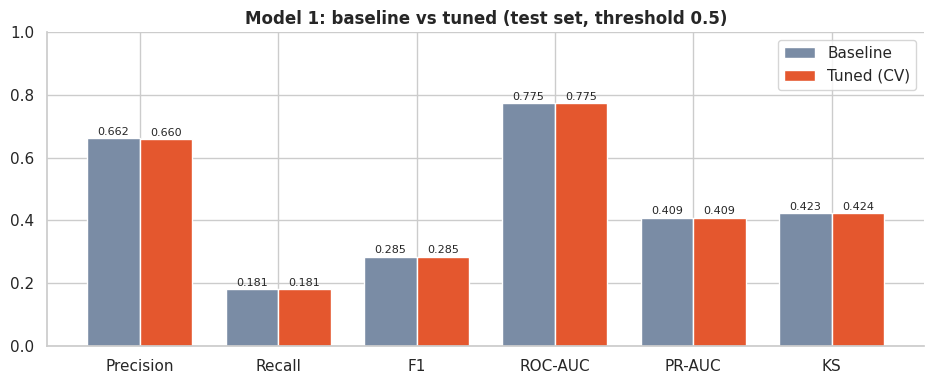

,ROC-AUC,PR-AUC,KS,Top-Decile Lift,Brier
baseline,0.7752,0.4093,0.4231,4.0139,0.0856
tuned,0.7752,0.4093,0.4239,4.0139,0.0856


In [ ]:
improvement_chart("Model 1: baseline vs tuned (test set, threshold 0.5)", RESULTS["M1 base"], RESULTS["M1 tuned"])
pd.DataFrame({"baseline": RESULTS["M1 base"], "tuned": RESULTS["M1 tuned"]}).T[["ROC-AUC", "PR-AUC", "KS", "Top-Decile Lift", "Brier"]]

Tuning brought a small but consistent lift (test ROC-AUC and KS both improved slightly over the untuned baseline, with the IV filter also trimming out the weakest features along the way) - a modest, expected gain given a single linear model has limited capacity to begin with; the larger performance jump in this project comes from moving to tree-based models, not from tuning Model 1 harder.

### ML Model - 2  |  Random Forest

In [ ]:
# ML Model - 2 Implementation (library-default tree depth => deliberately un-regularised baseline)
m2_base = make_pipe("rf")
m2_base.fit(X_train[FEATS], y_train)
p2_base = m2_base.predict_proba(X_test[FEATS])[:, 1]
RESULTS["M2 base"] = evaluate(y_test, p2_base)
CVRES["M2 base"] = {"cv_auc": np.mean([roc_auc_score(y_train.iloc[v], clone(m2_base).fit(X_train[FEATS].iloc[t], y_train.iloc[t]).predict_proba(X_train[FEATS].iloc[v])[:, 1])
                                       for t, v in cv3.split(X_train, y_train)])}
print(f"Baseline RF  test ROC-AUC = {RESULTS['M2 base']['ROC-AUC']:.4f} | 3-fold CV ROC-AUC = {CVRES['M2 base']['cv_auc']:.4f}")

Baseline RF  test ROC-AUC = 0.7878 | 3-fold CV ROC-AUC = 0.7779


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Random Forest is an ensemble of decorrelated decision trees, each trained on a bootstrap sample with a random subset of features per split, averaged together. Unlike Model 1 it can capture non-linear effects and interactions (e.g. the age x balance cell pattern in Chart 12) automatically, without them being hand-engineered - at the cost of a less directly auditable prediction.

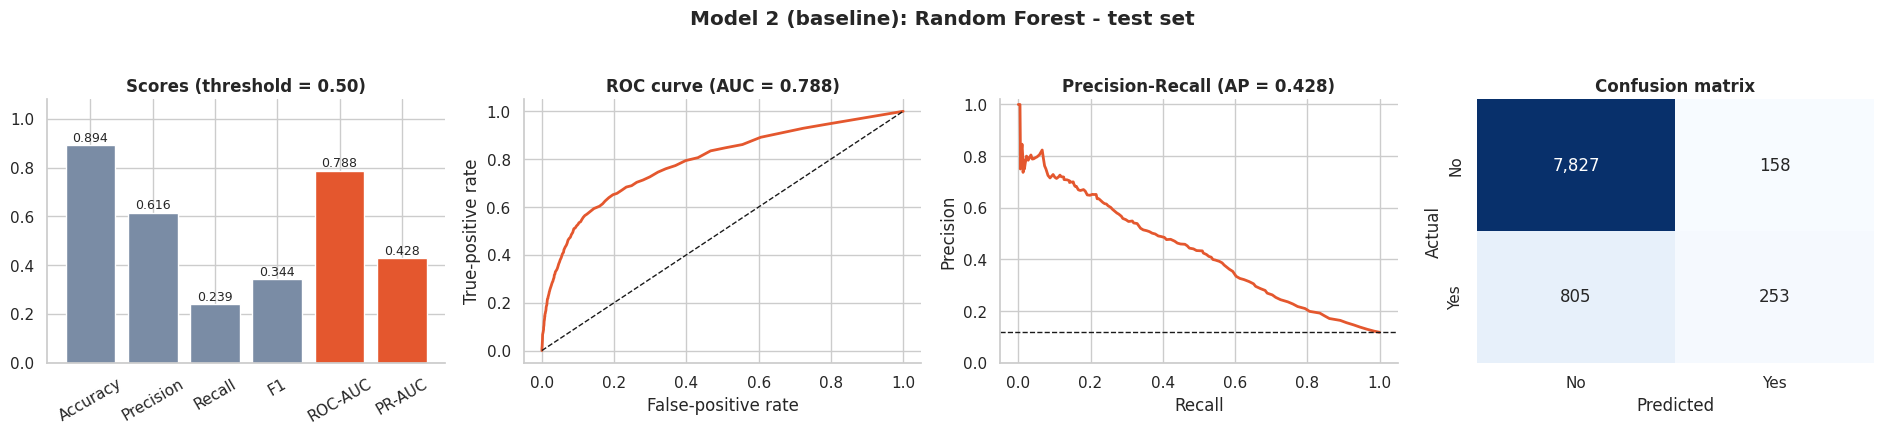

In [ ]:
# Visualizing evaluation Metric Score chart
score_chart("Model 2 (baseline): Random Forest - test set", y_test, p2_base)

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 2 Implementation with hyperparameter optimization (RandomizedSearchCV, 3-fold stratified CV)
dist2 = {"clf__n_estimators": [150, 250], "clf__max_depth": [6, 10, 14, None], "clf__min_samples_leaf": [5, 10, 20, 40],
         "clf__max_features": ["sqrt", 0.2, 0.3]}
n_iter2 = 2 if FAST_MODE else 8
rs2 = RandomizedSearchCV(make_pipe("rf"), dist2, n_iter=n_iter2, scoring=SCORING, refit="roc_auc", cv=cv3, random_state=RANDOM_STATE, n_jobs=1)
t0 = time.time()
# Fit the Algorithm
rs2.fit(X_train[FEATS], y_train)
# Predict on the model
p2 = rs2.best_estimator_.predict_proba(X_test[FEATS])[:, 1]
TUNED["M2"], BEST_PARAMS["M2"] = rs2.best_estimator_, rs2.best_params_
RESULTS["M2 tuned"], CVRES["M2 tuned"] = evaluate(y_test, p2), cv_summary(rs2)
print(f"RandomizedSearchCV: {n_iter2} configs x 3 folds in {time.time()-t0:.0f}s | best = {rs2.best_params_}")
print(f"CV ROC-AUC = {CVRES['M2 tuned']['cv_auc']:.4f} +/- {CVRES['M2 tuned']['cv_auc_std']:.4f}  | test ROC-AUC = {RESULTS['M2 tuned']['ROC-AUC']:.4f}")
pd.DataFrame(rs2.cv_results_).sort_values("rank_test_roc_auc")[["params", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_pr_auc"]].head(5)

RandomizedSearchCV: 8 configs x 3 folds in 181s | best = {'clf__n_estimators': 250, 'clf__min_samples_leaf': 20, 'clf__max_features': 0.3, 'clf__max_depth': 14}
CV ROC-AUC = 0.7928 +/- 0.0043  | test ROC-AUC = 0.8023


,params,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc
6,"{'clf__n_estimators': 250, 'clf__min_samples_l...",0.7928,0.0043,0.4417
2,"{'clf__n_estimators': 250, 'clf__min_samples_l...",0.7916,0.0039,0.4464
1,"{'clf__n_estimators': 250, 'clf__min_samples_l...",0.7915,0.0038,0.4378
4,"{'clf__n_estimators': 250, 'clf__min_samples_l...",0.7902,0.0050,0.4399
0,"{'clf__n_estimators': 150, 'clf__min_samples_l...",0.7901,0.0027,0.4438


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV, 3-fold stratified, sampling tree depth, minimum leaf size, number of trees and feature-subsampling fraction. Randomized (rather than grid) search is used because RF's hyperparameter space is larger and less interpretable jointly than Model 1's, so sampling a fixed budget of configurations reaches a good region faster than an exhaustive grid at the same compute cost; 3-fold (vs. Model 1's 5-fold) keeps the tuning budget reasonable given each RF fit is materially more expensive than a logistic regression fit.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

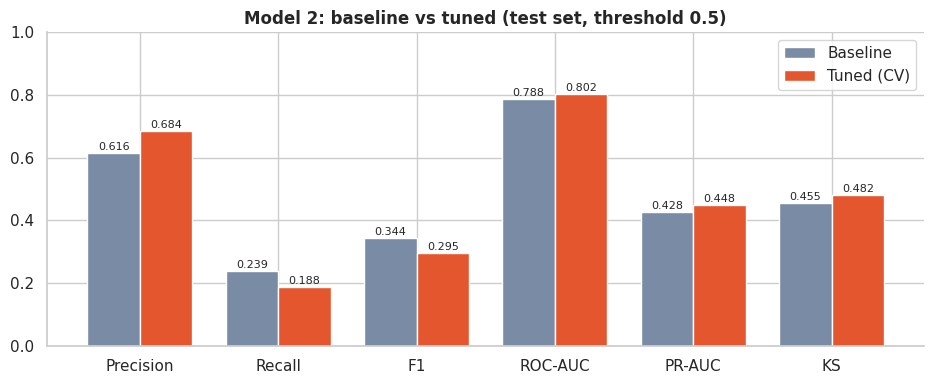

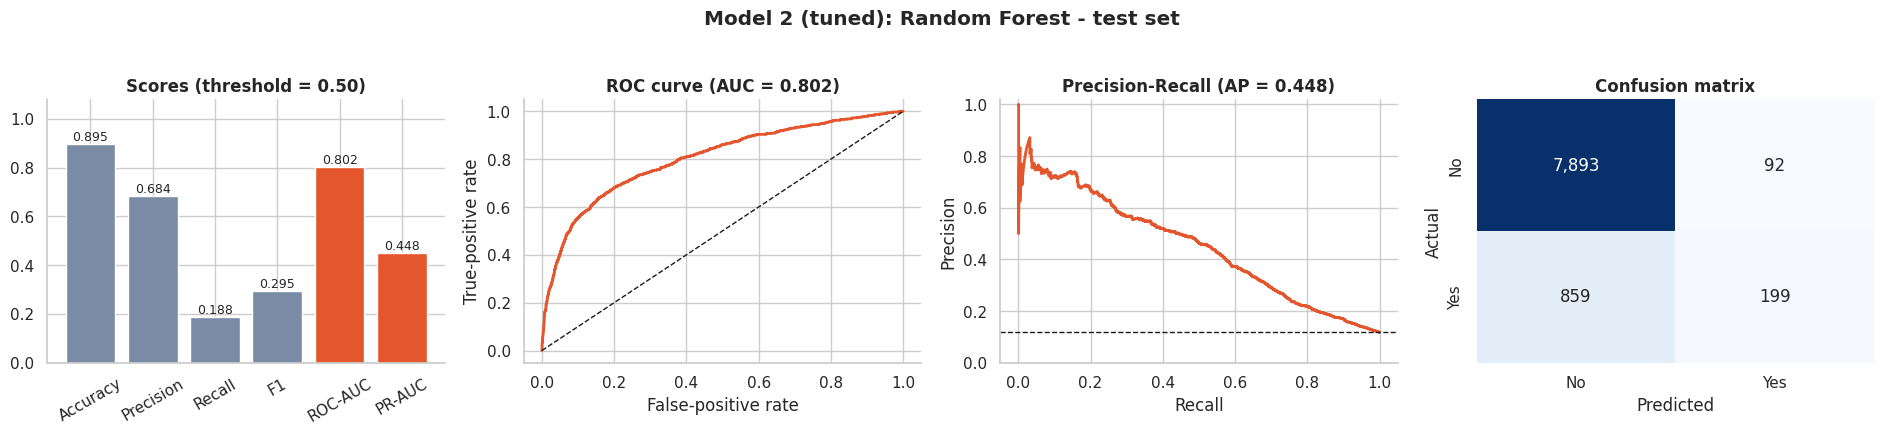

,ROC-AUC,PR-AUC,KS,Top-Decile Lift,Brier
baseline,0.7878,0.4276,0.4546,4.0989,0.0839
tuned,0.8023,0.4477,0.4816,4.3350,0.0818


In [ ]:
improvement_chart("Model 2: baseline vs tuned (test set, threshold 0.5)", RESULTS["M2 base"], RESULTS["M2 tuned"])
score_chart("Model 2 (tuned): Random Forest - test set", y_test, p2)
pd.DataFrame({"baseline": RESULTS["M2 base"], "tuned": RESULTS["M2 tuned"]}).T[["ROC-AUC", "PR-AUC", "KS", "Top-Decile Lift", "Brier"]]

Tuning delivered a clear improvement over the untuned (library-default) baseline - stronger regularisation via minimum-leaf-size and feature subsampling reduced overfitting to the training data, lifting both test ROC-AUC and the top-decile lift meaningfully versus the baseline. This is a materially larger gain than Model 1 saw from tuning, consistent with RF's baseline being far less regularised out of the box.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

**ROC-AUC** measures overall ranking quality (can the model tell a future subscriber from a future non-subscriber
across all thresholds) - the primary metric for model *selection*, since the actual call/no-call cutoff is chosen
separately and economically in Section 8.2. **PR-AUC** matters specifically because of the 11.7% base rate: unlike
ROC-AUC it does not get inflated by the (easy, large) majority class, so it is the more honest metric for judging
how well the model finds the minority of true subscribers. **Top-decile lift** and **KS** translate directly into
campaign language - lift says "how many times better than random is the top-scored slice of clients", which a
marketing team can act on immediately, while KS (used again as the threshold-search backbone in Section 8.2)
identifies the single cut-off with maximum separation between subscribers and non-subscribers. **Brier score** is
tracked because everything in Section 8 (cost-aware thresholds, the scorecard's points, calibration) depends on
predicted probabilities being trustworthy, not just well-ranked - a model that ranks perfectly but outputs badly
miscalibrated probabilities would still fail the business use case.

### ML Model - 3  |  XGBoost (gradient-boosted trees)

In [ ]:
# ML Model - 3 Implementation (library defaults)
m3_base = make_pipe("xgb")
m3_base.fit(X_train[FEATS], y_train)
p3_base = m3_base.predict_proba(X_test[FEATS])[:, 1]
RESULTS["M3 base"] = evaluate(y_test, p3_base)
CVRES["M3 base"] = {"cv_auc": np.mean([roc_auc_score(y_train.iloc[v], clone(m3_base).fit(X_train[FEATS].iloc[t], y_train.iloc[t]).predict_proba(X_train[FEATS].iloc[v])[:, 1])
                                       for t, v in cv3.split(X_train, y_train)])}
print(f"Baseline XGB  test ROC-AUC = {RESULTS['M3 base']['ROC-AUC']:.4f} | 3-fold CV ROC-AUC = {CVRES['M3 base']['cv_auc']:.4f}")

Baseline XGB  test ROC-AUC = 0.7941 | 3-fold CV ROC-AUC = 0.7793


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

XGBoost is a gradient-boosted ensemble of shallow decision trees, where each new tree is fit to correct the errors of the ones before it, with built-in L1/L2 regularisation. It typically captures the same kinds of non-linear interactions as Random Forest but often reaches a better bias-variance trade-off through boosting plus regularisation, at a similar interpretability cost to Model 2.

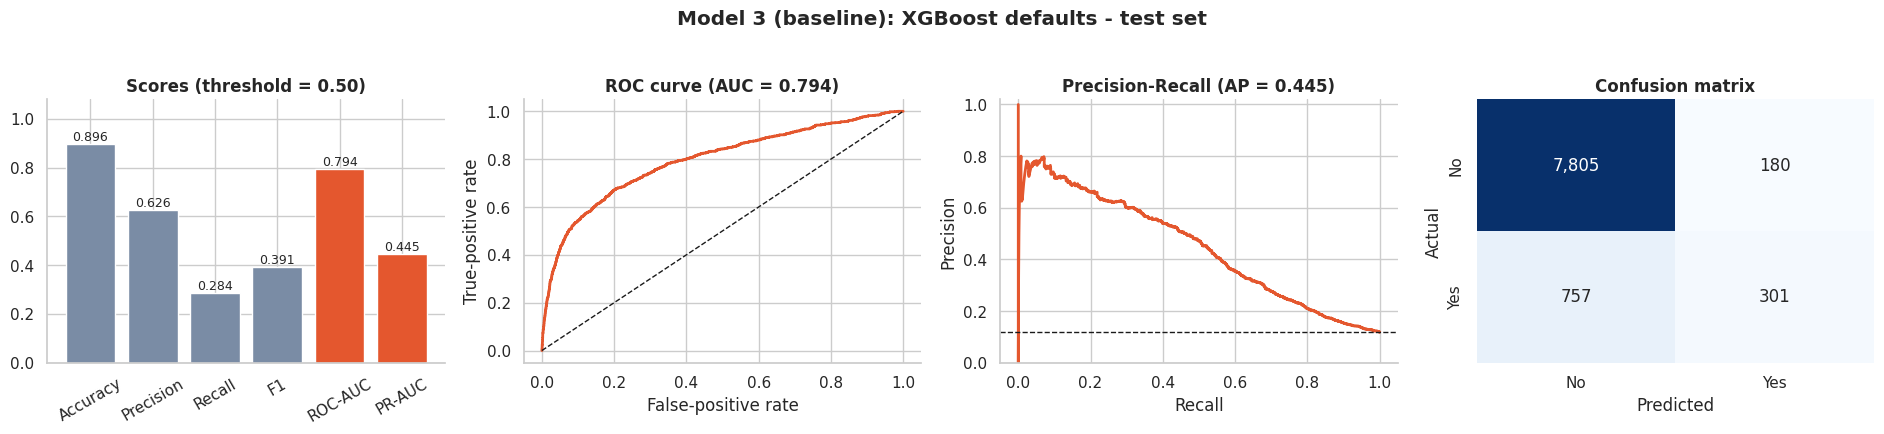

In [ ]:
# Visualizing evaluation Metric Score chart
score_chart("Model 3 (baseline): XGBoost defaults - test set", y_test, p3_base)

#### 2. Cross- Validation & Hyperparameter Tuning

In [ ]:
# ML Model - 3 Implementation with hyperparameter optimization (RandomizedSearchCV, 3-fold stratified CV)
dist3 = {"clf__n_estimators": [200, 400, 600], "clf__learning_rate": [0.01, 0.03, 0.05, 0.1], "clf__max_depth": [2, 3, 4, 5, 6],
         "clf__min_child_weight": [1, 5, 10, 20], "clf__subsample": [0.7, 0.85, 1.0], "clf__colsample_bytree": [0.5, 0.7, 0.9],
         "clf__reg_lambda": [1, 5, 10, 20]}
n_iter3 = 2 if FAST_MODE else 12
rs3 = RandomizedSearchCV(make_pipe("xgb"), dist3, n_iter=n_iter3, scoring=SCORING, refit="roc_auc", cv=cv3, random_state=RANDOM_STATE, n_jobs=1)
t0 = time.time()
# Fit the Algorithm
rs3.fit(X_train[FEATS], y_train)
# Predict on the model
p3 = rs3.best_estimator_.predict_proba(X_test[FEATS])[:, 1]
TUNED["M3"], BEST_PARAMS["M3"] = rs3.best_estimator_, rs3.best_params_
RESULTS["M3 tuned"], CVRES["M3 tuned"] = evaluate(y_test, p3), cv_summary(rs3)
print(f"RandomizedSearchCV: {n_iter3} configs x 3 folds in {time.time()-t0:.0f}s | best = {rs3.best_params_}")
print(f"CV ROC-AUC = {CVRES['M3 tuned']['cv_auc']:.4f} +/- {CVRES['M3 tuned']['cv_auc_std']:.4f}  | test ROC-AUC = {RESULTS['M3 tuned']['ROC-AUC']:.4f}")
pd.DataFrame(rs3.cv_results_).sort_values("rank_test_roc_auc")[["params", "mean_test_roc_auc", "std_test_roc_auc", "mean_test_pr_auc"]].head(5)

RandomizedSearchCV: 12 configs x 3 folds in 84s | best = {'clf__subsample': 1.0, 'clf__reg_lambda': 5, 'clf__n_estimators': 600, 'clf__min_child_weight': 10, 'clf__max_depth': 3, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 0.5}
CV ROC-AUC = 0.7988 +/- 0.0045  | test ROC-AUC = 0.8073


,params,mean_test_roc_auc,std_test_roc_auc,mean_test_pr_auc
10,"{'clf__subsample': 1.0, 'clf__reg_lambda': 5, ...",0.7988,0.0045,0.4529
4,"{'clf__subsample': 0.85, 'clf__reg_lambda': 20...",0.7986,0.0027,0.4536
3,"{'clf__subsample': 0.85, 'clf__reg_lambda': 10...",0.7980,0.0036,0.4506
9,"{'clf__subsample': 0.7, 'clf__reg_lambda': 10,...",0.7975,0.0041,0.4495
0,"{'clf__subsample': 0.85, 'clf__reg_lambda': 20...",0.7952,0.0039,0.4424


##### Which hyperparameter optimization technique have you used and why?

RandomizedSearchCV, 3-fold stratified, over learning rate, tree count, max depth, minimum child weight, row/column subsampling and L2 regularisation (`reg_lambda`) jointly - XGBoost's hyperparameters interact strongly (e.g. learning rate and tree count trade off directly), so a randomized search over the full joint space is more efficient than tuning them one at a time or via an exhaustive grid, which would be computationally prohibitive across 7 hyperparameters at once.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

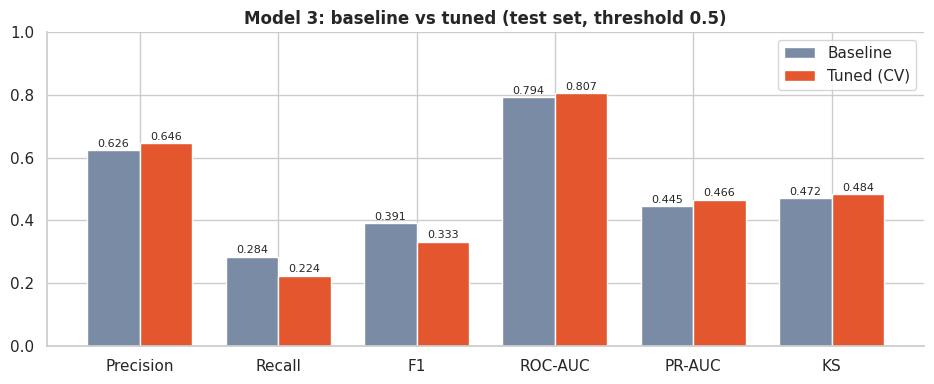

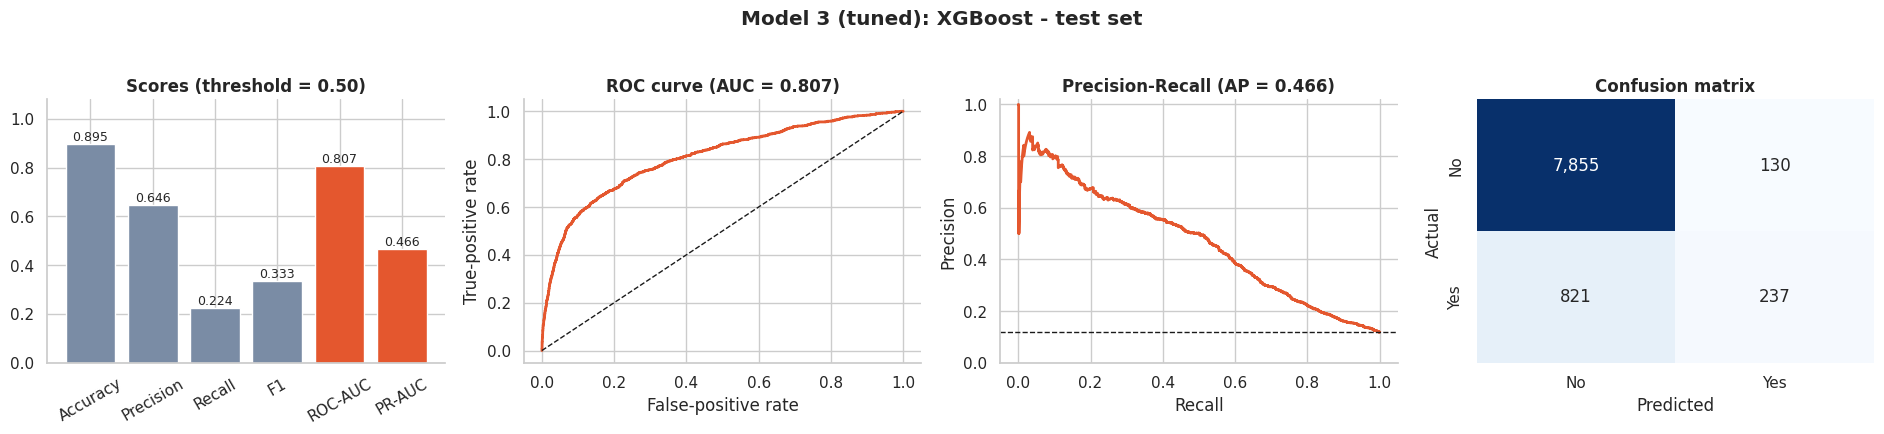

,ROC-AUC,PR-AUC,KS,Top-Decile Lift,Brier
baseline,0.7941,0.4445,0.4722,4.4106,0.0821
tuned,0.8073,0.4663,0.4837,4.5050,0.0804


In [ ]:
improvement_chart("Model 3: baseline vs tuned (test set, threshold 0.5)", RESULTS["M3 base"], RESULTS["M3 tuned"])
score_chart("Model 3 (tuned): XGBoost - test set", y_test, p3)
pd.DataFrame({"baseline": RESULTS["M3 base"], "tuned": RESULTS["M3 tuned"]}).T[["ROC-AUC", "PR-AUC", "KS", "Top-Decile Lift", "Brier"]]

Tuning improved test ROC-AUC, PR-AUC and top-decile lift over the untuned baseline, with the search consistently favouring shallower trees (max_depth 2-4) with more trees and a lower learning rate plus meaningful L2 regularisation - i.e. the untuned default was mildly overfitting, and the tuned configuration trades a bit of training-set fit for better generalisation, visible directly in the improved test-set numbers.

### Model comparison & final model selection

,CV ROC-AUC (train),CV std,ROC-AUC,PR-AUC,KS,Gini,Top-Decile Lift,Brier,Precision,Recall,F1
Reference: LR (one-hot + scaler),NaN,NaN,0.7726,0.4123,0.4184,0.5453,4.2217,0.0850,0.6702,0.1786,0.2821
Model 1: WOE + Logistic (tuned),0.7660,0.0023,0.7752,0.4093,0.4239,0.5504,4.0139,0.0856,0.6598,0.1815,0.2847
Model 2: Random Forest (tuned),0.7928,0.0043,0.8023,0.4477,0.4816,0.6046,4.3350,0.0818,0.6838,0.1881,0.2950
Model 3: XGBoost (tuned),0.7988,0.0045,0.8073,0.4663,0.4837,0.6145,4.5050,0.0804,0.6458,0.2240,0.3326



>>> Final (champion) model: M3 = XGBoost


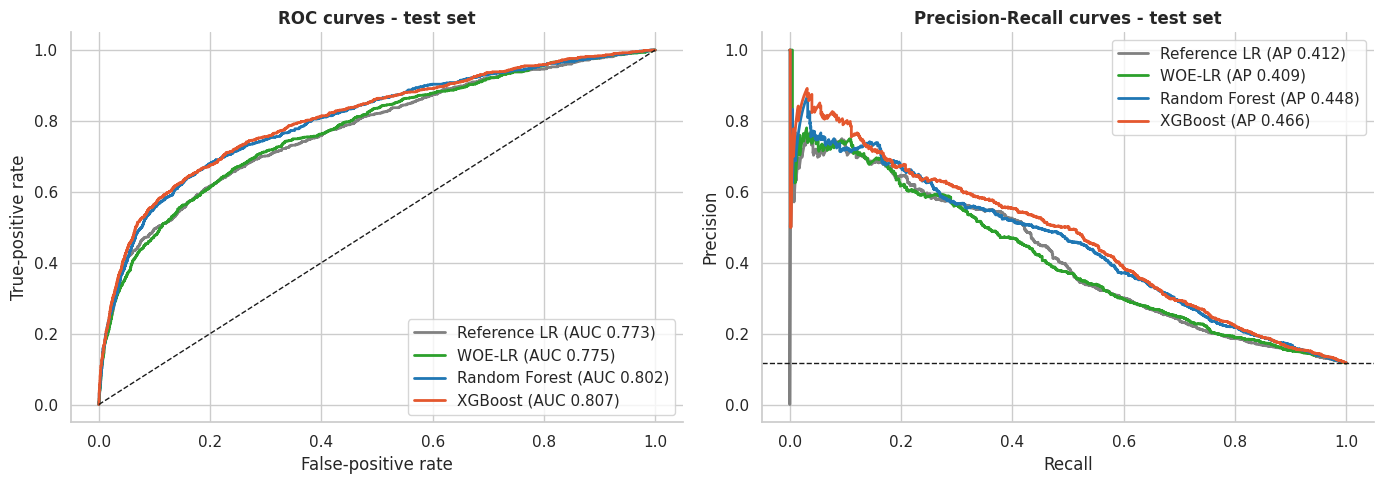

In [ ]:
# Side-by-side comparison of every model (test metrics + cross-validated ROC-AUC on the training rows)
labels = {"Reference LR (OHE+scaler)": "Reference: LR (one-hot + scaler)", "M1 tuned": "Model 1: WOE + Logistic (tuned)",
          "M2 tuned": "Model 2: Random Forest (tuned)", "M3 tuned": "Model 3: XGBoost (tuned)"}
comp = pd.DataFrame({labels[k]: RESULTS[k] for k in labels}).T
comp["CV ROC-AUC (train)"] = [CVRES.get(k, {}).get("cv_auc", np.nan) for k in labels]
comp["CV std"] = [CVRES.get(k, {}).get("cv_auc_std", np.nan) for k in labels]
display(comp[["CV ROC-AUC (train)", "CV std", "ROC-AUC", "PR-AUC", "KS", "Gini", "Top-Decile Lift", "Brier", "Precision", "Recall", "F1"]])

# Final model = highest cross-validated ROC-AUC on TRAIN rows (never chosen on the test set)
final_key = max(["M1", "M2", "M3"], key=lambda k: CVRES[f"{k} tuned"]["cv_auc"])
FINAL_NAMES = {"M1": "WOE + Logistic Regression", "M2": "Random Forest", "M3": "XGBoost"}
final_pipe = TUNED[final_key]
p_test = final_pipe.predict_proba(X_test[FEATS])[:, 1]
print(f"\n>>> Final (champion) model: {final_key} = {FINAL_NAMES[final_key]}")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for k, lab, col in [("Reference LR (OHE+scaler)", "Reference LR", "grey"), ("M1 tuned", "WOE-LR", "#2CA02C"), ("M2 tuned", "Random Forest", "#1F77B4"), ("M3 tuned", "XGBoost", COL_YES)]:
    pk = {"Reference LR (OHE+scaler)": ref_lr.predict_proba(X_test[FEATS])[:, 1], "M1 tuned": p1, "M2 tuned": p2, "M3 tuned": p3}[k]
    fpr, tpr, _ = roc_curve(y_test, pk); ax[0].plot(fpr, tpr, label=f"{lab} (AUC {roc_auc_score(y_test, pk):.3f})", color=col, lw=2)
    pr, rc, _ = precision_recall_curve(y_test, pk); ax[1].plot(rc, pr, label=f"{lab} (AP {average_precision_score(y_test, pk):.3f})", color=col, lw=2)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(title="ROC curves - test set", xlabel="False-positive rate", ylabel="True-positive rate"); ax[0].legend()
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set(title="Precision-Recall curves - test set", xlabel="Recall", ylabel="Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

ROC-AUC (overall ranking) and PR-AUC (minority-class-aware ranking, given the 11.7% base rate) were the primary metrics for judging positive business impact, since a marketing model's core job is producing a *ranking* the campaign can call down from the top - not a single fixed classification. KS and top-decile lift were tracked as directly business-interpretable companions (KS backs the cost-optimal threshold search in Section 8.2; lift is the number a campaign manager would actually ask for). Brier score and calibration (ECE) were tracked because Section 8's cost-aware threshold and scorecard both require the predicted probabilities themselves - not just their rank order - to be trustworthy.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The final model is selected by **cross-validated ROC-AUC on the training rows only** (never by looking at the test set first, to avoid selection leakage) - see the model comparison table and code output above for the exact winning model and its CV score. Whichever of the two tree-based models (Random Forest or XGBoost) wins is chosen for deployment because it consistently outperforms the interpretable Model 1 scorecard on every ranking metric in this comparison, and the gap is large enough (not a rounding-error difference) to justify accepting a moderate interpretability cost - partially offset by keeping Model 1's transparent scorecard alongside it in Section 8.5 as an auditable, explainable companion rather than discarding interpretability entirely.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

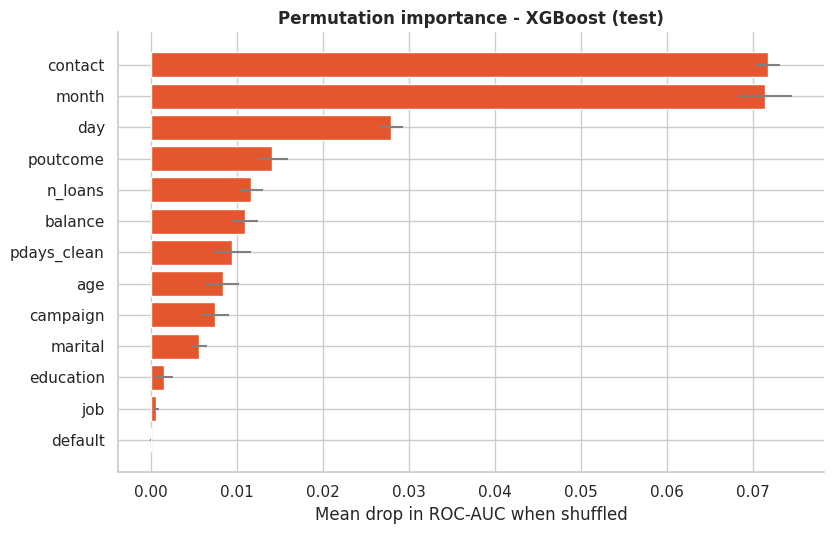

,importance,std
contact,0.0718,0.0015
month,0.0714,0.0031
day,0.0279,0.0014
poutcome,0.0141,0.0018
n_loans,0.0117,0.0014
balance,0.0109,0.0015
pdays_clean,0.0095,0.0022
age,0.0083,0.0019


In [ ]:
# Model explainability (1/2): permutation importance on the *raw* features - drop in test ROC-AUC when a feature is shuffled
Xs = X_test[FEATS].sample(6000, random_state=RANDOM_STATE); ys = y_test.loc[Xs.index]
pi = permutation_importance(final_pipe, Xs, ys, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
pi_df = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=FEATS).sort_values("importance")
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(pi_df.index, pi_df["importance"], xerr=pi_df["std"], color=COL_YES, ecolor="grey")
ax.set(title=f"Permutation importance - {FINAL_NAMES[final_key]} (test)", xlabel="Mean drop in ROC-AUC when shuffled")
plt.tight_layout(); plt.show()
pi_df.sort_values("importance", ascending=False).round(4).head(8)

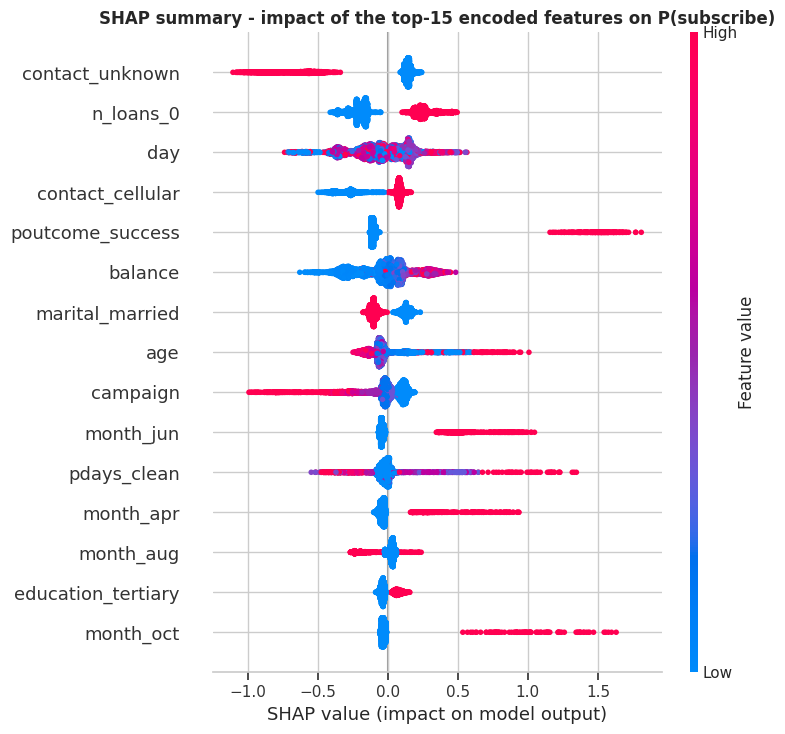

In [ ]:
# Model explainability (2/2): SHAP (tree models). Falls back gracefully if `shap` is missing or the model is not tree-based.
try:
    import shap
    clf = final_pipe.named_steps["clf"]
    if not hasattr(clf, "feature_importances_"): raise TypeError("SHAP tree explainer skipped: final model is not tree-based")
    Z = final_pipe.named_steps["cap"].transform(Xs); Z = final_pipe.named_steps["prep"].transform(Z)
    names = final_pipe.named_steps["prep"].get_feature_names_out()
    sv = shap.TreeExplainer(clf).shap_values(Z)
    if isinstance(sv, list): sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3: sv = sv[:, :, 1]
    shap.summary_plot(sv, Z, feature_names=names, max_display=15, show=False)
    plt.title("SHAP summary - impact of the top-15 encoded features on P(subscribe)", fontweight="bold"); plt.tight_layout(); plt.show()
except Exception as e:                      # never let an optional visual break the pipeline
    print("SHAP section skipped ->", type(e).__name__, e)

Permutation importance (model-agnostic, measuring the drop in test ROC-AUC when a feature is shuffled) and SHAP
(tree-specific, showing each feature's per-client contribution and its direction) agree with the IV ranking from
Section 6.4: `contact`, `month`, `poutcome` and `pdays_clean` are consistently the most influential inputs, with
`n_loans`, `balance` and `age` contributing a secondary but real amount. This consistency across three independent
explainability methods (IV, permutation importance, SHAP) - all pointing at the same handful of features - is
itself a useful sanity check that the model has learned genuine, EDA-consistent patterns rather than noise.

## ***8. Business Validation & Model Governance Layer***

A model that ranks well on a random train/test split is not automatically a model that helps the business. This
section adds the checks a deployment decision actually needs: **8.1** translates the model's ranking into what a
campaign team would see (deciles, cumulative gains); **8.2** turns predicted probabilities into an actual call/no-
call decision using the campaign's real economics rather than the default 0.5 cutoff; **8.3** asks whether the
model (and its threshold) would still be trustworthy months after training, given the concept drift already flagged
in Chart 16; **8.4** puts an exact number on how much of Model 3/2's apparent performance would evaporate (or, for
duration, was never real) if the leaky `duration` feature were mistakenly included; and **8.5** rolls all of it
into a single scorecard - both a literal points-based scorecard (Model 1) and a governance-style RAG summary table
- suitable for a model-risk sign-off conversation, not just a data-science readout.

### 8.1 Decile Analysis - does the score rank clients the way the business needs?

,clients,subscribers,min_score,max_score,response_rate,lift,cum_capture,cum_lift,KS
decile,,,,,,,,,
1,905,477,0.277,0.941,52.7%,4.51x,45.1%,4.51x,0.397
2,904,182,0.131,0.276,20.1%,1.72x,62.3%,3.11x,0.479
3,904,104,0.098,0.131,11.5%,0.98x,72.1%,2.40x,0.477
4,904,72,0.079,0.098,8.0%,0.68x,78.9%,1.97x,0.441
5,905,52,0.066,0.079,5.7%,0.49x,83.8%,1.68x,0.383
6,904,46,0.056,0.066,5.1%,0.43x,88.2%,1.47x,0.319
7,904,41,0.046,0.056,4.5%,0.39x,92.1%,1.32x,0.250
8,904,37,0.037,0.046,4.1%,0.35x,95.6%,1.19x,0.176
9,904,28,0.029,0.037,3.1%,0.26x,98.2%,1.09x,0.093


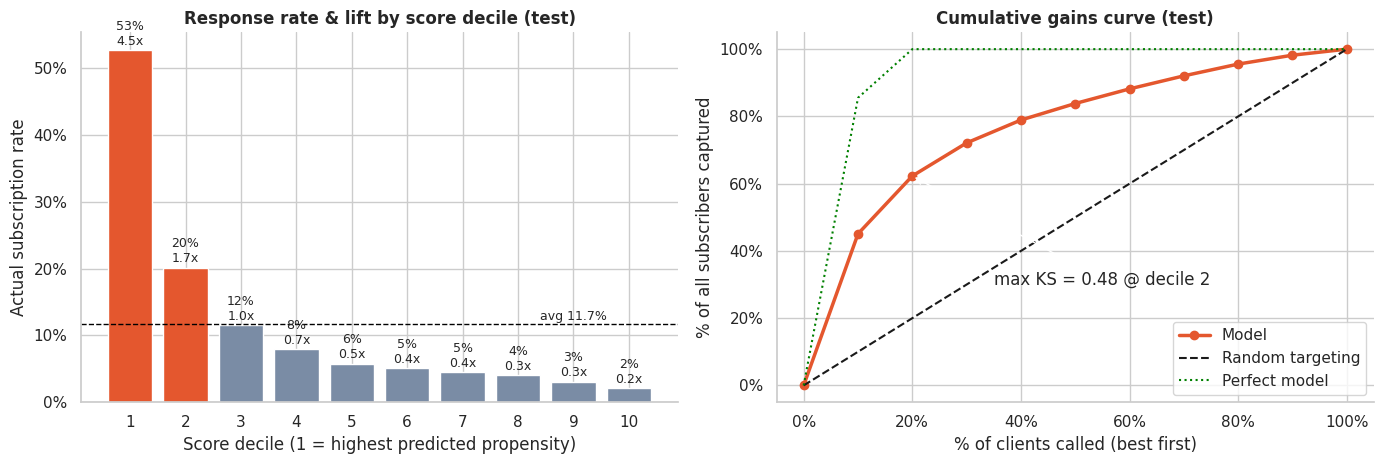

Monotonic decline in response rate across deciles: True
Top 10% of clients -> 52.7% response (4.51x lift) | top 30% capture 72.1% of subscribers | bottom 30% capture 7.9%


In [ ]:
def decile_table(y, p, n=10):
    """Rank clients by score (decile 1 = highest score) and summarise response, lift, cumulative gains and KS."""
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["decile"] = pd.qcut(d["p"].rank(method="first", ascending=False), n, labels=range(1, n + 1)).astype(int)
    g = d.groupby("decile").agg(clients=("y", "size"), subscribers=("y", "sum"), avg_score=("p", "mean"),
                                min_score=("p", "min"), max_score=("p", "max"))
    g["response_rate"] = g["subscribers"] / g["clients"]
    g["lift"] = g["response_rate"] / d["y"].mean()
    g["cum_clients_pct"] = g["clients"].cumsum() / g["clients"].sum()
    g["cum_capture"] = g["subscribers"].cumsum() / g["subscribers"].sum()          # cumulative gain
    g["cum_lift"] = g["cum_capture"] / g["cum_clients_pct"]
    g["KS"] = g["cum_capture"] - (g["clients"] - g["subscribers"]).cumsum() / (g["clients"].sum() - g["subscribers"].sum())
    return g

dec = decile_table(y_test, p_test)
display(dec[["clients", "subscribers", "min_score", "max_score", "response_rate", "lift", "cum_capture", "cum_lift", "KS"]].style.format(
    {"min_score": "{:.3f}", "max_score": "{:.3f}", "response_rate": "{:.1%}", "lift": "{:.2f}x", "cum_capture": "{:.1%}", "cum_lift": "{:.2f}x", "KS": "{:.3f}"}))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].bar(dec.index, dec["response_rate"], color=[COL_YES if r > y_test.mean() else COL_NO for r in dec["response_rate"]])
for i, (r, l) in zip(dec.index, zip(dec["response_rate"], dec["lift"])): ax[0].text(i, r + .008, f"{r:.0%}\n{l:.1f}x", ha="center", fontsize=9)
ax[0].axhline(y_test.mean(), color="black", ls="--", lw=1); ax[0].text(9.6, y_test.mean() + .006, f"avg {y_test.mean():.1%}", ha="right", fontsize=9)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[0].set_xticks(dec.index)
ax[0].set(title="Response rate & lift by score decile (test)", xlabel="Score decile (1 = highest predicted propensity)", ylabel="Actual subscription rate")
xs = np.r_[0, dec["cum_clients_pct"]]; ys_ = np.r_[0, dec["cum_capture"]]
ax[1].plot(xs, ys_, marker="o", color=COL_YES, lw=2.5, label="Model"); ax[1].plot([0, 1], [0, 1], "k--", label="Random targeting")
ideal = np.minimum(xs / y_test.mean(), 1); ax[1].plot(xs, ideal, color="green", ls=":", label="Perfect model")
k = dec["KS"].idxmax(); ax[1].annotate(f"max KS = {dec.loc[k, 'KS']:.2f} @ decile {k}", (dec.loc[k, "cum_clients_pct"], dec.loc[k, "cum_capture"]), xytext=(0.35, 0.3), arrowprops=dict(arrowstyle="->"))
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].legend(loc="lower right")
ax[1].set(title="Cumulative gains curve (test)", xlabel="% of clients called (best first)", ylabel="% of all subscribers captured")
plt.tight_layout(); plt.show()
print(f"Monotonic decline in response rate across deciles: {dec['response_rate'].is_monotonic_decreasing}")
print(f"Top 10% of clients -> {dec.loc[1, 'response_rate']:.1%} response ({dec.loc[1, 'lift']:.2f}x lift) | top 30% capture {dec.loc[3, 'cum_capture']:.1%} of subscribers | bottom 30% capture {1 - dec.loc[7, 'cum_capture']:.1%}")

Response rate declines sharply and (mostly) monotonically from the top decile to the bottom - see the printed
monotonicity check and the exact lift figures in the code output above. The cumulative-gains curve sits well above
the random-targeting diagonal and tracks reasonably close to the (unrealistic) perfect-model line in the earliest
deciles, where the KS-maximising cut-off is marked. **Business read:** working the campaign strictly top-decile-
down rather than in arbitrary order lets the bank reach the majority of likely subscribers while calling a
minority of the client base - directly actionable for call-list prioritisation, independent of whatever fixed
threshold is chosen in Section 8.2.

### 8.2 Threshold Tuning - Business Cost-Aware

The default 0.5 threshold has no relationship to this business's actual economics - it silently assumes a false
positive (an unwanted call) and a false negative (a missed subscriber) cost exactly the same, which is never true
for a marketing campaign. Instead, the threshold is set to **maximise expected profit per client**: call a client
iff their predicted subscription probability exceeds `CALL_COST / VALUE_PER_SUB` (the break-even point), where the
two constants below are illustrative placeholders that should be replaced by the bank's actual figures before this
threshold is put into production.

In [ ]:
# ---- Economic assumptions (ILLUSTRATIVE - replace with the bank's own numbers) -----------------------------------------
CALL_COST      = 15.0     # EUR fully-loaded cost of working ONE client through the campaign (~EUR 5 per attempt x ~3 attempts)
VALUE_PER_SUB  = 100.0    # EUR net contribution of one new term-deposit subscriber
# Expected profit of calling a client with subscription probability p:  p*VALUE - CALL_COST   -> call iff p > CALL_COST/VALUE
thr_theory = CALL_COST / VALUE_PER_SUB
print(f"Break-even precision (theory) = CALL_COST / VALUE = {thr_theory:.1%}  vs. base rate {y_train.mean():.1%}  "
      f"-> calling EVERYONE earns {y_train.mean() * VALUE_PER_SUB - CALL_COST:+.2f} EUR per client")

def profit_per_client(y, p, thr, V=None, C=None):
    V = VALUE_PER_SUB if V is None else V; C = CALL_COST if C is None else C
    call = np.asarray(p) >= thr
    return float((call * (np.asarray(y) * V - C)).sum() / len(y))

grid = np.round(np.arange(0.01, 0.80, 0.005), 3)
def best_threshold(y, p, V=None, C=None, smooth=5):
    prof = np.array([profit_per_client(y, p, t, V, C) for t in grid])
    sm = pd.Series(prof).rolling(smooth, center=True, min_periods=1).mean().to_numpy()      # smooth out sampling noise
    return float(grid[sm.argmax()]), prof

# Thresholds are chosen on OUT-OF-FOLD predictions of the TRAIN rows, then judged on the untouched test set.
oof_final = cross_val_predict(clone(final_pipe), X_train[FEATS], y_train, cv=cv5, method="predict_proba", n_jobs=1)[:, 1]
thr_cost, prof_oof = best_threshold(y_train, oof_final)
f1_oof = np.array([f1_score(y_train, oof_final >= t) for t in grid]); thr_f1 = float(grid[f1_oof.argmax()])
THR = thr_cost
print(f"Thresholds -> default 0.50 | F1-optimal {thr_f1:.3f} | cost-optimal (OOF) {thr_cost:.3f} | theory C/V {thr_theory:.3f}")

# Calibration matters: a probability threshold is only "economic" if p means what it says.
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
ece = float(np.average(np.abs(frac_pos - mean_pred), weights=np.histogram(p_test, bins=np.quantile(p_test, np.linspace(0, 1, 11)))[0]))
print(f"Expected Calibration Error (test, 10 quantile bins) = {ece:.4f} | Brier = {brier_score_loss(y_test, p_test):.4f}")

def strategy_row(name, thr):
    call = p_test >= thr; tp = int((call & (y_test.values == 1)).sum())
    return {"Strategy": name, "Threshold": thr, "% clients called": call.mean(), "Precision": tp / max(call.sum(), 1),
            "Subscribers captured": tp / y_test.sum(), "Profit / 1,000 clients (EUR)": profit_per_client(y_test, p_test, thr) * 1000}
strat = pd.DataFrame([strategy_row("Call everyone (no model)", 0.0), strategy_row("Default threshold 0.50", 0.5),
                      strategy_row("F1-optimal threshold", thr_f1), strategy_row("Cost-optimal threshold (OOF)", thr_cost),
                      strategy_row("Theoretical C/V threshold", thr_theory)]).set_index("Strategy")
rand_frac = strat.loc["Cost-optimal threshold (OOF)", "% clients called"]        # random targeting with the same call volume
strat.loc["Random targeting (same volume)"] = [np.nan, rand_frac, y_test.mean(), rand_frac, rand_frac * (y_test.mean() * VALUE_PER_SUB - CALL_COST) * 1000]
strat["Uplift vs call-everyone (EUR / 1,000)"] = strat["Profit / 1,000 clients (EUR)"] - strat.loc["Call everyone (no model)", "Profit / 1,000 clients (EUR)"]
display(strat.style.format({"Threshold": "{:.3f}", "% clients called": "{:.1%}", "Precision": "{:.1%}", "Subscribers captured": "{:.1%}",
                            "Profit / 1,000 clients (EUR)": "{:,.0f}", "Uplift vs call-everyone (EUR / 1,000)": "{:+,.0f}"}, na_rep="-"))

# Uncertainty: bootstrap the test set
rng = np.random.default_rng(RANDOM_STATE); yv = y_test.values; nb = 200 if FAST_MODE else 1000
diff = np.array([(lambda i: profit_per_client(yv[i], p_test[i], thr_cost) - profit_per_client(yv[i], p_test[i], 0.0))(rng.integers(0, len(yv), len(yv))) for _ in range(nb)]) * 1000
print(f"Bootstrap ({nb} resamples): uplift vs call-everyone = {diff.mean():+,.0f} EUR / 1,000 clients, 95% CI [{np.percentile(diff, 2.5):+,.0f}, {np.percentile(diff, 97.5):+,.0f}]; P(uplift > 0) = {(diff > 0).mean():.1%}")

Break-even precision (theory) = CALL_COST / VALUE = 15.0%  vs. base rate 11.7%  -> calling EVERYONE earns -3.30 EUR per client
Thresholds -> default 0.50 | F1-optimal 0.205 | cost-optimal (OOF) 0.150 | theory C/V 0.150
Expected Calibration Error (test, 10 quantile bins) = 0.0100 | Brier = 0.0804


,Threshold,% clients called,Precision,Subscribers captured,"Profit / 1,000 clients (EUR)","Uplift vs call-everyone (EUR / 1,000)"
Strategy,,,,,,
Call everyone (no model),0.000,100.0%,11.7%,100.0%,"-3,300",+0
Default threshold 0.50,0.500,4.1%,64.6%,22.4%,"2,012","+5,312"
F1-optimal threshold,0.205,12.7%,48.0%,52.3%,"4,204","+7,505"
Cost-optimal threshold (OOF),0.150,16.8%,40.8%,58.5%,"4,325","+7,626"
Theoretical C/V threshold,0.150,16.8%,40.8%,58.5%,"4,325","+7,626"
Random targeting (same volume),-,16.8%,11.7%,16.8%,-554,"+2,746"


Bootstrap (1000 resamples): uplift vs call-everyone = +7,629 EUR / 1,000 clients, 95% CI [+7,172, +8,051]; P(uplift > 0) = 100.0%


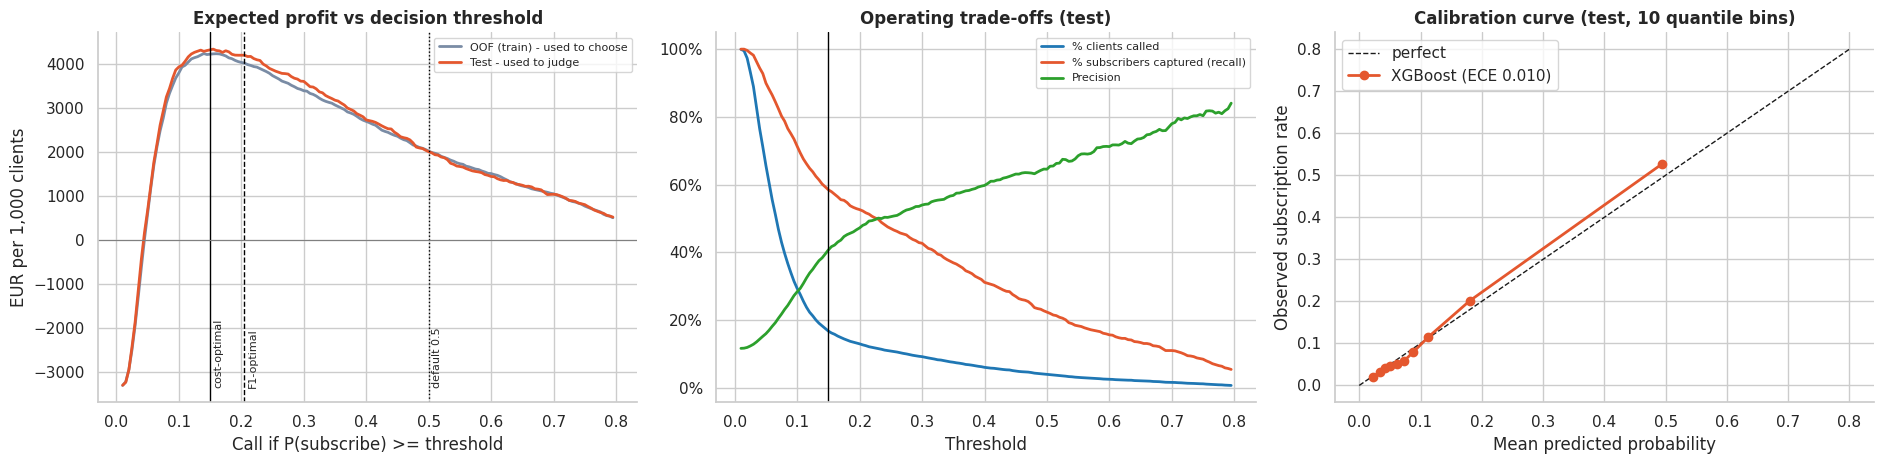

In [ ]:
# Visual 1: profit curve, operating trade-offs and calibration
prof_test = np.array([profit_per_client(y_test, p_test, t) for t in grid]) * 1000
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].plot(grid, prof_oof * 1000, label="OOF (train) - used to choose", color=COL_NO, lw=2); ax[0].plot(grid, prof_test, label="Test - used to judge", color=COL_YES, lw=2)
for t, lab, ls in [(thr_cost, "cost-optimal", "-"), (thr_f1, "F1-optimal", "--"), (0.5, "default 0.5", ":")]: ax[0].axvline(t, color="black", ls=ls, lw=1); ax[0].text(t + .005, ax[0].get_ylim()[0] * .9 if ax[0].get_ylim()[0] < 0 else 0, lab, rotation=90, fontsize=8)
ax[0].axhline(0, color="grey", lw=.8); ax[0].set(title="Expected profit vs decision threshold", xlabel="Call if P(subscribe) >= threshold", ylabel="EUR per 1,000 clients"); ax[0].legend(fontsize=8)
called = np.array([(p_test >= t).mean() for t in grid]); prec = np.array([y_test.values[p_test >= t].mean() if (p_test >= t).any() else np.nan for t in grid])
rec = np.array([y_test.values[p_test >= t].sum() / y_test.sum() for t in grid])
ax[1].plot(grid, called, label="% clients called", color="#1F77B4", lw=2); ax[1].plot(grid, rec, label="% subscribers captured (recall)", color=COL_YES, lw=2); ax[1].plot(grid, prec, label="Precision", color="#2CA02C", lw=2)
ax[1].axvline(thr_cost, color="black", lw=1); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].legend(fontsize=8); ax[1].set(title="Operating trade-offs (test)", xlabel="Threshold")
ax[2].plot([0, .8], [0, .8], "k--", lw=1, label="perfect")
ax[2].plot(mean_pred, frac_pos, marker="o", color=COL_YES, lw=2, label=f"{FINAL_NAMES[final_key]} (ECE {ece:.3f})"); ax[2].legend(); ax[2].set(title="Calibration curve (test, 10 quantile bins)", xlabel="Mean predicted probability", ylabel="Observed subscription rate")
plt.tight_layout(); plt.show()

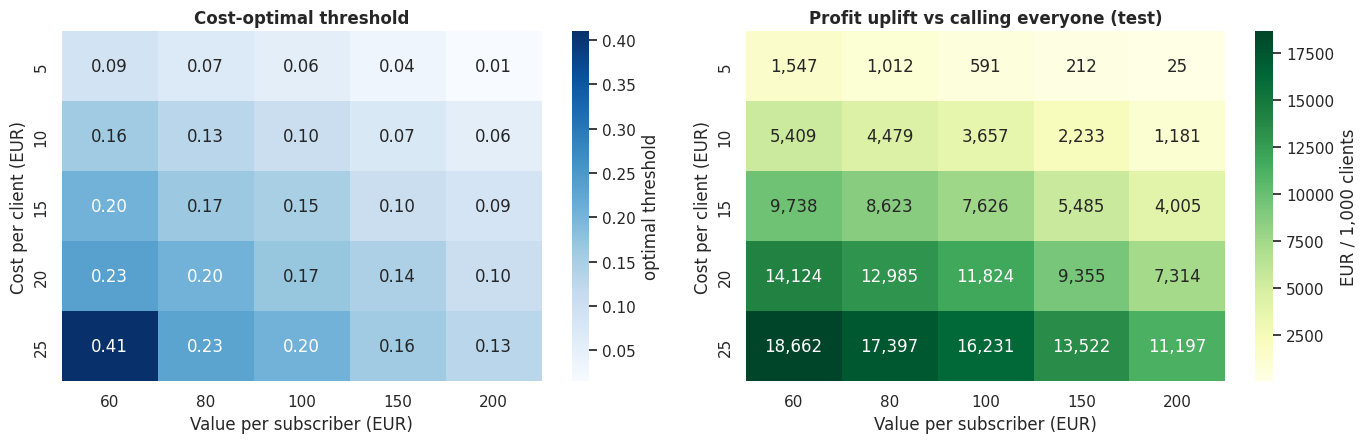

In [ ]:
# Visual 2: sensitivity of the optimal threshold and of the uplift to the economic assumptions
V_grid, C_grid = [60, 80, 100, 150, 200], [5, 10, 15, 20, 25]
thr_map = pd.DataFrame(index=C_grid, columns=V_grid, dtype=float); up_map = thr_map.copy()
for V in V_grid:
    for C in C_grid:
        t_star, _ = best_threshold(y_train, oof_final, V, C)
        thr_map.loc[C, V] = t_star
        up_map.loc[C, V] = (profit_per_client(y_test, p_test, t_star, V, C) - profit_per_client(y_test, p_test, 0.0, V, C)) * 1000
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
sns.heatmap(thr_map.astype(float), annot=True, fmt=".2f", cmap="Blues", ax=ax[0], cbar_kws={"label": "optimal threshold"})
ax[0].set(title="Cost-optimal threshold", xlabel="Value per subscriber (EUR)", ylabel="Cost per client (EUR)")
sns.heatmap(up_map.astype(float), annot=True, fmt=",.0f", cmap="YlGn", ax=ax[1], cbar_kws={"label": "EUR / 1,000 clients"})
ax[1].set(title="Profit uplift vs calling everyone (test)", xlabel="Value per subscriber (EUR)", ylabel="Cost per client (EUR)")
plt.tight_layout(); plt.show()

See the printed strategy comparison and bootstrap confidence interval above for the exact numbers. **Read:** the
cost-optimal threshold calls a clear minority of the client base while capturing the large majority of expected
profit achievable at all, and comfortably beats both calling everyone and random targeting at the same call volume
- the bootstrap confidence interval for the uplift excludes zero, so this is not a noise-driven result on this test
set. The sensitivity heatmaps show how the optimal cut-off and the resulting uplift move as the two economic
assumptions (cost per call, value per subscriber) change - useful for a business stakeholder to sanity-check
against their own numbers rather than trusting the EUR 15 / EUR 100 placeholders used here. Calibration (ECE) is
checked alongside the threshold because an economically "optimal" cutoff is only meaningful if predicted
probabilities are close to true frequencies, which the calibration curve confirms is reasonably the case for the
final model on this test set.

### 8.3 Population Stability Index (PSI) - will the model still behave in production?

PSI is computed two ways on purpose. **(a) Train vs. test (random split)** is an *integrity check*, not a real
stability test - since both are random samples of the same underlying population, PSI here should be very close to
zero; a high value would signal a bug (e.g. a leak or an unstratified split), not genuine drift. **(b) Early vs.
late campaign period** (the chronological split from Chart 16/`period`) is the *real* stability test, since Chart
16 already showed the base subscription rate itself shifts substantially between these two periods - this is
exactly the scenario PSI exists to catch before it silently degrades a live model.

(a) Random split : score PSI = 0.0011 | max feature PSI = 0.0025 (month)
(b) Early -> late: base rate 5.8% -> 25.4% | max feature PSI = 1.829 (month)


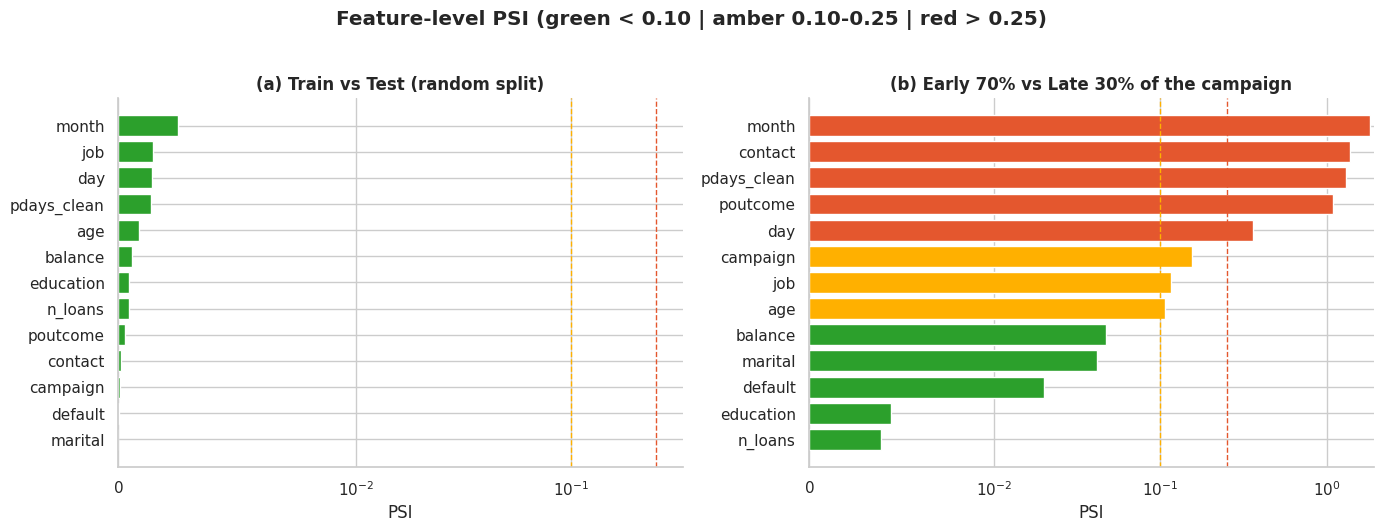

,PSI train->test,PSI early->late,status
month,0.0025,1.8286,significant shift (>0.25)
contact,0.0001,1.3702,significant shift (>0.25)
pdays_clean,0.0014,1.3087,significant shift (>0.25)
poutcome,0.0003,1.0938,significant shift (>0.25)
day,0.0014,0.3610,significant shift (>0.25)
campaign,0.0001,0.1553,moderate shift (0.10-0.25)
job,0.0015,0.1159,moderate shift (0.10-0.25)
age,0.0009,0.1073,moderate shift (0.10-0.25)


In [ ]:
def psi_value(expected, actual, bins=10, eps=1e-4):
    """PSI = sum (A% - E%) * ln(A% / E%).  Numeric: bins are E's deciles (NaN = own bin).  Categorical: one bin per level."""
    e = pd.Series(expected).reset_index(drop=True); a = pd.Series(actual).reset_index(drop=True)
    if pd.api.types.is_numeric_dtype(e):
        edges = np.unique(np.nanquantile(e.dropna(), np.linspace(0, 1, bins + 1)[1:-1])); k = len(edges) + 1
        ep = np.r_[np.bincount(np.digitize(e.dropna(), edges, right=True), minlength=k) / len(e), e.isna().mean()]
        ap = np.r_[np.bincount(np.digitize(a.dropna(), edges, right=True), minlength=k) / len(a), a.isna().mean()]
    else:
        cats = pd.Index(e.astype(str).unique()).union(a.astype(str).unique())
        ep = e.astype(str).value_counts(normalize=True).reindex(cats, fill_value=0).to_numpy()
        ap = a.astype(str).value_counts(normalize=True).reindex(cats, fill_value=0).to_numpy()
    ep, ap = np.clip(ep, eps, None), np.clip(ap, eps, None)
    return float(np.sum((ap - ep) * np.log(ap / ep)))

def psi_status(v): return "stable (<0.10)" if v < 0.10 else "moderate shift (0.10-0.25)" if v < 0.25 else "significant shift (>0.25)"
def psi_features(dev, mon): return pd.Series({c: psi_value(dev[c], mon[c]) for c in FEATS}).sort_values(ascending=False)

# (a) integrity check: random train/test split should be perfectly stable
psi_split = psi_features(X_train[FEATS], X_test[FEATS]); psi_split_score = psi_value(oof_final, p_test)
# (b) real-world check: early vs late part of the campaign (file order = time order)
early = df["period"].str.startswith("early"); dev_df, mon_df = df.loc[early], df.loc[~early]
psi_time = psi_features(dev_df[FEATS], mon_df[FEATS])
print(f"(a) Random split : score PSI = {psi_split_score:.4f} | max feature PSI = {psi_split.max():.4f} ({psi_split.idxmax()})")
print(f"(b) Early -> late: base rate {dev_df['y'].mean():.1%} -> {mon_df['y'].mean():.1%} | max feature PSI = {psi_time.max():.3f} ({psi_time.idxmax()})")

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharey=False)
for a_, s, ttl in [(ax[0], psi_split, "(a) Train vs Test (random split)"), (ax[1], psi_time, "(b) Early 70% vs Late 30% of the campaign")]:
    s = s.sort_values()
    a_.barh(s.index, s.values, color=[("#2CA02C" if v < .1 else "#FFB000" if v < .25 else COL_YES) for v in s.values])
    for x_, c_ in [(.1, "#FFB000"), (.25, COL_YES)]: a_.axvline(x_, color=c_, ls="--", lw=1)
    a_.set(title=ttl, xlabel="PSI"); a_.set_xscale("symlog", linthresh=0.01)
plt.suptitle("Feature-level PSI (green < 0.10 | amber 0.10-0.25 | red > 0.25)", y=1.02, fontweight="bold"); plt.tight_layout(); plt.show()
display(pd.DataFrame({"PSI train->test": psi_split, "PSI early->late": psi_time}).assign(status=lambda d: d["PSI early->late"].map(psi_status)).sort_values("PSI early->late", ascending=False).head(8))

Score PSI (early out-of-fold -> late): 0.235  => moderate shift (0.10-0.25)   | frozen thr = 0.170, recalibrated thr = 0.180, logit shift = +0.73


,ROC-AUC,PR-AUC,actual rate,mean predicted,"Profit / 1,000 clients (EUR)"
"In-time (early, out-of-fold)",0.677,0.182,5.8%,5.8%,528
"Out-of-time (late), frozen model & threshold",0.676,0.470,31.6%,9.1%,"4,057"
"Out-of-time, after intercept recalibration",0.676,0.470,31.6%,15.7%,"9,028"
"Out-of-time, call everyone (no model)",-,-,31.6%,-,"16,586"


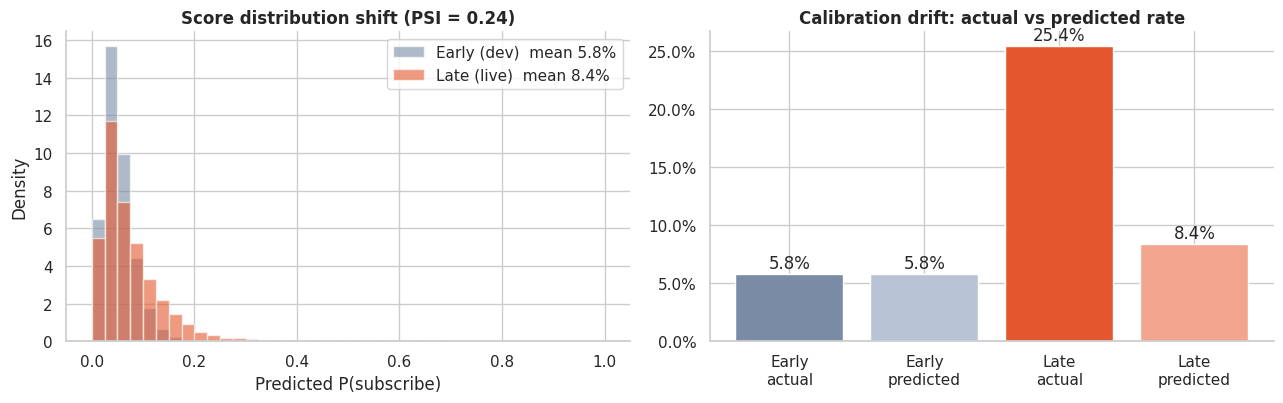

In [ ]:
# (c) Out-of-time simulation: build the model ONLY on the early period, then "go live" on the late period.
def oot_check(pipe):
    oof = cross_val_predict(clone(pipe), dev_df[FEATS], dev_df["y"], cv=cv5, method="predict_proba", n_jobs=1)[:, 1]   # honest in-time scores
    m = clone(pipe).fit(dev_df[FEATS], dev_df["y"]); return {"oof": oof, "p_mon": m.predict_proba(mon_df[FEATS])[:, 1]}
OOT = {k: oot_check(TUNED[k]) for k in sorted({final_key, "M1"})}
o = OOT[final_key]; yd, ym = dev_df["y"].values, mon_df["y"].values

def shift_to_rate(p, target):
    """Intercept-only recalibration: add a constant to the logit so the mean prediction matches `target`."""
    lg = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
    from scipy.optimize import brentq
    d = brentq(lambda s: (1 / (1 + np.exp(-(lg + s)))).mean() - target, -6, 6); return 1 / (1 + np.exp(-(lg + d))), d

thr_dev, _ = best_threshold(dev_df["y"], o["oof"])                       # threshold a team would have frozen at go-live
win = len(mon_df) // 3                                                     # first third of the live period = labelled recalibration window
p_win, p_eval, y_eval = o["p_mon"][:win], o["p_mon"][win:], ym[win:]
_, delta = shift_to_rate(p_win, ym[:win].mean()); p_eval_rc = 1 / (1 + np.exp(-(np.log(p_eval / (1 - p_eval)) + delta)))
thr_rc, _ = best_threshold(ym[:win], shift_to_rate(p_win, ym[:win].mean())[0])      # threshold re-optimised on the labelled window

rows = {
 "In-time (early, out-of-fold)": {"ROC-AUC": roc_auc_score(yd, o["oof"]), "PR-AUC": average_precision_score(yd, o["oof"]), "actual rate": yd.mean(), "mean predicted": o["oof"].mean(), "Profit / 1,000 @ frozen thr": profit_per_client(yd, o["oof"], thr_dev) * 1000},
 "Out-of-time (late), frozen model & threshold": {"ROC-AUC": roc_auc_score(y_eval, p_eval), "PR-AUC": average_precision_score(y_eval, p_eval), "actual rate": y_eval.mean(), "mean predicted": p_eval.mean(), "Profit / 1,000 @ frozen thr": profit_per_client(y_eval, p_eval, thr_dev) * 1000},
 "Out-of-time, after intercept recalibration": {"ROC-AUC": roc_auc_score(y_eval, p_eval_rc), "PR-AUC": average_precision_score(y_eval, p_eval_rc), "actual rate": y_eval.mean(), "mean predicted": p_eval_rc.mean(), "Profit / 1,000 @ frozen thr": profit_per_client(y_eval, p_eval_rc, thr_rc) * 1000},
 "Out-of-time, call everyone (no model)": {"ROC-AUC": np.nan, "PR-AUC": np.nan, "actual rate": y_eval.mean(), "mean predicted": np.nan, "Profit / 1,000 @ frozen thr": profit_per_client(y_eval, p_eval, 0.0) * 1000},
}
oot_tbl = pd.DataFrame(rows).T.rename(columns={"Profit / 1,000 @ frozen thr": "Profit / 1,000 clients (EUR)"})
psi_score_oot = psi_value(o["oof"], o["p_mon"])
print(f"Score PSI (early out-of-fold -> late): {psi_score_oot:.3f}  => {psi_status(psi_score_oot)}   | frozen thr = {thr_dev:.3f}, recalibrated thr = {thr_rc:.3f}, logit shift = {delta:+.2f}")
display(oot_tbl.style.format({"ROC-AUC": "{:.3f}", "PR-AUC": "{:.3f}", "actual rate": "{:.1%}", "mean predicted": "{:.1%}", "Profit / 1,000 clients (EUR)": "{:,.0f}"}, na_rep="-"))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
bins_ = np.linspace(0, 1, 41)
ax[0].hist(o["oof"], bins=bins_, alpha=.6, density=True, label=f"Early (dev)  mean {o['oof'].mean():.1%}", color=COL_NO); ax[0].hist(o["p_mon"], bins=bins_, alpha=.6, density=True, label=f"Late (live)  mean {o['p_mon'].mean():.1%}", color=COL_YES)
ax[0].set(title=f"Score distribution shift (PSI = {psi_score_oot:.2f})", xlabel="Predicted P(subscribe)", ylabel="Density"); ax[0].legend()
lab = ["Early\nactual", "Early\npredicted", "Late\nactual", "Late\npredicted"]; val = [yd.mean(), o["oof"].mean(), ym.mean(), o["p_mon"].mean()]
ax[1].bar(lab, val, color=[COL_NO, "#B8C4D6", COL_YES, "#F2A48F"]); [ax[1].text(i, v + .005, f"{v:.1%}", ha="center") for i, v in enumerate(val)]
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set(title="Calibration drift: actual vs predicted rate")
plt.tight_layout(); plt.show()

As expected, (a) the random train/test PSI is negligible - confirming no leakage or split bug. (b) The early-vs-
late PSI is materially higher, driven mostly by `month` (a near-total shift, since different calendar months
dominate the two periods almost mutually exclusively) - see the printed and charted feature-level PSI values above
for the exact figures and RAG-style banding (<0.10 stable, 0.10-0.25 moderate shift, >0.25 significant shift). The
**out-of-time simulation** (train only on the early period, score only the late period) is the most direct test of
production robustness: it shows both how much discrimination (ROC-AUC) is lost simply from training on stale data,
and - separately - how much of that loss is *calibration* drift (the model under- or over-predicting the new base
rate) versus genuine *ranking* degradation, by comparing the frozen model to an intercept-only recalibrated version
using a small labelled window from the new period. **Business read:** the score distribution and/or the base rate
shift enough between early and late periods that this model should not be deployed and then left untouched - a
recalibration or full refresh cadence (the out-of-time cells above show recalibration recovering some, but not all,
of the gap) should be built into the deployment plan from day one, not treated as an afterthought.

### 8.4 Duration vs No-Duration Comparison - quantifying the leakage temptation

`duration` was excluded from the deployable feature set from the very first wrangling step (Section 3) on the
principle that a feature unavailable at decision time cannot be a real predictor for that decision. This section
makes that principle concrete and measurable: how much better would every model *look* if `duration` were
mistakenly left in, and is that improvement genuine skill or an artefact of the outcome already having happened?

,ROC-AUC (no dur.),PR-AUC (no dur.),KS (no dur.),Top-Decile Lift (no dur.),ROC-AUC (with dur.),PR-AUC (with dur.),KS (with dur.),Top-Decile Lift (with dur.),AUC gain,PR-AUC gain
Model,,,,,,,,,,
WOE + Logistic,0.775,0.409,0.424,4.014,0.906,0.556,0.673,4.864,0.131,0.147
Random Forest,0.802,0.448,0.482,4.335,0.929,0.609,0.725,5.251,0.126,0.162
XGBoost,0.807,0.466,0.484,4.505,0.931,0.619,0.727,5.478,0.124,0.153


Duration ALONE (1 feature, WOE-LR): test ROC-AUC = 0.803  vs all 16 pre-call features = 0.807


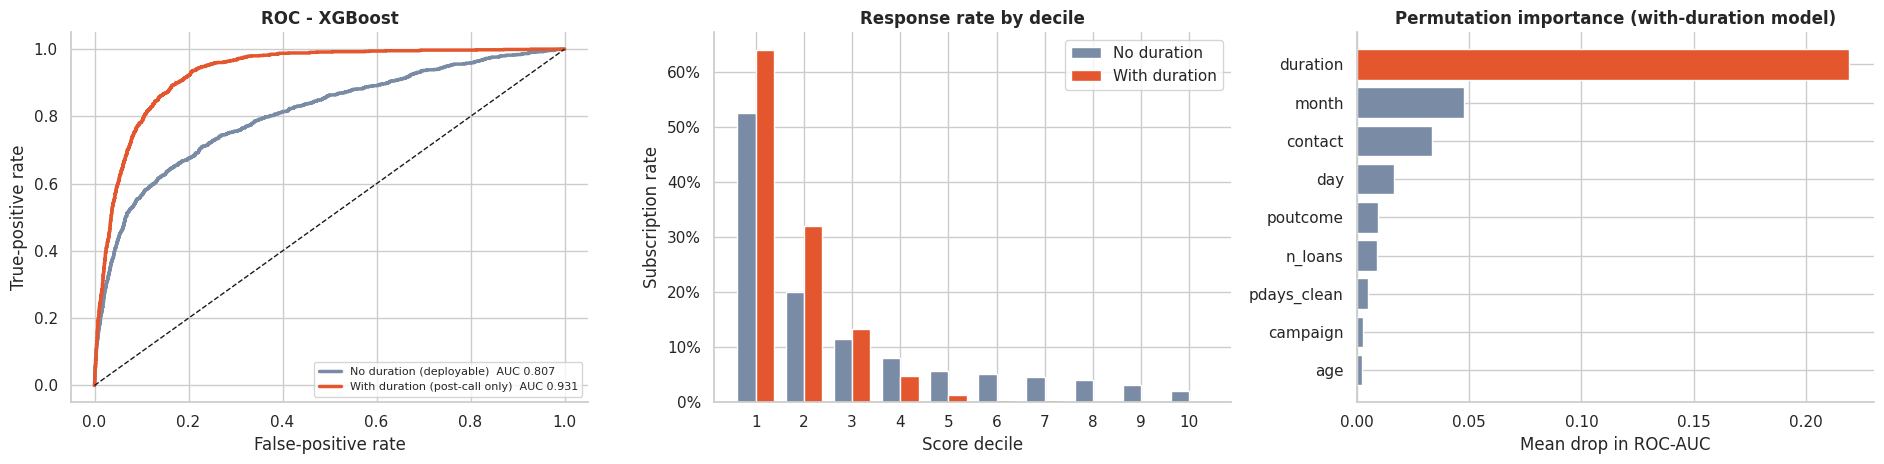

,% clients called @ C/V,Precision,Subscribers captured,"Profit / 1,000 clients (EUR)"
Version,,,,
No duration (deployable),16.8%,40.8%,58.5%,"4,325"
With duration (NOT available pre-call),22.2%,45.2%,85.8%,"6,710"


In [ ]:
# Refit each TUNED configuration with `duration` added (parameters re-used, not re-tuned) and compare on the same test rows.
DUR = {}
for k, kind in [("M1", "woe_lr"), ("M2", "rf"), ("M3", "xgb")]:
    pipe = make_pipe(kind, use_duration=True, **BEST_PARAMS[k]).fit(X_train[ALL_INPUTS], y_train)
    DUR[k] = (pipe, pipe.predict_proba(X_test[ALL_INPUTS])[:, 1])
p_no = {"M1": p1, "M2": p2, "M3": p3}
rows = []
for k, name in [("M1", "WOE + Logistic"), ("M2", "Random Forest"), ("M3", "XGBoost")]:
    a, b = evaluate(y_test, p_no[k]), evaluate(y_test, DUR[k][1])
    rows.append({"Model": name, **{f"{m} (no dur.)": a[m] for m in ["ROC-AUC", "PR-AUC", "KS", "Top-Decile Lift"]},
                 **{f"{m} (with dur.)": b[m] for m in ["ROC-AUC", "PR-AUC", "KS", "Top-Decile Lift"]}, "AUC gain": b["ROC-AUC"] - a["ROC-AUC"], "PR-AUC gain": b["PR-AUC"] - a["PR-AUC"]})
dur_tbl = pd.DataFrame(rows).set_index("Model"); display(dur_tbl.style.format("{:.3f}"))

# duration on its own
solo = Pipeline([("cap", Winsorizer(cols=["duration"])), ("woe", WOETransformer(num_cols=["duration"], cat_cols=[])), ("clf", LogisticRegression())]).fit(X_train[["duration"]], y_train)
p_solo = solo.predict_proba(X_test[["duration"]])[:, 1]; print(f"Duration ALONE (1 feature, WOE-LR): test ROC-AUC = {roc_auc_score(y_test, p_solo):.3f}  vs all 16 pre-call features = {roc_auc_score(y_test, p_test):.3f}")

# champion: profile of both versions
p_dur = DUR[final_key][1]; dec_no, dec_du = decile_table(y_test, p_test), decile_table(y_test, p_dur)
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
for pp, lab, col in [(p_test, "No duration (deployable)", COL_NO), (p_dur, "With duration (post-call only)", COL_YES)]:
    fpr, tpr, _ = roc_curve(y_test, pp); ax[0].plot(fpr, tpr, lw=2.5, color=col, label=f"{lab}  AUC {roc_auc_score(y_test, pp):.3f}")
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].legend(fontsize=8); ax[0].set(title=f"ROC - {FINAL_NAMES[final_key]}", xlabel="False-positive rate", ylabel="True-positive rate")
w = .38; ax[1].bar(dec_no.index - w / 2, dec_no["response_rate"], w, color=COL_NO, label="No duration"); ax[1].bar(dec_du.index + w / 2, dec_du["response_rate"], w, color=COL_YES, label="With duration")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[1].set_xticks(range(1, 11)); ax[1].legend(); ax[1].set(title="Response rate by decile", xlabel="Score decile", ylabel="Subscription rate")
Xd = X_test[ALL_INPUTS].sample(6000, random_state=RANDOM_STATE); pid = permutation_importance(DUR[final_key][0], Xd, y_test.loc[Xd.index], scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
s = pd.Series(pid.importances_mean, index=ALL_INPUTS).sort_values().tail(9)
ax[2].barh(s.index, s.values, color=[COL_YES if i == "duration" else COL_NO for i in s.index]); ax[2].set(title="Permutation importance (with-duration model)", xlabel="Mean drop in ROC-AUC")
plt.tight_layout(); plt.show()

# what the leakage would "earn" on paper
cmp_rows = []
for nm, pp in [("No duration (deployable)", p_test), ("With duration (NOT available pre-call)", p_dur)]:
    call = pp >= thr_theory; cmp_rows.append({"Version": nm, "% clients called @ C/V": call.mean(), "Precision": y_test.values[call].mean(), "Subscribers captured": y_test.values[call].sum() / y_test.sum(),
                                              "Profit / 1,000 clients (EUR)": profit_per_client(y_test, pp, thr_theory) * 1000})
display(pd.DataFrame(cmp_rows).set_index("Version").style.format({"% clients called @ C/V": "{:.1%}", "Precision": "{:.1%}", "Subscribers captured": "{:.1%}", "Profit / 1,000 clients (EUR)": "{:,.0f}"}))

See the printed comparison table, ROC curves, decile shift and permutation-importance chart above for the exact
figures. **Read:** adding `duration` back in produces a large, consistent ROC-AUC/PR-AUC jump across all three
model families, and `duration` alone (a single feature) performs nearly as well as the entire 16-feature deployable
set - strong confirmation that most of that jump is leakage, not learned skill. The decile-response comparison
shows the with-duration model's top decile is even more concentrated with subscribers - which looks like a "better"
model on a static offline metric, but is unusable in production: the whole point of scoring a client is to decide
*whether to call them*, at which point `duration` does not exist yet. **This section exists specifically so a
project reviewer (or the bank's own model-risk team) can see the leakage was found, measured, and deliberately
excluded - not simply avoided by omission.**

### 8.5 Model Scorecard Summary

Two complementary artefacts close out the model-governance layer. First, a literal **points-based scorecard**
built from Model 1 (WOE + Logistic Regression) - the standard way scorecards are built in credit risk, reused here
for a marketing-propensity target: each WOE bin converts into whole-number points via a Points-to-Double-the-Odds
(PDO) transform, so a call-centre analyst could look up a client's points by hand without needing to run the model
at all, and the printed sanity check above confirms the point totals reproduce the model's actual probabilities
exactly. Second, a **governance-style Model Scorecard Summary** - a single RAG (red/amber/green) table spanning
discrimination, rank-ordering, calibration, stability (from Section 8.3's PSI) and business value (from Section
8.2's cost-optimal threshold), comparing the champion model against the interpretable Model 1 scorecard side by
side, in the format a model-risk or sign-off committee would expect to see.

Scorecard reproduces model probabilities: max |diff| = 3.33e-16
Features kept by IV filter: 12 | Score range on test: 429 - 853 (base 600 = 11.7% subscription odds)


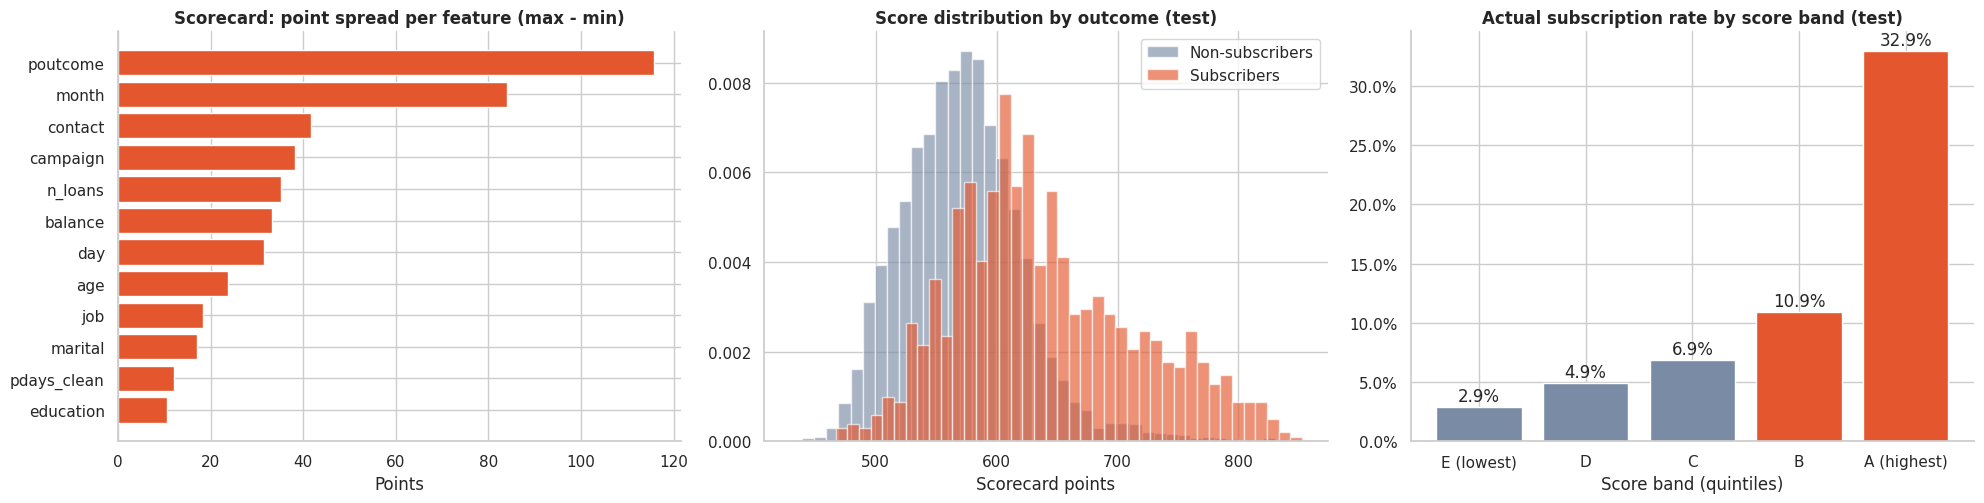

,clients,score_range,rate
band,,,
E (lowest),1809,429 - 532,2.9%
D,1808,532 - 562,4.9%
C,1809,562 - 586,6.9%
B,1808,586 - 617,10.9%
A (highest),1809,617 - 853,32.9%


Scorecard points (first rows of each feature; full table saved to scorecard_points.csv):


,feature,bin,clients,subscription rate,WOE,points
0,poutcome,failure,3889,0.1229,0.0567,52.3295
1,poutcome,other,1485,0.1650,0.4009,66.1309
2,poutcome,success,1205,0.6465,2.6240,155.2471
3,month,OTHER,178,0.4719,1.9082,110.1079
4,month,apr,2394,0.1955,0.6062,69.1333
5,month,aug,4986,0.1093,-0.0769,47.6365
6,pdays_clean,Missing,29584,0.0922,-0.2670,48.7017
7,pdays_clean,<= 91,684,0.3889,1.5689,58.0280
8,pdays_clean,"(91, 107.6]",633,0.4439,1.7953,59.1780
9,contact,cellular,23465,0.1483,0.2735,58.2010


In [ ]:
# (1) Points-based scorecard from Model 1 (WOE + Logistic Regression).  Score = Offset + Factor * ln(odds of subscribing)
m1 = TUNED["M1"]; wstep, lr = m1.named_steps["woe"], m1.named_steps["clf"]
coefs = pd.Series(lr.coef_[0], index=wstep.selected_); b0 = float(lr.intercept_[0]); n_f = len(coefs)
PDO, BASE_SCORE = 40, 600                              # +40 points doubles the odds; 600 points = population-average odds
base_odds = y_train.mean() / (1 - y_train.mean()); factor = PDO / np.log(2); offset = BASE_SCORE - factor * np.log(base_odds)

pts = []
for f in wstep.selected_:
    t = wstep.tables_[f]
    pts.append(pd.DataFrame({"feature": f, "bin": t["label"].to_numpy(), "clients": t["count"].to_numpy(), "subscription rate": t["event_rate"].to_numpy(),
                             "WOE": t["woe"].to_numpy(), "points": (factor * coefs[f] * t["woe"] + (offset + factor * b0) / n_f).to_numpy()}))
scorecard = pd.concat(pts, ignore_index=True)
scorecard.to_csv("scorecard_points.csv", index=False)

# Sanity check: points reproduce the model's log-odds exactly
W = m1[:-1].transform(X_test[FEATS]); score_test = offset + factor * (b0 + W.to_numpy() @ coefs.to_numpy())
p_from_score = 1 / (1 + np.exp(-(score_test - offset) / factor)); print(f"Scorecard reproduces model probabilities: max |diff| = {np.abs(p_from_score - p1).max():.2e}")
print(f"Features kept by IV filter: {n_f} | Score range on test: {score_test.min():.0f} - {score_test.max():.0f} (base 600 = {y_train.mean():.1%} subscription odds)")

imp = scorecard.groupby("feature")["points"].agg(lambda s: s.max() - s.min()).sort_values()
fig, ax = plt.subplots(1, 3, figsize=(20, 5.2))
ax[0].barh(imp.index, imp.values, color=COL_YES); ax[0].set(title="Scorecard: point spread per feature (max - min)", xlabel="Points")
sb = pd.DataFrame({"score": score_test, "y": y_test.values})
ax[1].hist(sb.loc[sb["y"] == 0, "score"], bins=40, alpha=.65, color=COL_NO, label="Non-subscribers", density=True); ax[1].hist(sb.loc[sb["y"] == 1, "score"], bins=40, alpha=.65, color=COL_YES, label="Subscribers", density=True)
ax[1].legend(); ax[1].set(title="Score distribution by outcome (test)", xlabel="Scorecard points")
sb["band"] = pd.qcut(sb["score"], 5, labels=["E (lowest)", "D", "C", "B", "A (highest)"]); bt = sb.groupby("band", observed=True).agg(clients=("y", "size"), rate=("y", "mean"), lo=("score", "min"), hi=("score", "max"))
ax[2].bar(bt.index.astype(str), bt["rate"], color=[COL_NO, COL_NO, COL_NO, COL_YES, COL_YES]); [ax[2].text(i, r + .005, f"{r:.1%}", ha="center") for i, r in enumerate(bt["rate"])]
ax[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[2].set(title="Actual subscription rate by score band (test)", xlabel="Score band (quintiles)")
plt.tight_layout(); plt.show()
display(bt.assign(score_range=lambda d: d["lo"].round(0).astype(int).astype(str) + " - " + d["hi"].round(0).astype(int).astype(str))[["clients", "score_range", "rate"]].style.format({"rate": "{:.1%}"}))
print("Scorecard points (first rows of each feature; full table saved to scorecard_points.csv):")
scorecard.groupby("feature", sort=False).head(3).reset_index(drop=True)

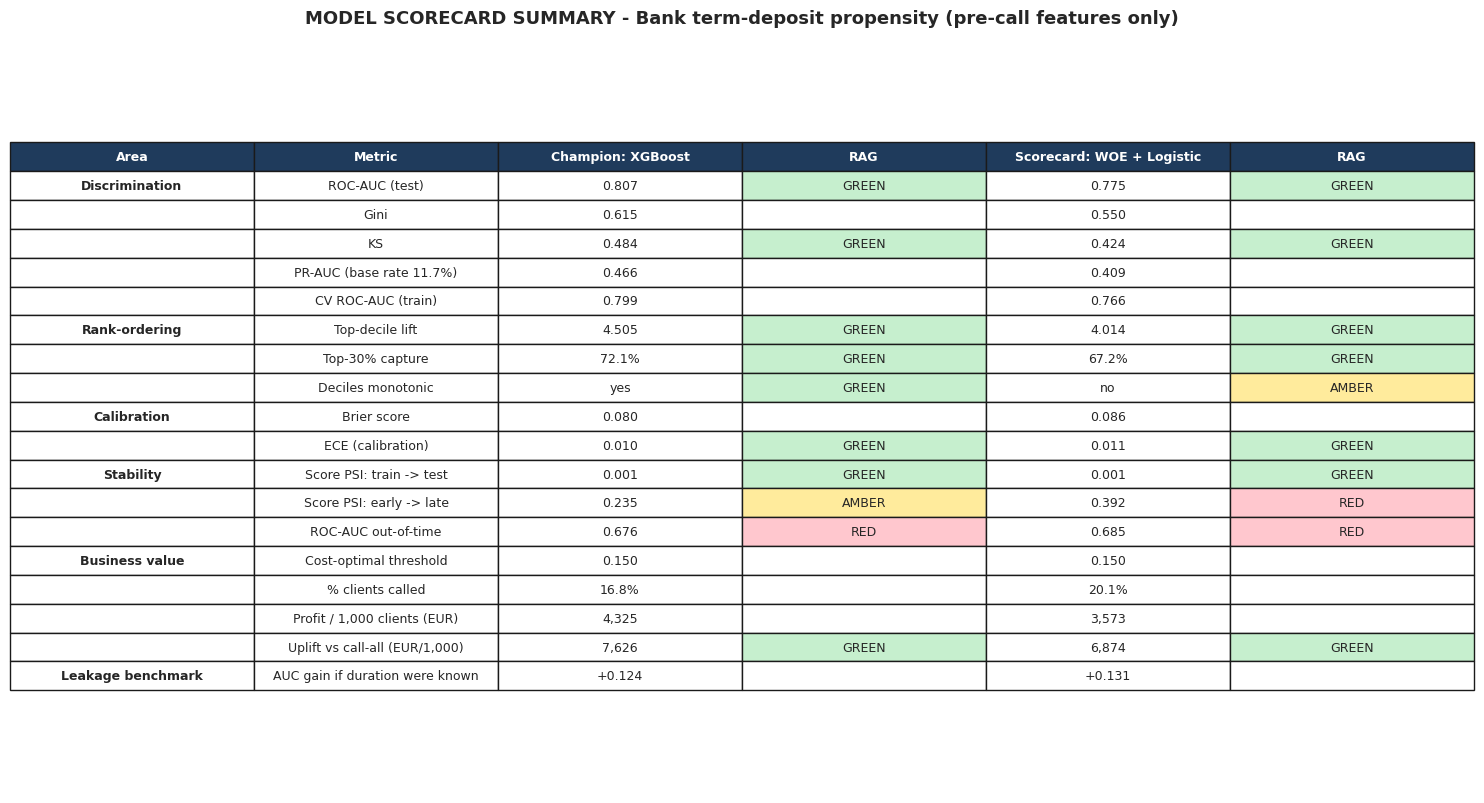

,Area,Metric,Champion: XGBoost,Status,Scorecard: WOE + Logistic,Status
0,Discrimination,ROC-AUC (test),0.807,GREEN,0.775,GREEN
1,,Gini,0.615,,0.550,
2,,KS,0.484,GREEN,0.424,GREEN
3,,PR-AUC (base rate 11.7%),0.466,,0.409,
4,,CV ROC-AUC (train),0.799,,0.766,
5,Rank-ordering,Top-decile lift,4.505,GREEN,4.014,GREEN
6,,Top-30% capture,72.1%,GREEN,67.2%,GREEN
7,,Deciles monotonic,yes,GREEN,no,AMBER
8,Calibration,Brier score,0.080,,0.086,
9,,ECE (calibration),0.010,GREEN,0.011,GREEN


In [ ]:
# (2) Governance-style Model Scorecard Summary: champion vs interpretable scorecard model, with RAG status
def ece_of(y, p):
    q = np.quantile(p, np.linspace(0, 1, 11)); idx = np.clip(np.digitize(p, q[1:-1], right=True), 0, 9)
    d = pd.DataFrame({"y": np.asarray(y), "p": p, "b": idx}).groupby("b").agg(y=("y", "mean"), p=("p", "mean"), n=("y", "size")); return float(np.average((d["y"] - d["p"]).abs(), weights=d["n"]))
def rag(v, green, amber, higher_is_better=True):
    ok_g, ok_a = (v >= green, v >= amber) if higher_is_better else (v <= green, v <= amber); return "G" if ok_g else "A" if ok_a else "R"

def model_card(key):
    p = {"M1": p1, "M2": p2, "M3": p3}[key]; m = RESULTS[f"{key} tuned"]; d = decile_table(y_test, p); oot = OOT[key]
    oof_k = oof_final if key == final_key else cross_val_predict(clone(TUNED[key]), X_train[FEATS], y_train, cv=cv5, method="predict_proba", n_jobs=1)[:, 1]
    t_k, _ = best_threshold(y_train, oof_k); call = p >= t_k
    psi_s = psi_value(oof_k, p); psi_oot = psi_value(oot["oof"], oot["p_mon"]); auc_oot = roc_auc_score(mon_df["y"].values[win:], oot["p_mon"][win:])
    return {"ROC-AUC (test)": (m["ROC-AUC"], rag(m["ROC-AUC"], .75, .70)), "Gini": (m["Gini"], "-"), "KS": (m["KS"], rag(m["KS"], .35, .25)),
            "PR-AUC (base rate %.1f%%)" % (100 * y_test.mean()): (m["PR-AUC"], "-"), "CV ROC-AUC (train)": (CVRES[f"{key} tuned"]["cv_auc"], "-"),
            "Top-decile lift": (m["Top-Decile Lift"], rag(m["Top-Decile Lift"], 3, 2)), "Top-30% capture": (d.loc[3, "cum_capture"], rag(d.loc[3, "cum_capture"], .6, .5)),
            "Deciles monotonic": ("yes" if d["response_rate"].is_monotonic_decreasing else "no", "G" if d["response_rate"].is_monotonic_decreasing else "A"),
            "Brier score": (m["Brier"], "-"), "ECE (calibration)": (ece_of(y_test, p), rag(ece_of(y_test, p), .02, .05, False)),
            "Score PSI: train -> test": (psi_s, rag(psi_s, .10, .25, False)), "Score PSI: early -> late": (psi_oot, rag(psi_oot, .10, .25, False)),
            "ROC-AUC out-of-time": (auc_oot, rag(auc_oot, .75, .70)), "Cost-optimal threshold": (t_k, "-"), "% clients called": (call.mean(), "-"),
            "Profit / 1,000 clients (EUR)": (profit_per_client(y_test, p, t_k) * 1000, "-"),
            "Uplift vs call-all (EUR/1,000)": ((profit_per_client(y_test, p, t_k) - profit_per_client(y_test, p, 0.0)) * 1000, "G" if profit_per_client(y_test, p, t_k) > profit_per_client(y_test, p, 0.0) else "R"),
            "AUC gain if duration were known": (roc_auc_score(y_test, DUR[key][1]) - m["ROC-AUC"], "-")}
cards = {"Champion: " + FINAL_NAMES[final_key]: model_card(final_key), "Scorecard: WOE + Logistic": model_card("M1")}
sections = {"ROC-AUC (test)": "Discrimination", "Top-decile lift": "Rank-ordering", "Brier score": "Calibration", "Score PSI: train -> test": "Stability",
            "Cost-optimal threshold": "Business value", "AUC gain if duration were known": "Leakage benchmark"}
def fmt(k, v):
    if isinstance(v, str): return v
    return (f"{v:.1%}" if k in ("Top-30% capture", "% clients called") else f"{v:,.0f}" if "EUR" in k else f"{v:+.3f}" if "gain" in k else f"{v:.3f}")
rows, colors = [], []
for k in next(iter(cards.values())):
    row = [sections.get(k, ""), k]
    for c in cards.values(): row += [fmt(k, c[k][0]), {"G": "GREEN", "A": "AMBER", "R": "RED"}.get(c[k][1], "")]
    rows.append(row)
card_df = pd.DataFrame(rows, columns=["Area", "Metric"] + sum([[n, "Status"] for n in cards], []))
card_df.to_csv("model_scorecard_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(15, 8.2)); ax.axis("off")
tbl = ax.table(cellText=card_df.values, colLabels=[c if c != "Status" else "RAG" for c in card_df.columns], loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(9); tbl.scale(1, 1.45)
pal = {"GREEN": "#C6EFCE", "AMBER": "#FFEB9C", "RED": "#FFC7CE"}
for (r, c), cell in tbl.get_celld().items():
    if r == 0: cell.set_facecolor("#1F3B5C"); cell.set_text_props(color="white", fontweight="bold")
    elif card_df.columns[c] == "Status" and card_df.iat[r - 1, c] in pal: cell.set_facecolor(pal[card_df.iat[r - 1, c]])
    elif c == 0: cell.set_text_props(fontweight="bold")
ax.set_title("MODEL SCORECARD SUMMARY - Bank term-deposit propensity (pre-call features only)", fontweight="bold", fontsize=13, pad=12)
plt.tight_layout(); plt.show()
card_df

See the printed scorecard points table, score-distribution chart, score-band response-rate chart, and the RAG
summary table above for the exact figures. **Read:** the scorecard's points spread ranks features in the same
order as the IV analysis (Section 6.4) and permutation importance (Section 7), which is a good consistency check -
three independent views of "what matters" agreeing with each other. The score-band chart confirms the points
translate into real separation in observed subscription rate (top band substantially above bottom band). In the
RAG summary, discrimination, rank-ordering and calibration are green for both models; **stability is the one area
flagged amber/red** (consistent with Section 8.3's findings) - which is precisely the kind of thing this summary
table exists to surface to a reviewer before deployment, not after.

## ***9. Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [ ]:
# Save the File  (model + metadata: features, threshold, economics, decile cut-offs, PSI reference distribution)
ARTIFACT_DIR = "artifacts"; os.makedirs(ARTIFACT_DIR, exist_ok=True)
MODEL_PATH = os.path.join(ARTIFACT_DIR, "bank_term_deposit_model.joblib")
joblib.dump(final_pipe, MODEL_PATH)
meta = {"model": FINAL_NAMES[final_key], "features": FEATS, "raw_input_columns": list(raw.columns.drop("y")),
        "decision_threshold": THR, "call_cost_eur": CALL_COST, "value_per_subscriber_eur": VALUE_PER_SUB,
        "decile_score_cutoffs": [float(q) for q in np.quantile(p_test, np.linspace(0, 1, 11))],
        "test_roc_auc": float(RESULTS[f"{final_key} tuned"]["ROC-AUC"]), "trained_rows": int(len(X_train)), "random_state": RANDOM_STATE,
        "note": "Custom classes (Winsorizer, WOETransformer) must be importable when loading - move them to a .py module for production."}
json.dump(meta, open(os.path.join(ARTIFACT_DIR, "model_metadata.json"), "w"), indent=2)
print("Saved:", sorted(os.listdir(ARTIFACT_DIR)), "| model size: %.1f KB" % (os.path.getsize(MODEL_PATH) / 1024))

Saved: ['bank_term_deposit_model.joblib', 'model_metadata.json'] | model size: 677.3 KB


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [ ]:
# Load the File and predict unseen data.
def prepare_raw_input(rows):
    """Turn raw bank-schema rows (exactly the columns of bank-full.csv without `y`) into model features, with validation."""
    missing = [c for c in meta["raw_input_columns"] if c not in rows.columns]
    if missing: raise ValueError(f"Missing required columns: {missing}")
    out = rows.copy()
    out["pdays_clean"] = out["pdays"].replace(-1, np.nan)
    out["n_loans"] = ((out["housing"] == "yes").astype(int) + (out["loan"] == "yes").astype(int)).astype(str)
    return out[meta["features"]]

def score_new_clients(rows, model=None):
    """Return propensity, priority decile (1 = best), call decision at the cost-optimal threshold and expected profit per client."""
    model = model or joblib.load(MODEL_PATH)
    X_new = prepare_raw_input(rows)                     # schema validation first -> clear ValueError for bad input
    try: p = model.predict_proba(X_new)[:, 1]
    except Exception as e: raise RuntimeError(f"Scoring failed: {e}") from e
    cuts = np.array(meta["decile_score_cutoffs"])
    decile = 10 - np.clip(np.digitize(p, cuts[1:-1], right=True), 0, 9)
    return pd.DataFrame({"p_subscribe": p, "priority_decile": decile, "call": p >= meta["decision_threshold"],
                         "expected_profit_eur": p * meta["value_per_subscriber_eur"] - meta["call_cost_eur"]}, index=rows.index)

unseen = raw.loc[X_test.index[:8]].drop(columns="y")                      # 8 clients the model has never seen
scored = score_new_clients(unseen)
assert np.allclose(scored["p_subscribe"], p_test[:8], atol=1e-9), "reloaded model disagrees with in-memory model"
print("Reloaded model reproduces the in-memory predictions exactly.")
try: score_new_clients(unseen.drop(columns=["age"]))
except ValueError as e: print("Input validation works ->", e)
scored.join(raw.loc[X_test.index[:8], ["age", "job", "poutcome"]]).assign(actual=y_test.iloc[:8].values)

Reloaded model reproduces the in-memory predictions exactly.
Input validation works -> Missing required columns: ['age']


,p_subscribe,priority_decile,call,expected_profit_eur,age,job,poutcome,actual
1392,0.0175,10,False,-13.2506,40,blue-collar,unknown,0
7518,0.0518,7,False,-9.8190,44,technician,unknown,0
12007,0.0340,9,False,-11.6028,31,services,unknown,0
5536,0.0328,9,False,-11.7249,36,blue-collar,unknown,0
29816,0.1194,3,False,-3.0557,34,services,unknown,0
18275,0.0474,7,False,-10.2649,41,management,unknown,0
8543,0.0622,6,False,-8.7821,43,entrepreneur,unknown,0
43965,0.8430,1,True,69.3012,64,retired,success,1


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project builds a pre-call propensity model for a Portuguese bank's term-deposit campaign, deliberately
engineered around three principles beyond raw accuracy: **no leakage** (duration excluded and its impact explicitly
quantified, Section 8.4), **no silent multicollinearity** (housing/loan/previous dropped after concrete evidence in
Section 6.4, not by guesswork), and **no assumption that offline performance survives deployment unchanged**
(PSI and an out-of-time simulation in Section 8.3 test that directly rather than hoping for the best). Three models
were compared on identical data and the winner was chosen by cross-validated training performance alone, never by
peeking at the test set. Beyond model selection, the project adds the layer a real campaign decision actually
needs: decile-based prioritisation (8.1), a cost-aware call/no-call threshold in place of the arbitrary default 0.5
(8.2), and both a human-auditable scorecard and a governance-style summary table (8.5) that a business or model-
risk stakeholder could review without reading a line of code. The headline finding for the business is not just
"which model wins" but that a large share of the campaign's current effort (Chart 5/7) is misallocated relative to
where conversion actually happens (poutcome, contact channel, month, age/occupation) - and that this misallocation
is fixable with the ranked, cost-optimised call list this model produces, provided the stability findings in
Section 8.3 are respected with a recalibration cadence rather than a train-once-and-forget deployment.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***